# Analisis Pola dan Prediksi Churn Pelanggan Netflix
**Proyek Akhir Praktikum Data Science** — Prodi Informatika, UPN "Veteran" Yogyakarta (Semester Ganjil 2026/2027)

**Judul:** Analisis Pola Churn Pelanggan Netflix Berdasarkan Perilaku Menonton dan Karakteristik Langganan Menggunakan Data Mining: Studi pada Dataset 5.000 Pelanggan

Notebook ini berisi alur lengkap CRISP-DM dari awal sampai akhir, dengan hasil dan penjelasan tertulis di setiap langkah:

| # | Tahap | Isi singkat |
|---|---|---|
| 1 | Business Understanding | masalah, pertanyaan, metode, metrik, kriteria berhasil |
| 2 | Data Gathering | sumber dan tautan, lisensi, arti tiap kolom, alasan memilih dataset |
| 3 | EDA | statistik deskriptif, visualisasi, dan temuan di bawah tiap visual |
| 4 | Cleaning dan Preprocessing | audit, penanganan data, sebelum vs sesudah, split, encoding, scaling, feature selection |
| 5 | Modelling | pilihan model beserta alasannya, test design, tuning, perbandingan antar model, log iterasi |
| 6 | Evaluasi | metrik uji, matriks konfusi, kurva ROC dan PR, pemilihan model terbaik, ringkasan terhadap kriteria berhasil |
| 7 | Konklusi | jawaban pertanyaan bisnis, arti metrik, keputusan, keterbatasan, rencana deployment (di atas kertas), review proses dan proyek |

**Cara menjalankan:** letakkan notebook sejajar dengan folder `data/`, pasang dependensi (`pip install -r requirements.txt`), lalu *Kernel → Restart & Run All* (sekitar 5 menit). Gambar tersimpan di `figures/` dan tabel di `outputs/`. Seed acak tetap 42.

> **Catatan penting tentang data:** dataset ini diindikasikan **sintetis** (dibahas di bagian 3.9). Semua temuan adalah asosiasi pada dataset ini, bukan fakta tentang pelanggan Netflix yang sebenarnya.

In [1]:
import os, json, warnings
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from IPython.display import display, Markdown

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate, cross_val_predict
from sklearn.preprocessing import StandardScaler, OneHotEncoder, OrdinalEncoder, FunctionTransformer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import (roc_auc_score, accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, roc_curve, precision_recall_curve, average_precision_score)

SEED = 42
DATA_PATH = "data/netflix_customer_churn.csv"
os.makedirs("figures", exist_ok=True); os.makedirs("outputs", exist_ok=True)
sns.set_theme(style="whitegrid", font_scale=0.95)
RED, TEAL, BLUE, ORANGE, GREY = "#E63946", "#2A9D8F", "#457B9D", "#F4A261", "#9AA0A6"
HASIL = {}   # ringkasan angka kunci, disimpan ke outputs/hasil_ringkas.json di akhir notebook

def savefig(name):
    plt.tight_layout(); plt.savefig(f"figures/{name}", dpi=170, bbox_inches="tight"); plt.show()
def tampil(teks): display(Markdown(teks))
def idn(x, d=2, ribu=False):
    """format angka gaya Indonesia: koma desimal, titik ribuan (hanya untuk teks narasi)"""
    s = f"{x:,.{d}f}" if ribu else f"{x:.{d}f}"
    return s.replace(",", "§").replace(".", ",").replace("§", ".")

---
# 1. Business Understanding

## 1.1 Masalah
Layanan streaming berbasis langganan hidup dari pendapatan berulang. Ketika pelanggan berhenti berlangganan (*churn*), pendapatan hilang, dan mendapatkan pelanggan pengganti jauh lebih mahal daripada mempertahankan pelanggan yang sudah ada. Pengelola layanan perlu tahu **pelanggan seperti apa yang cenderung churn** dan **sinyal apa yang muncul sebelum churn**, supaya kampanye retensi tidak dilakukan secara acak.

Pada dataset yang dipakai, 2.515 dari 5.000 pelanggan (50,3 %) berstatus churn, dan akun churn mewakili sekitar USD 33.010 dari USD 68.417 biaya langganan bulanan (48,2 %).

## 1.2 Pertanyaan yang ingin dijawab
1. **P1.** Pola perilaku menonton dan karakteristik langganan apa yang berasosiasi dengan churn?
2. **P2.** Variabel mana yang berasosiasi paling kuat, dan mana yang tidak berasosiasi (sehingga tidak layak dijadikan dasar segmentasi)?
3. **P3.** Seberapa baik churn dapat diprediksi, dan model mana yang paling layak dipakai?
4. **P4.** Pelanggan aktif seperti apa yang paling berisiko churn, dan berapa pendapatan bulanan yang berisiko (*revenue-at-risk*)?

## 1.3 Metode
Alur CRISP-DM. EDA dengan statistik deskriptif, uji chi-square (kategorikal), uji Mann-Whitney U (numerik), Cramér's V, dan korelasi Spearman (taraf signifikansi 5 %). Prediksi dengan **klasifikasi biner** (target `churned`). Model yang dibandingkan: *baseline* majority-class, Logistic Regression, Random Forest, dan Histogram Gradient Boosting, dengan validasi silang 5-lipatan pada data latih dan evaluasi akhir pada data uji hold-out 20 % (stratified).

## 1.4 Metrik dan kriteria berhasil
| Level | Metrik | Kriteria berhasil | Alasan |
|---|---|---|---|
| Model | **ROC-AUC** | ≥ 0,80 | mengukur kemampuan memisahkan churn vs aktif tanpa bergantung pada satu ambang keputusan |
| Model | **Recall kelas churn** (metrik utama) | ≥ 0,75 | biaya melewatkan pelanggan yang akan churn lebih besar daripada biaya menghubungi pelanggan yang sebenarnya tidak akan pergi |
| Model | Precision, F1, akurasi, matriks konfusi | di atas baseline 50,3 % | precision menjaga agar kampanye retensi tidak boros; akurasi dilaporkan karena kelas seimbang |
| Bisnis | Jumlah pelanggan aktif berisiko dan *revenue-at-risk* bulanan | segmen berisiko dapat didefinisikan dan dihitung nilainya | menerjemahkan model menjadi angka yang dipahami pemangku kepentingan |
| Proses | Reprodusibilitas | notebook dapat dijalankan ulang dan menghasilkan angka yang sama | seed tetap, parameter transformasi dipelajari dari data latih saja |

## 1.5 Asumsi dan batasan awal
- Satu baris = satu pelanggan unik. `churned = 1` berarti sudah berhenti berlangganan; `0` berarti masih aktif.
- `monthly_fee` dianggap USD (dataset tidak menyebut mata uang; 8,99 / 13,99 / 17,99).
- Tidak ada tanggal bergabung, tenure, atau tanggal churn. Periode pengukuran `watch_hours` dan waktu pencatatan `last_login_days` **tidak didokumentasikan**. Konsekuensinya: hanya asosiasi yang dapat disimpulkan, dan `last_login_days` berisiko menjadi akibat churn (*temporal leakage*). Risiko ini diuji eksplisit pada tahap Modelling.
- Atribut `age`, `gender`, `region` bersifat sensitif. Atribut ini hanya diperiksa asosiasinya dan tidak boleh dipakai untuk memperlakukan pelanggan secara berbeda. Skor churn tidak boleh dipakai untuk menaikkan harga secara selektif.

---
# 2. Data Gathering

## 2.1 Sumber, tautan, dan lisensi
| Item | Keterangan |
|---|---|
| Judul | Netflix Customer Churn & Engagement Analytics |
| Penyedia | Pengguna Kaggle `zeyadmohamed26` |
| Tautan | https://www.kaggle.com/datasets/zeyadmohamed26/netflix-customer-churn-and-engagement-analytics |
| Berkas | `netflix_customer_churn.csv` (545.934 byte, 5.000 baris × 14 kolom) |
| Tanggal akses | 10 Oktober 2026 |
| Lisensi | Apache 2.0 (metadata resmi Kaggle). Badge pada deskripsi menyebut CC0 1.0, sehingga ada ketidakkonsistenan; proyek ini mengikuti metadata resmi. Atribusi: zeyadmohamed26. (n.d.). *Netflix customer churn & engagement analytics* [Data set]. Kaggle. |

## 2.2 Tentang dataset
Dataset berisi 5.000 pelanggan layanan streaming dari enam wilayah, dengan atribut demografis (usia, gender, wilayah), langganan (paket, biaya, metode pembayaran, jumlah profil), perilaku (total jam tonton, hari sejak login terakhir, genre favorit, perangkat), dan label `churned`. Dokumentasi sumber pada halaman dataset sangat singkat: penyedia menyebutnya *benchmark* yang dikurasi, berisi metrik pelanggan agregat yang sudah dibersihkan, tanpa menyebut asal data primer, dan kolom sitasi kosong. Satu pertanyaan pengguna lain tentang cara data dikumpulkan atau dibangkitkan belum dijawab penyedia (halaman dicek 22 November 2026).

## 2.3 Kenapa dataset ini dipilih
- Topiknya (churn) punya nilai bisnis jelas dan umum dipakai sebagai kasus klasifikasi biner.
- Ukuran 5.000 baris × 14 kolom cukup untuk EDA, preprocessing, dan membandingkan beberapa model tanpa komputasi berat.
- Campuran kolom numerik dan kategorikal memungkinkan latihan encoding, scaling, dan seleksi fitur.
- Ada beberapa jebakan yang sengaja bisa diuji (kolom turunan, variabel yang berisiko bocor, indikasi data sintetis), sehingga proses berpikirnya bisa ditunjukkan.
- Dataset ini sudah dicatat pada spreadsheet pencatatan dataset dan diterima oleh asisten lab.

## 2.4 Arti setiap kolom (data dictionary)
| Kolom | Tipe | Arti | Catatan |
|---|---|---|---|
| `customer_id` | teks | ID unik pelanggan (UUID) | identifier, tidak dipakai sebagai fitur |
| `age` | integer | usia pelanggan (tahun) | rentang 18–70 |
| `gender` | kategorikal | Male / Female / Other | |
| `subscription_type` | kategorikal ordinal | paket: Basic < Standard < Premium | |
| `watch_hours` | numerik | total jam menonton | periode pengukuran tidak didokumentasikan |
| `last_login_days` | integer | hari sejak login terakhir | rentang 0–60; berisiko *leakage* |
| `region` | kategorikal | 6 wilayah | |
| `device` | kategorikal | 5 jenis perangkat | |
| `monthly_fee` | numerik | biaya langganan per bulan (diasumsikan USD) | berpadanan 1:1 dengan paket |
| `churned` | biner | **target**: 1 = churn, 0 = aktif | |
| `payment_method` | kategorikal | 5 metode pembayaran | |
| `number_of_profiles` | integer | jumlah profil dalam akun (1–5) | |
| `avg_watch_time_per_day` | numerik | rata-rata jam tonton per hari | kolom turunan: `round(watch_hours / (last_login_days + 1), 2)` |
| `favorite_genre` | kategorikal | 7 genre favorit | |

In [2]:
raw = pd.read_csv(DATA_PATH)
NUM = ["age", "watch_hours", "last_login_days", "monthly_fee", "number_of_profiles", "avg_watch_time_per_day"]
CAT = ["gender", "subscription_type", "region", "device", "payment_method", "favorite_genre"]
ORDER_SUB = ["Basic", "Standard", "Premium"]
print("Ukuran data:", raw.shape, "| ukuran berkas (byte):", os.path.getsize(DATA_PATH))
display(raw.head())
display(raw.dtypes.to_frame("tipe").join(raw.nunique().rename("nilai_unik")))
print("customer_id unik:", raw.customer_id.nunique(), "dari", len(raw))
print("monthly_fee per paket:", raw.groupby("subscription_type").monthly_fee.unique().to_dict())

Ukuran data: (5000, 14) | ukuran berkas (byte): 545934


,customer_id,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned,payment_method,number_of_profiles,avg_watch_time_per_day,favorite_genre
0,a9b75100-82a8-427a-a208-72f24052884a,51,Other,Basic,14.73,29,Africa,TV,8.99,1,Gift Card,1,0.49,Action
1,49a5dfd9-7e69-4022-a6ad-0a1b9767fb5b,47,Other,Standard,0.70,19,Europe,Mobile,13.99,1,Gift Card,5,0.03,Sci-Fi
2,4d71f6ce-fca9-4ff7-8afa-197ac24de14b,27,Female,Standard,16.32,10,Asia,TV,13.99,0,Crypto,2,1.48,Drama
3,d3c72c38-631b-4f9e-8a0e-de103cad1a7d,53,Other,Premium,4.51,12,Oceania,TV,17.99,1,Crypto,2,0.35,Horror
4,4e265c34-103a-4dbb-9553-76c9aa47e946,56,Other,Standard,1.89,13,Africa,Mobile,13.99,1,Crypto,2,0.13,Action


,tipe,nilai_unik
customer_id,str,5000
age,int64,53
gender,str,3
subscription_type,str,3
watch_hours,float64,2343
last_login_days,int64,61
region,str,6
device,str,5
monthly_fee,float64,3
churned,int64,2


customer_id unik: 5000 dari 5000
monthly_fee per paket: {'Basic': array([8.99]), 'Premium': array([17.99]), 'Standard': array([13.99])}


**Temuan pemuatan data.** Data terbaca utuh (5.000 baris, 14 kolom) dan setiap `customer_id` unik, sehingga asumsi "satu baris = satu pelanggan" terpenuhi. Biaya langganan hanya punya tiga nilai yang masing-masing tepat untuk satu paket, jadi `monthly_fee` dan `subscription_type` memuat informasi yang sama. Hal ini diperhitungkan saat seleksi fitur (bagian 4.5).

---
# 3. Exploratory Data Analysis (EDA)
Seluruh bagian EDA memakai data lengkap (5.000 baris) karena bersifat deskriptif dan tidak menghasilkan parameter yang dipakai model. Keputusan yang memengaruhi model (parameter scaling, seleksi fitur) baru diambil pada bagian 4 dari **data latih saja**.

## 3.1 Statistik deskriptif

In [3]:
d = raw[NUM].describe().T
desc = pd.DataFrame({"Rerata": d["mean"], "Std": d["std"], "Min": d["min"], "Q1": d["25%"], "Median": d["50%"],
                     "Q3": d["75%"], "Maks": d["max"], "Skewness": raw[NUM].skew()}).round(2)
desc.to_csv("outputs/statistik_deskriptif.csv"); display(desc)
by = raw.groupby("churned")[NUM].median().T.rename(columns={0: "Median aktif", 1: "Median churn"})
by["p Mann-Whitney"] = [stats.mannwhitneyu(raw.loc[raw.churned==1, c], raw.loc[raw.churned==0, c])[1] for c in NUM]
by.to_csv("outputs/median_menurut_churn.csv"); display(by.style.format({"p Mann-Whitney": "{:.2g}"}))
print("Jumlah pelanggan per number_of_profiles:", raw.number_of_profiles.value_counts().sort_index().to_dict())

,Rerata,Std,Min,Q1,Median,Q3,Maks,Skewness
age,43.85,15.50,18.00,30.00,44.00,58.00,70.00,0.01
watch_hours,11.65,12.01,0.01,3.34,8.00,16.03,110.40,2.26
last_login_days,30.09,17.54,0.00,15.00,30.00,45.00,60.00,-0.03
monthly_fee,13.68,3.69,8.99,8.99,13.99,17.99,17.99,-0.14
number_of_profiles,3.02,1.42,1.00,2.00,3.00,4.00,5.00,-0.02
avg_watch_time_per_day,0.87,2.62,0.00,0.11,0.29,0.72,98.42,15.83


churned,Median aktif,Median churn,p Mann-Whitney
age,44.000000,44.000000,0.78
watch_hours,13.860000,4.060000,0
last_login_days,19.000000,41.000000,1.9e-243
monthly_fee,13.990000,13.990000,1.4e-25
number_of_profiles,3.000000,3.000000,3.5e-29
avg_watch_time_per_day,0.720000,0.120000,0


Jumlah pelanggan per number_of_profiles: {1: 972, 2: 1001, 3: 994, 4: 999, 5: 1034}


**Temuan.** (1) `watch_hours` sangat miring ke kanan (skewness 2,26; median 8,00 jam tetapi maksimum 110,4 jam), dan `avg_watch_time_per_day` jauh lebih miring lagi (skewness 15,8). (2) `age`, `last_login_days`, dan `number_of_profiles` hampir seragam (skewness ≈ 0, tiap jumlah profil dimiliki sekitar 1.000 akun), pola yang jarang pada data nyata. (3) Pelanggan churn menonton jauh lebih sedikit (median 4,06 jam vs 13,86 jam) dan lebih lama tidak login (median 41 vs 19 hari), keduanya signifikan (p < 0,001). (4) `age` tidak berbeda (median sama 44 tahun, p = 0,78).

## 3.2 Distribusi target dan paket langganan

Churn 2515 (50.3%) | aktif 2485 | pendapatan akun churn USD 33,009.85 dari 68,417.00 (48.2%)
{'Basic': 61.8, 'Standard': 45.4, 'Premium': 43.7} {'Basic': 9232.73, 'Standard': 10464.52, 'Premium': 13312.6}


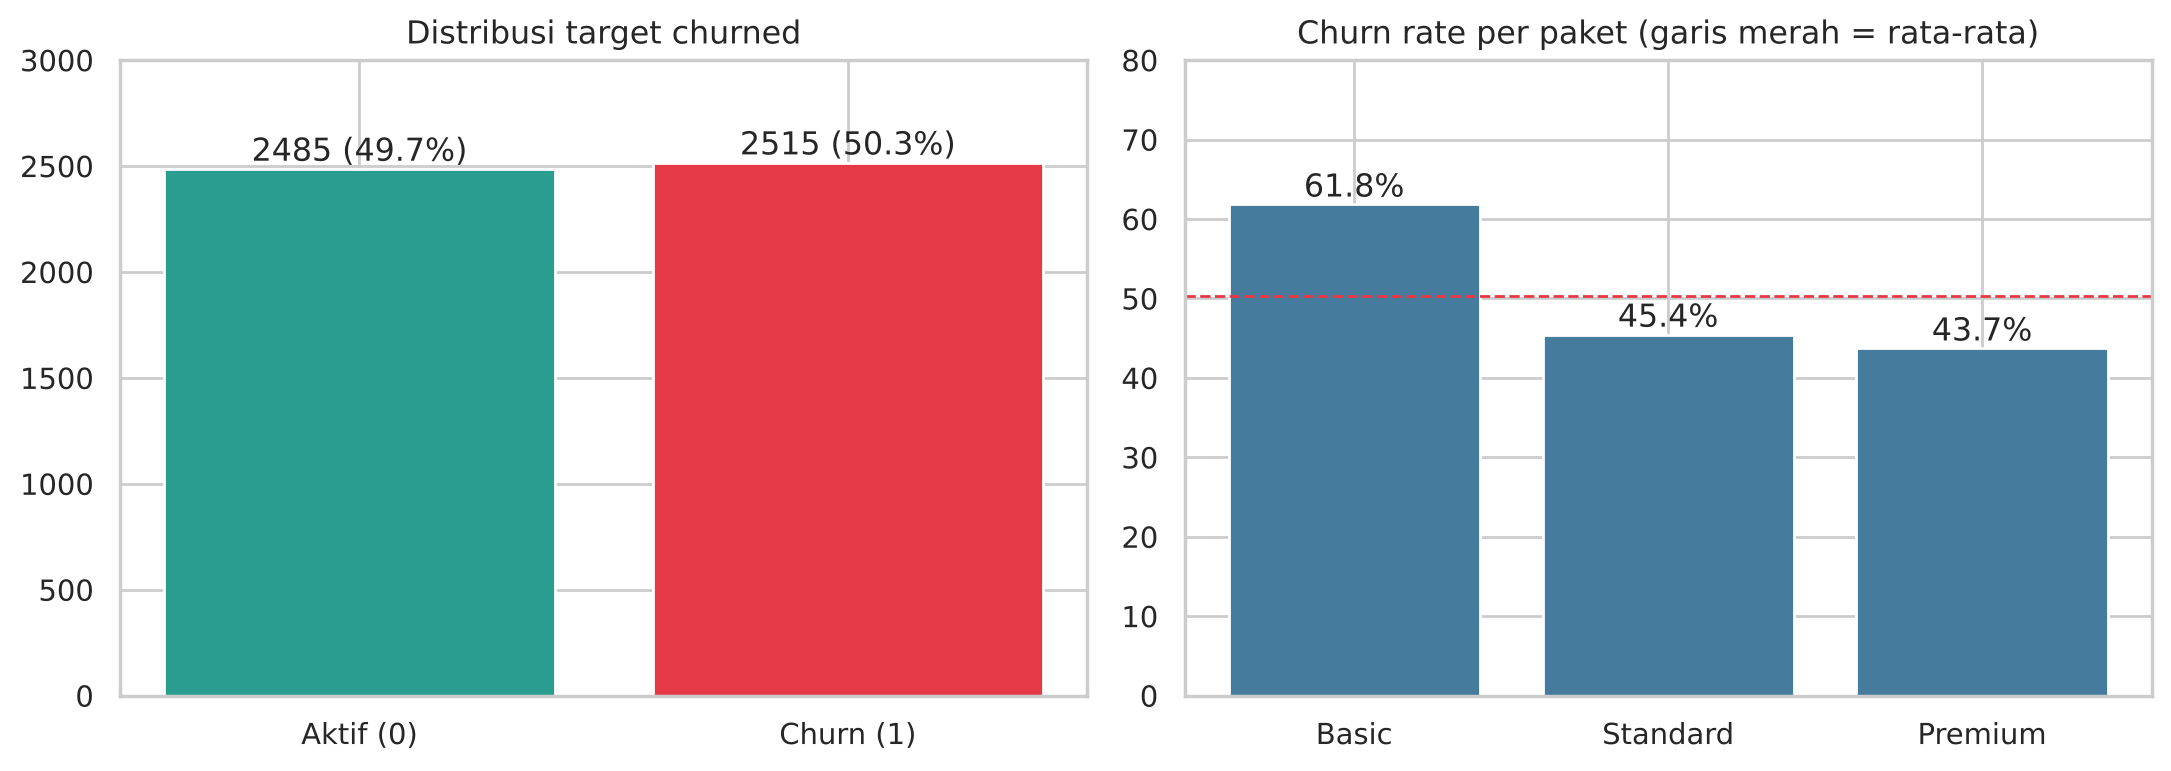

In [4]:
n_churn = int(raw.churned.sum()); n_aktif = len(raw) - n_churn
rate_sub = raw.groupby("subscription_type").churned.mean().reindex(ORDER_SUB) * 100
fee_churn = raw[raw.churned == 1].groupby("subscription_type").monthly_fee.sum().reindex(ORDER_SUB)
total_fee, churn_fee = raw.monthly_fee.sum(), raw.loc[raw.churned == 1, "monthly_fee"].sum()
print(f"Churn {n_churn} ({100*n_churn/len(raw):.1f}%) | aktif {n_aktif} | pendapatan akun churn USD {churn_fee:,.2f} dari {total_fee:,.2f} ({100*churn_fee/total_fee:.1f}%)")
print(rate_sub.round(1).to_dict(), fee_churn.round(2).to_dict())
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(["Aktif (0)", "Churn (1)"], [n_aktif, n_churn], color=[TEAL, RED])
for i, v in enumerate([n_aktif, n_churn]): ax[0].text(i, v + 40, f"{v} ({100*v/len(raw):.1f}%)", ha="center")
ax[0].set_title("Distribusi target churned"); ax[0].set_ylim(0, 3000)
ax[1].bar(ORDER_SUB, rate_sub.values, color=BLUE)
for i, v in enumerate(rate_sub): ax[1].text(i, v + 1, f"{v:.1f}%", ha="center")
ax[1].axhline(100*n_churn/len(raw), ls="--", color=RED, lw=1); ax[1].set_ylim(0, 80); ax[1].set_title("Churn rate per paket (garis merah = rata-rata)")
savefig("fig01_target_dan_paket.png")

**Temuan.** Kelas hampir seimbang (50,3 % churn : 49,7 % aktif), jadi akurasi tidak menyesatkan dan teknik penyeimbangan kelas kemungkinan tidak diperlukan (diuji di bagian 4.4). Paket **Basic churn 61,8 %**, jauh di atas Standard (45,4 %) dan Premium (43,7 %); Standard dan Premium nyaris sama. Namun dari sisi uang, akun Premium yang churn menyumbang pendapatan hilang terbesar (USD 13.313 vs Basic USD 9.233) karena biayanya lebih tinggi, sehingga prioritas retensi bergantung pada apakah yang dikejar jumlah akun atau nilai pendapatan.

## 3.3 Perilaku menonton: recency dan intensitas

{'0-7': 13.4, '8-14': 27.0, '15-30': 32.0, '31-45': 74.7, '46-60': 75.5}
{'Q1 (terendah)': 85.7, 'Q2': 73.1, 'Q3': 44.0, 'Q4': 40.5, 'Q5 (tertinggi)': 8.1}


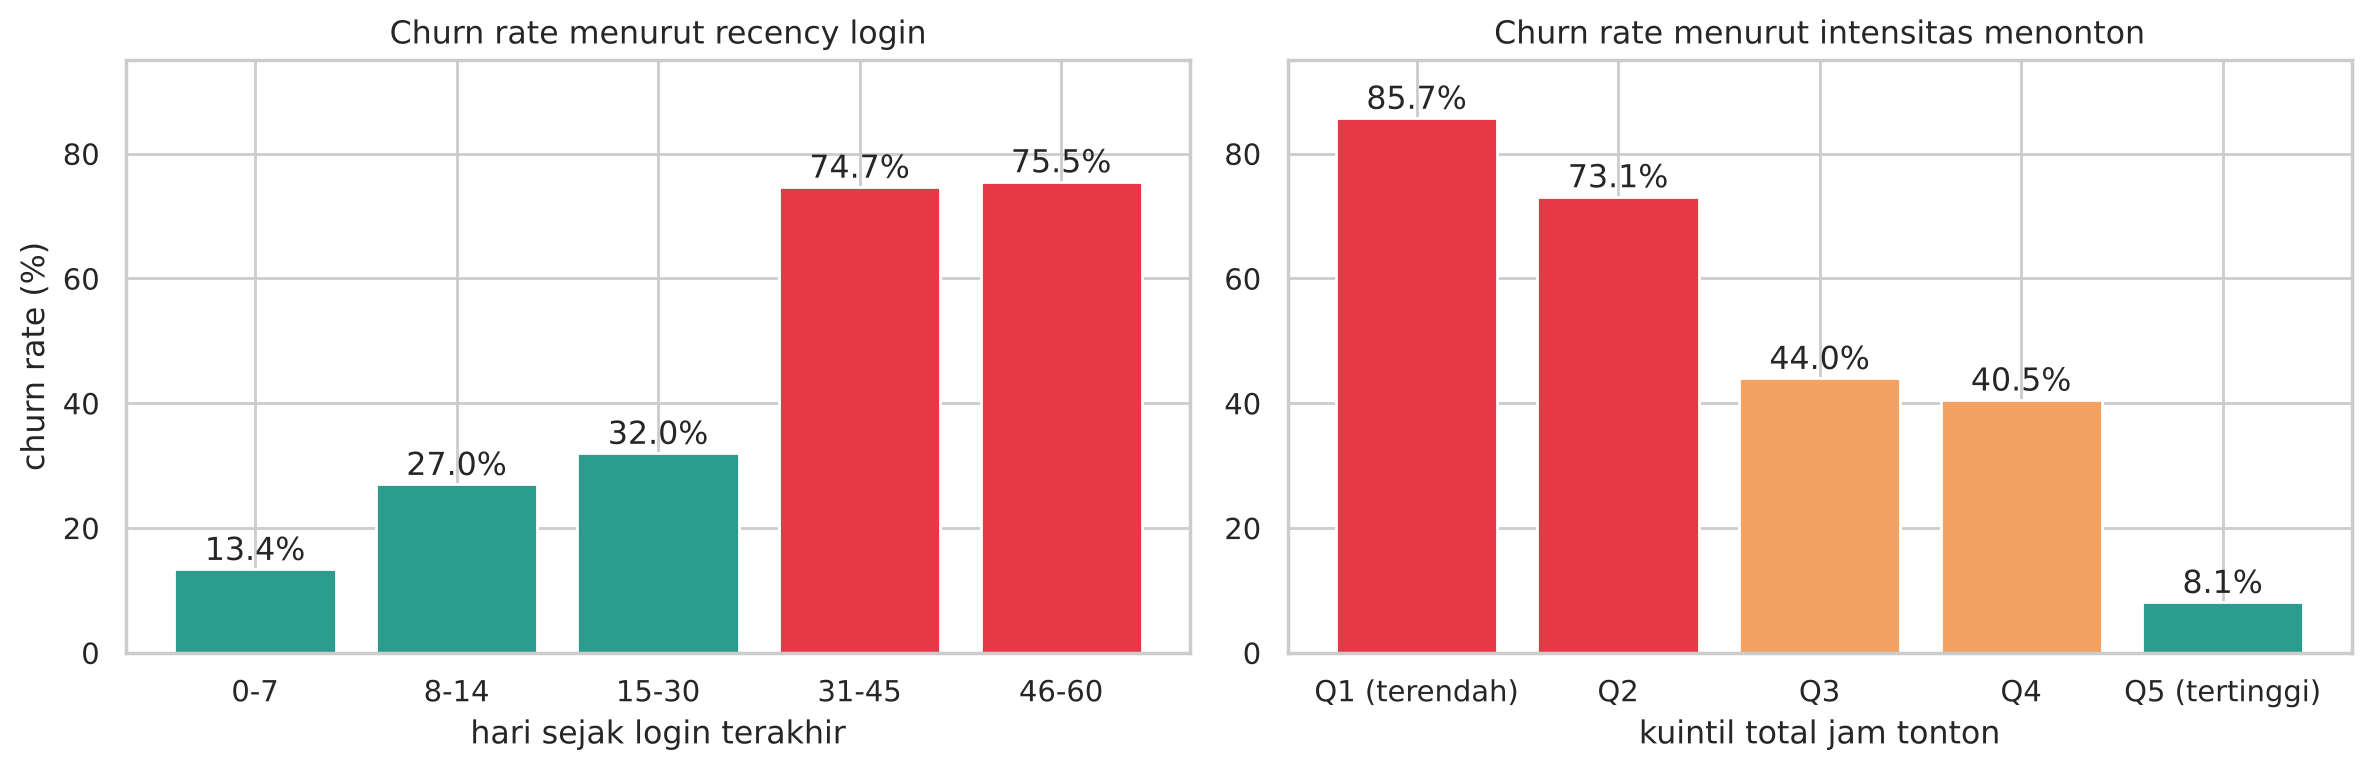

In [5]:
bins, labels = [-1, 7, 14, 30, 45, 60], ["0-7", "8-14", "15-30", "31-45", "46-60"]
rate_login = raw.groupby(pd.cut(raw.last_login_days, bins, labels=labels), observed=True).churned.mean() * 100
rate_watch = raw.groupby(pd.qcut(raw.watch_hours, 5, labels=["Q1 (terendah)", "Q2", "Q3", "Q4", "Q5 (tertinggi)"]), observed=True).churned.mean() * 100
print(rate_login.round(1).to_dict()); print(rate_watch.round(1).to_dict())
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].bar(rate_login.index.astype(str), rate_login.values, color=[TEAL, TEAL, TEAL, RED, RED])
for i, v in enumerate(rate_login): ax[0].text(i, v + 1.5, f"{v:.1f}%", ha="center")
ax[0].set_xlabel("hari sejak login terakhir"); ax[0].set_ylabel("churn rate (%)"); ax[0].set_ylim(0, 95); ax[0].set_title("Churn rate menurut recency login")
ax[1].bar(rate_watch.index.astype(str), rate_watch.values, color=[RED, RED, ORANGE, ORANGE, TEAL])
for i, v in enumerate(rate_watch): ax[1].text(i, v + 1.5, f"{v:.1f}%", ha="center")
ax[1].set_xlabel("kuintil total jam tonton"); ax[1].set_ylim(0, 95); ax[1].set_title("Churn rate menurut intensitas menonton")
savefig("fig02_recency_dan_intensitas.png")

**Temuan.** *Recency:* churn rate naik bertahap dari 13,4 % (0–7 hari) ke 32,0 % (15–30 hari), lalu **melonjak ke sekitar 75 %** begitu lewat 30 hari (74,7 % pada 31–45 hari dan 75,5 % pada 46–60 hari). Ada ambang di sekitar 30 hari, bukan hubungan garis lurus, dan hal ini dipakai untuk membuat fitur `inactive_30d` di bagian 4.5. *Intensitas:* churn turun hampir monoton dari 85,7 % pada kuintil jam tonton terendah menjadi 8,1 % pada kuintil tertinggi. Pelanggan yang sedikit menonton hampir pasti pergi, yang banyak menonton hampir pasti bertahan.

> **Peringatan interpretasi.** `last_login_days` bisa merupakan *akibat* churn (pelanggan yang sudah berhenti tentu tidak login lagi), bukan sebab. Pola ini adalah asosiasi dan berisiko *temporal leakage* jika dipakai sebagai fitur prediksi. Risiko ini diuji eksplisit pada bagian 5.

## 3.4 Variabel kategorikal dan jumlah profil

,variabel,churn_min_%,churn_maks_%,chi2,p_value,Cramers_V,signifikan_5%
2,number_of_profiles,37.500000,58.600000,174.000000,1.5e-36,0.187000,True
0,subscription_type,43.700000,61.800000,133.300000,1.1e-29,0.163000,True
1,payment_method,43.600000,59.700000,96.900000,4.5e-20,0.139000,True
3,favorite_genre,47.100000,52.400000,7.000000,0.32,0.037000,False
5,region,48.300000,51.700000,2.700000,0.75,0.023000,False
6,device,49.200000,51.800000,1.400000,0.84,0.017000,False
4,gender,49.800000,51.100000,0.700000,0.72,0.011000,False


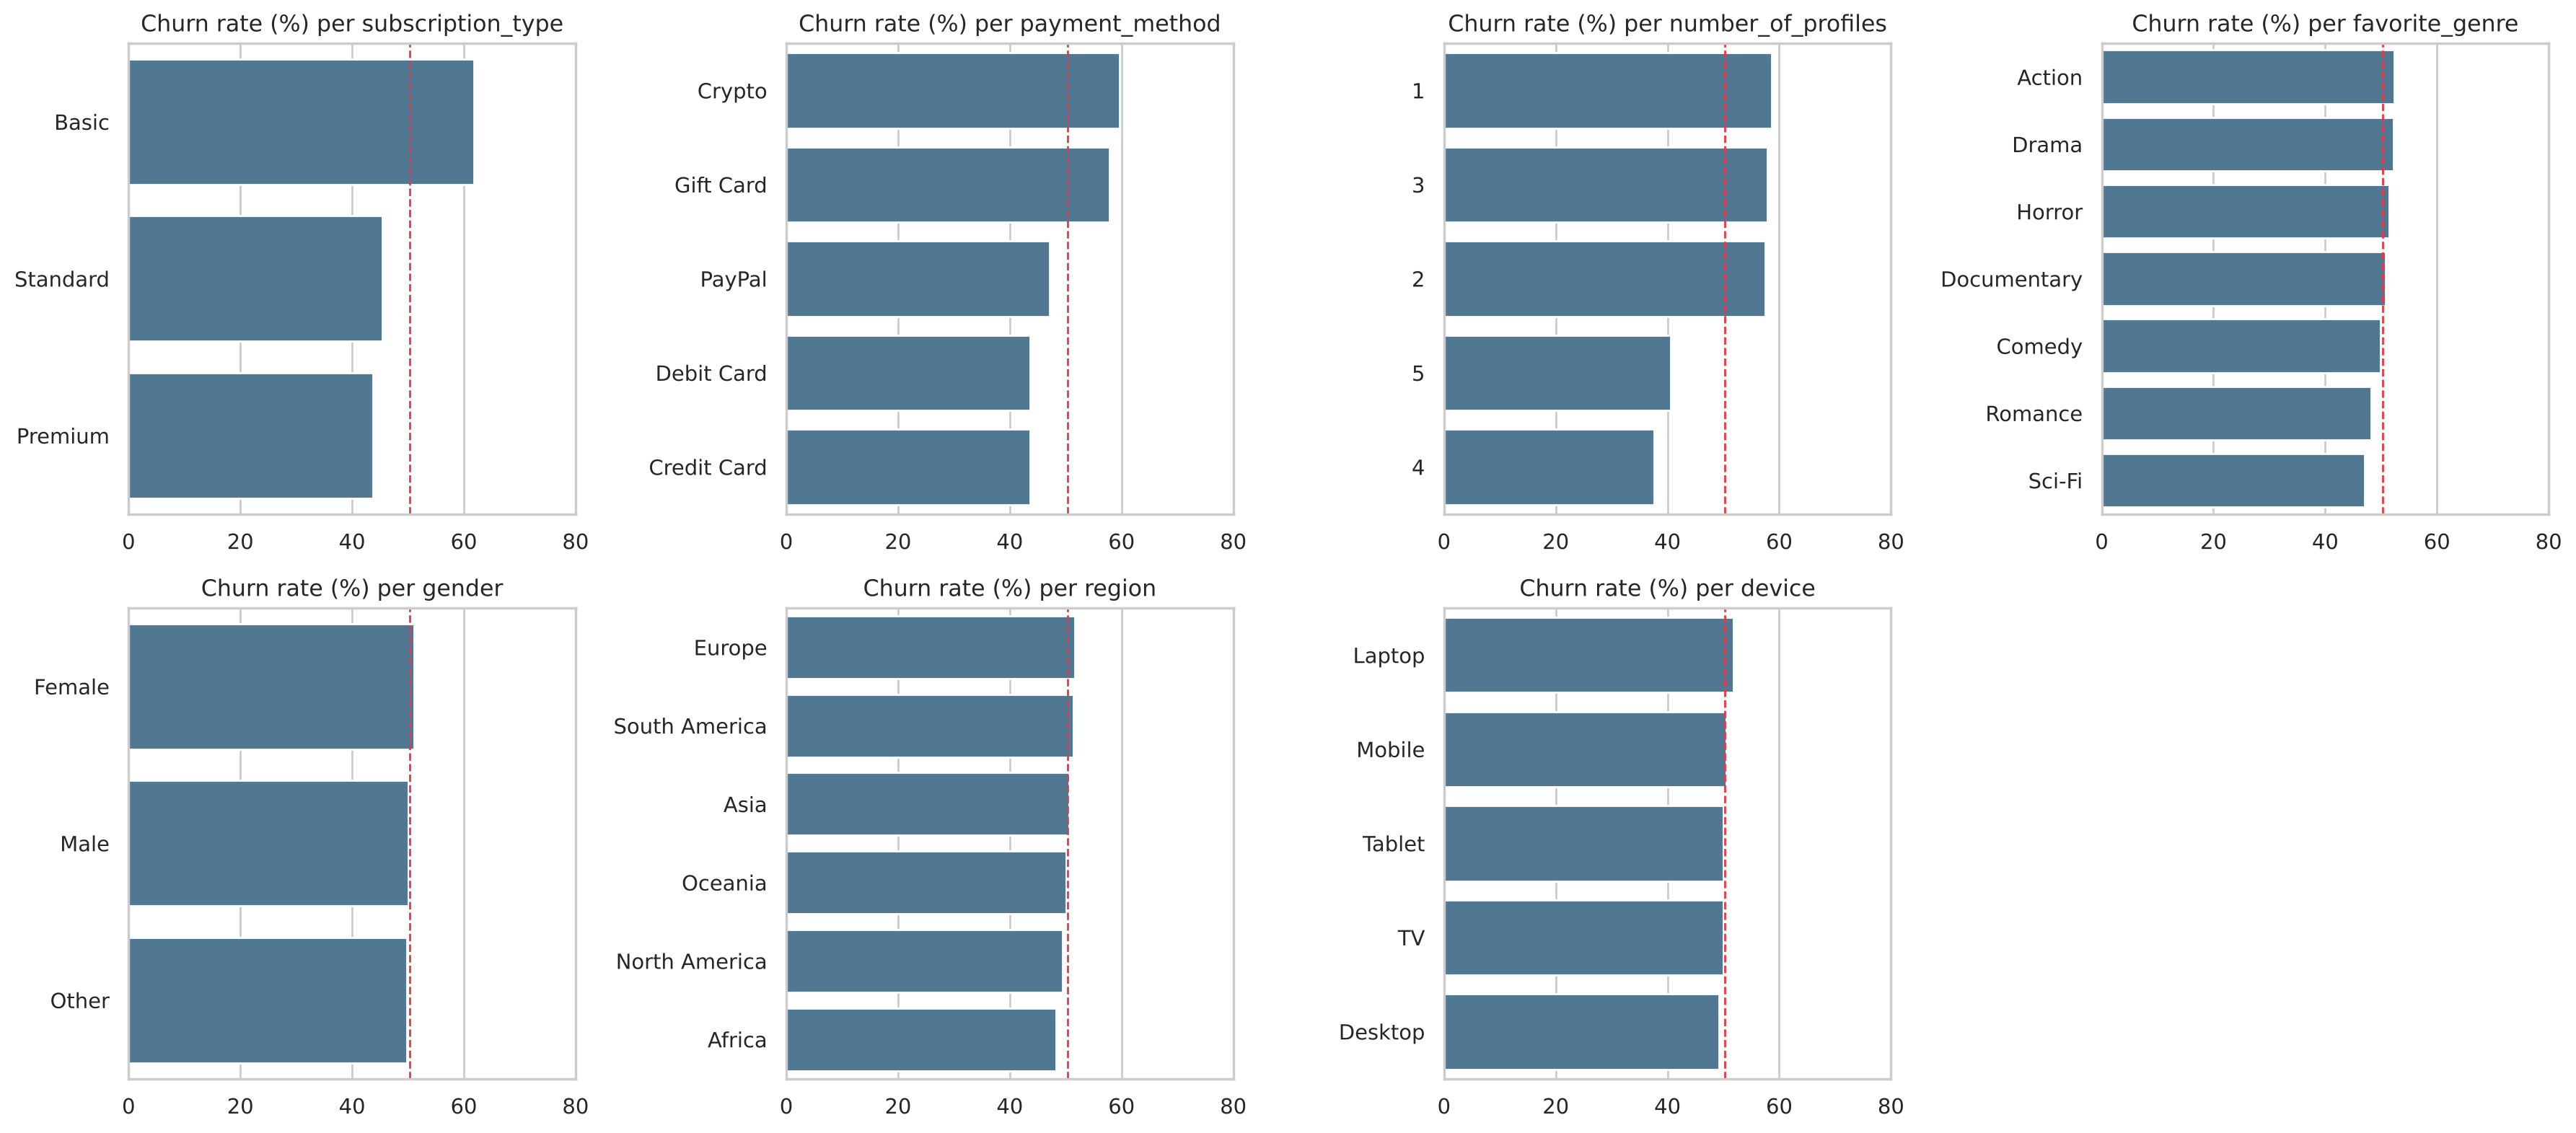

In [6]:
def cramers_v(x, y):
    t = pd.crosstab(x, y); chi2 = stats.chi2_contingency(t, correction=False)[0]
    return np.sqrt(chi2 / (t.values.sum() * (min(t.shape) - 1)))
rows = []
for c in ["subscription_type", "payment_method", "number_of_profiles", "favorite_genre", "gender", "region", "device"]:
    t = pd.crosstab(raw[c], raw.churned); chi2, p, dof, _ = stats.chi2_contingency(t)
    r = raw.groupby(c).churned.mean() * 100
    rows.append({"variabel": c, "churn_min_%": round(r.min(), 1), "churn_maks_%": round(r.max(), 1), "chi2": round(chi2, 1), "p_value": p,
                 "Cramers_V": round(cramers_v(raw[c], raw.churned), 3), "signifikan_5%": p < 0.05})
chi_df = pd.DataFrame(rows).sort_values("Cramers_V", ascending=False); chi_df.to_csv("outputs/chi_square.csv", index=False)
display(chi_df.style.format({"p_value": "{:.2g}"}))

plot_cols = ["subscription_type", "payment_method", "number_of_profiles", "favorite_genre", "gender", "region", "device"]
overall = raw.churned.mean() * 100
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, c in zip(axes.flat, plot_cols):
    r = (raw.groupby(c).churned.mean() * 100).sort_values(ascending=False)
    sns.barplot(x=r.values, y=r.index.astype(str), color=BLUE, ax=ax, orient="h")
    ax.axvline(overall, color=RED, ls="--", lw=1); ax.set_xlim(0, 80); ax.set_title(f"Churn rate (%) per {c}"); ax.set_ylabel("")
axes.flat[-1].axis("off")
savefig("fig03_churn_per_kategori.png")

**Temuan.** Hanya tiga variabel yang signifikan: `number_of_profiles` (Cramér's V 0,187), `subscription_type` (0,163), dan `payment_method` (0,139), semuanya berasosiasi **lemah sampai sedang**. Pembayaran **Crypto (59,7 %)** dan **Gift Card (57,8 %)** churn lebih tinggi daripada Credit Card (43,6 %) dan Debit Card (43,7 %); PayPal di tengah (47,1 %). Akun dengan **4–5 profil** churn lebih rendah (37,5 % dan 40,6 %) dibanding 1–3 profil (57–59 %). Sebaliknya `gender`, `region`, `device`, dan `favorite_genre` berada di sekitar rata-rata (p antara 0,32 dan 0,84), sehingga **tidak layak dijadikan dasar segmentasi atau perlakuan berbeda**.

## 3.5 Distribusi variabel numerik dan perbedaannya menurut churn

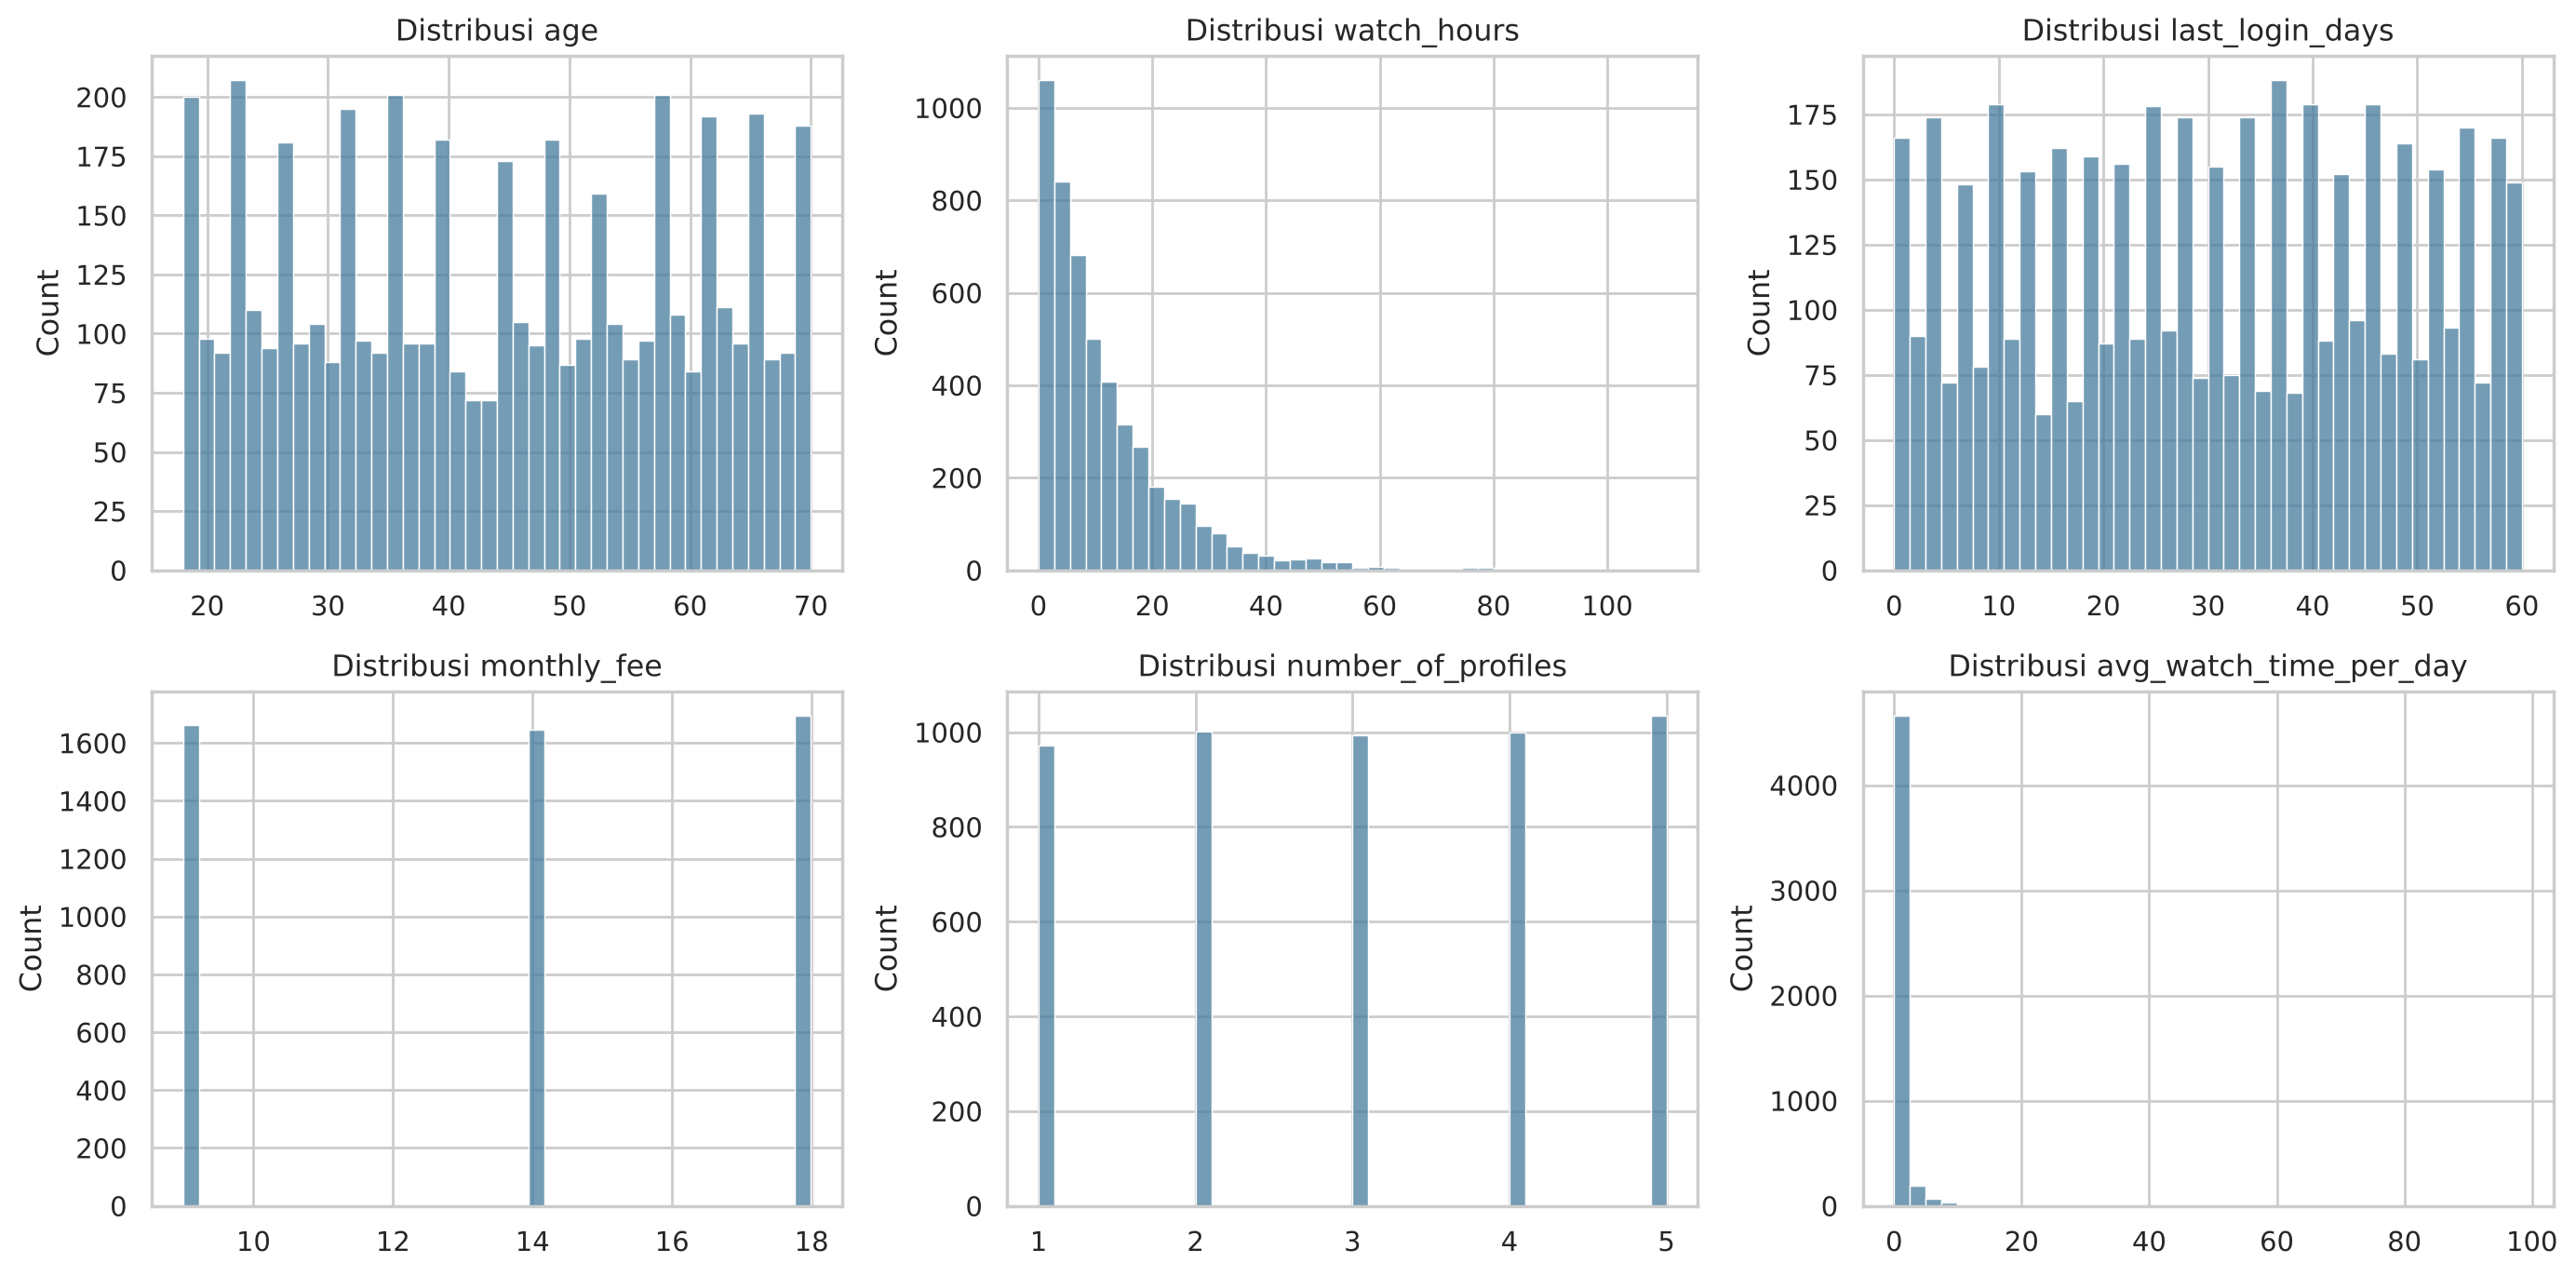

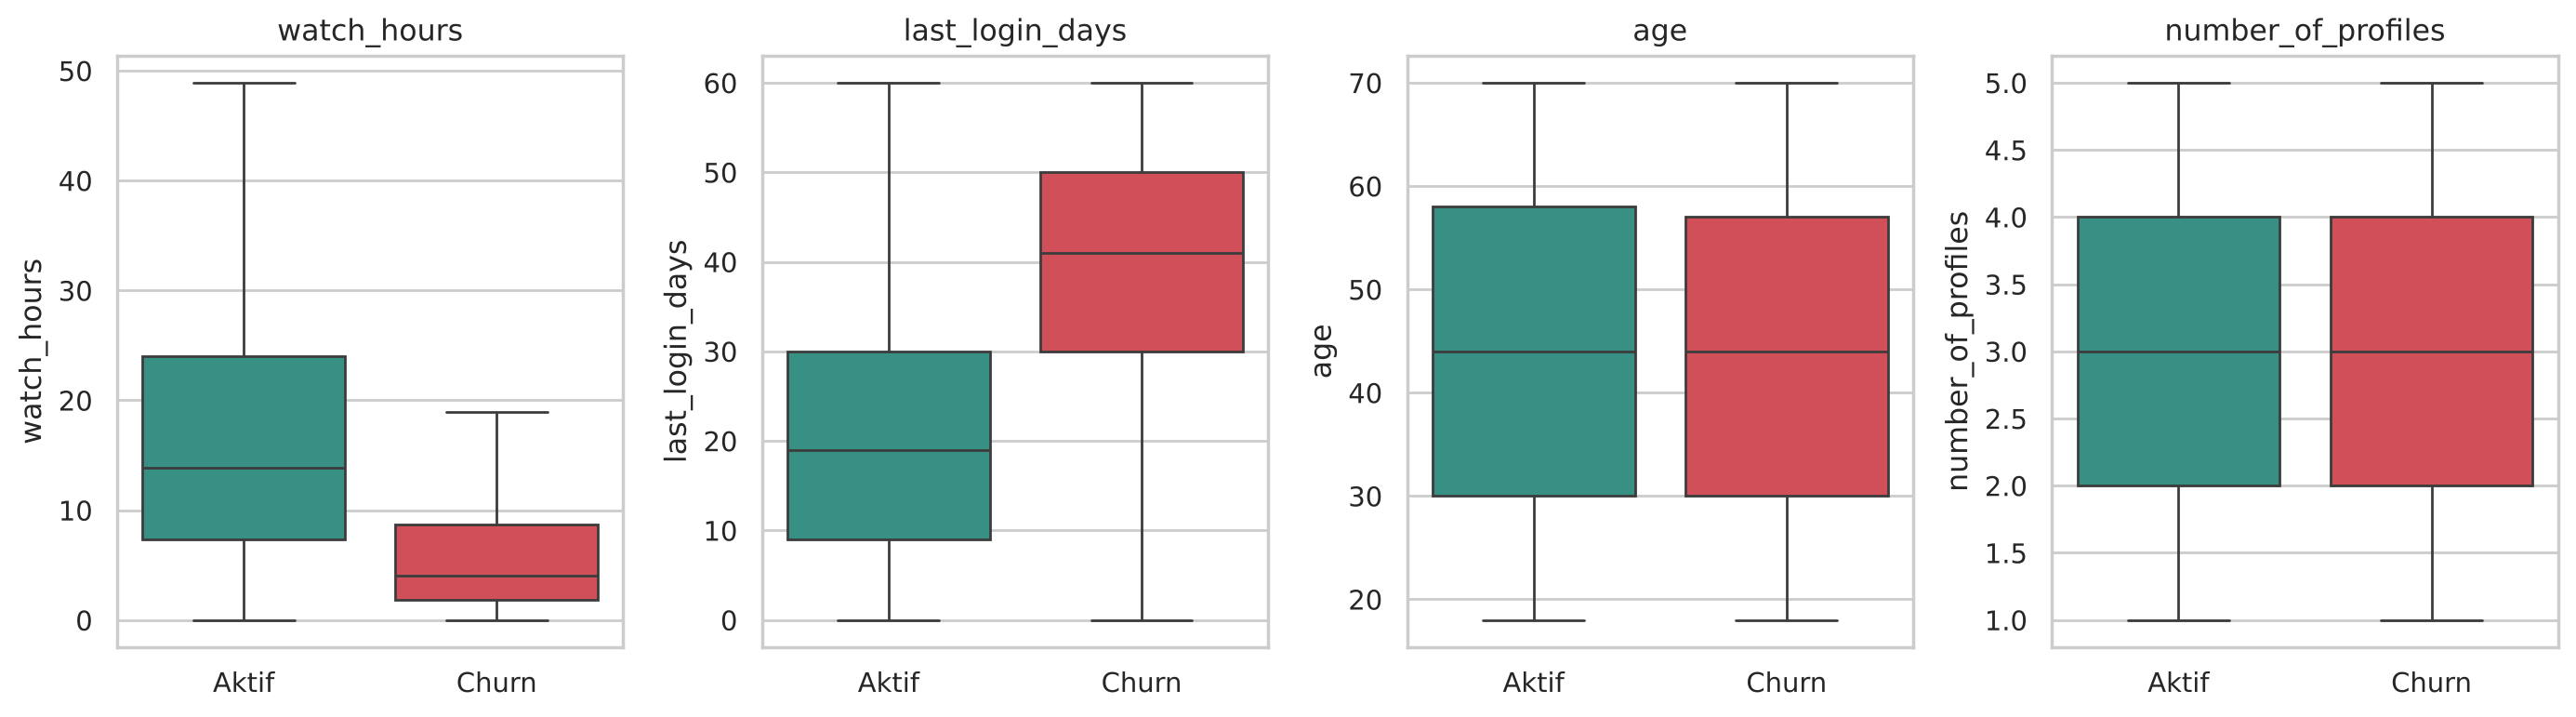

In [7]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, c in zip(axes.flat, NUM):
    sns.histplot(raw[c], bins=40, color=BLUE, ax=ax); ax.set_title(f"Distribusi {c}"); ax.set_xlabel("")
savefig("fig04_distribusi_numerik.png")
fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, c in zip(axes, ["watch_hours", "last_login_days", "age", "number_of_profiles"]):
    sns.boxplot(data=raw, x="churned", y=c, showfliers=False, palette=[TEAL, RED], ax=ax); ax.set_xticklabels(["Aktif", "Churn"]); ax.set_xlabel(""); ax.set_title(c)
savefig("fig05_boxplot_menurut_churn.png")

**Temuan.** Histogram menunjukkan `watch_hours` dan `avg_watch_time_per_day` condong tajam ke kanan dengan ekor panjang (butuh transformasi, lihat bagian 4.2), sedangkan `age`, `last_login_days`, dan `number_of_profiles` mendekati seragam. Pada boxplot (nilai ekstrem disembunyikan), `watch_hours` dan `last_login_days` memisahkan churn dari aktif dengan sangat jelas, sementara `age` dan `number_of_profiles` hampir tumpang tindih sepenuhnya. Jadi sinyal terkuat ada pada dua variabel perilaku, bukan pada atribut pelanggan.

## 3.6 Paket × metode pembayaran

payment_method,Credit Card,Crypto,Debit Card,Gift Card,PayPal
subscription_type,,,,,
Basic,59.4,62.7,60.1,64.7,62.6
Standard,36.2,59.2,36.5,56.7,38.5
Premium,33.6,57.7,34.9,52.4,38.8


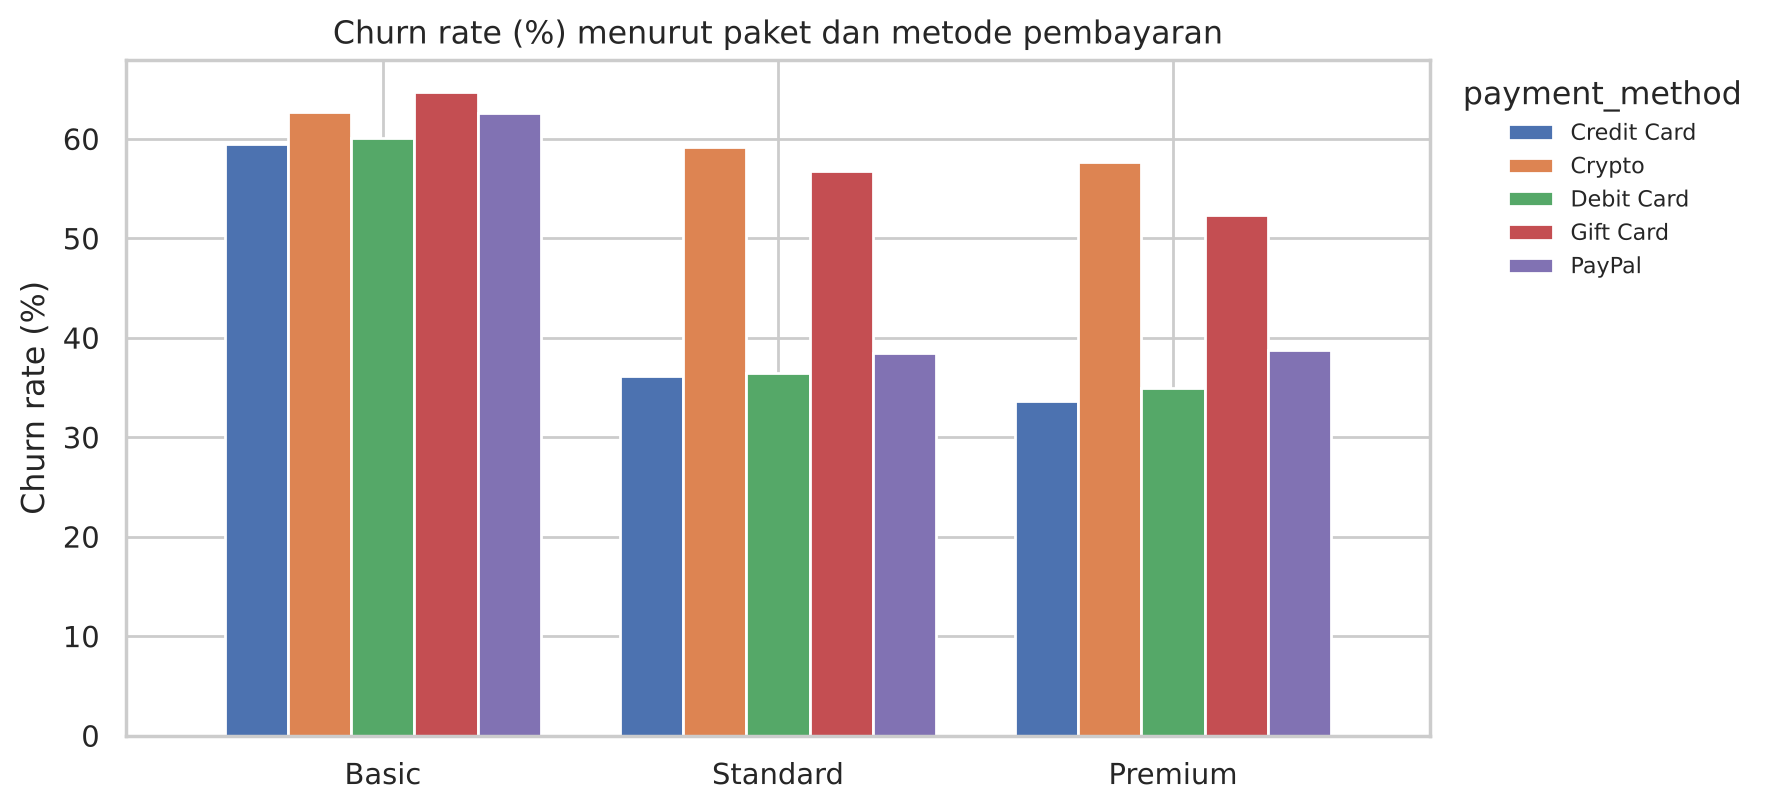

In [8]:
piv = (raw.pivot_table(index="subscription_type", columns="payment_method", values="churned", aggfunc="mean") * 100).reindex(ORDER_SUB)
display(piv.round(1))
ax = piv.plot(kind="bar", figsize=(9, 4.2), width=0.8, rot=0)
ax.set_ylabel("Churn rate (%)"); ax.set_xlabel(""); ax.set_title("Churn rate (%) menurut paket dan metode pembayaran")
ax.legend(title="payment_method", fontsize=8, loc="upper left", bbox_to_anchor=(1.01, 1.0), frameon=False)
savefig("fig06_paket_x_pembayaran.png")

**Temuan.** Pola metode pembayaran terlihat di ketiga paket: kolom Crypto dan Gift Card cenderung paling tinggi pada paket Standard dan Premium, sedangkan pada Basic seluruh metode memang sudah tinggi. Artinya efek pembayaran tidak sekadar efek paket. Karena jumlah akun per sel kecil (sekitar 300–360), perbedaan antar sel individual tidak boleh ditafsirkan berlebihan.

## 3.7 Korelasi dan interaksi

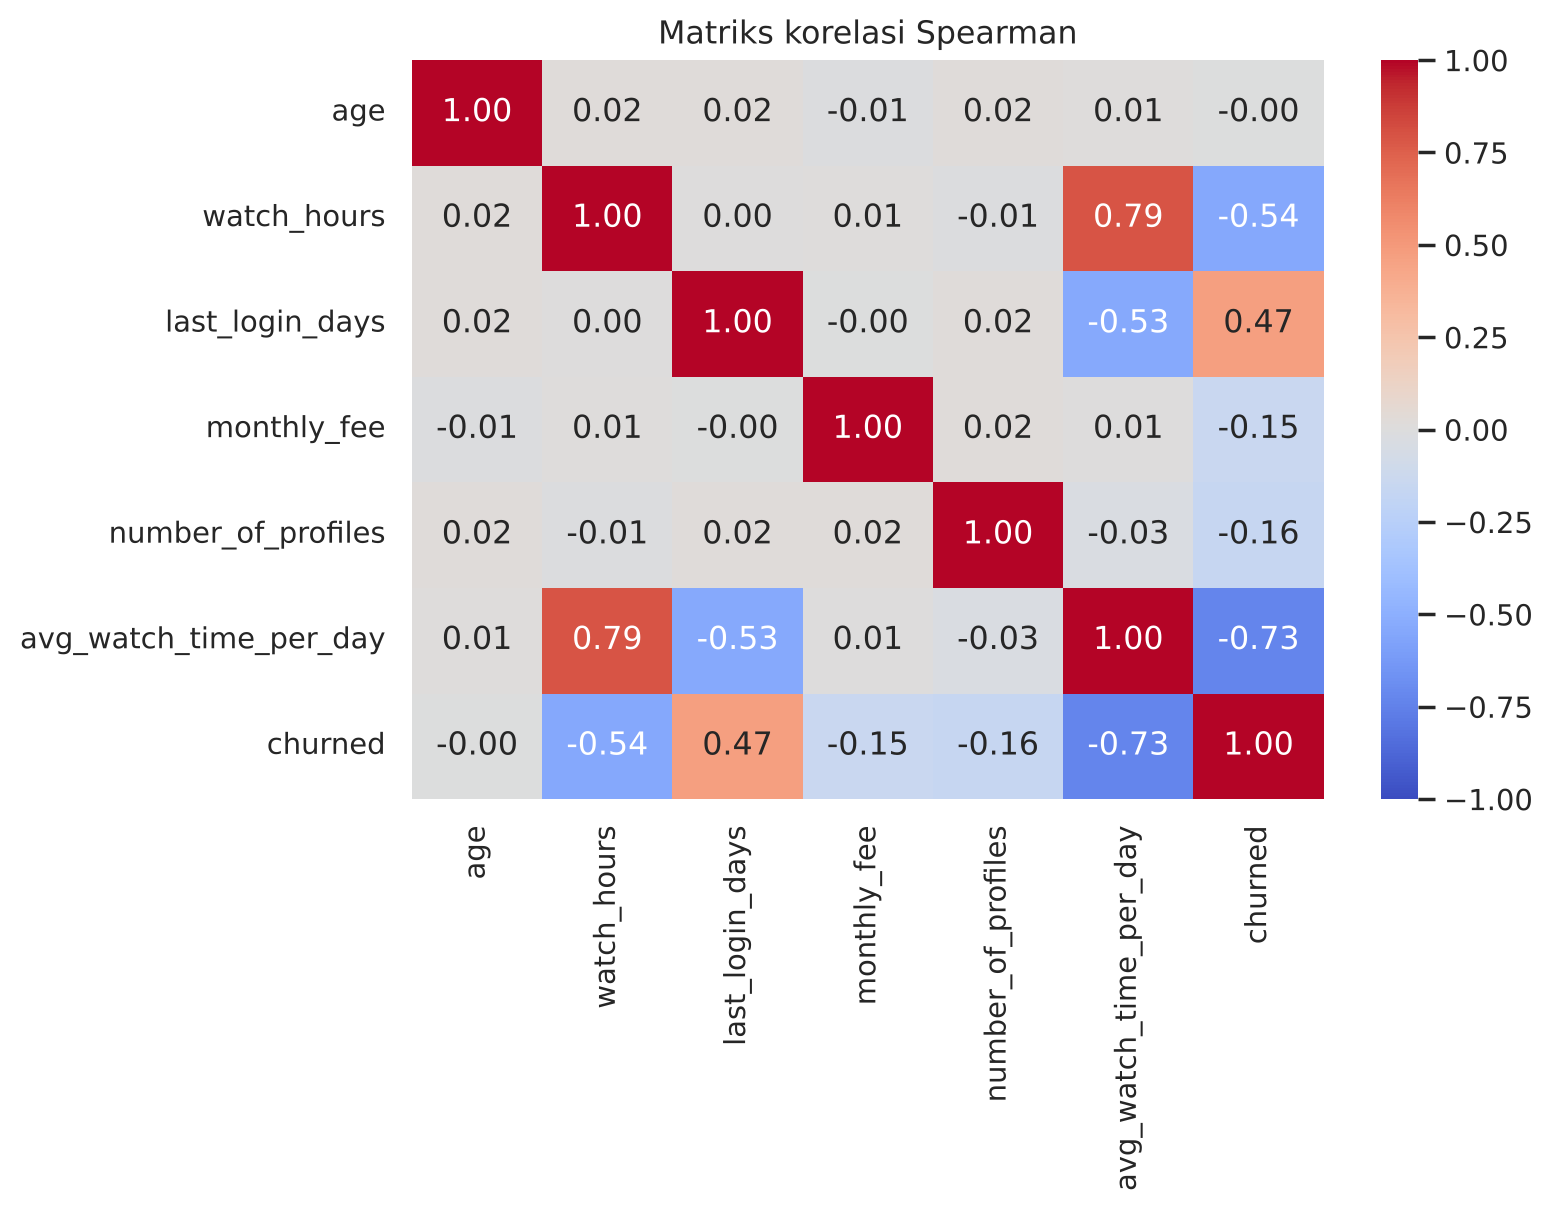

Korelasi dengan churned: {'age': -0.0, 'watch_hours': -0.54, 'last_login_days': 0.47, 'monthly_fee': -0.15, 'number_of_profiles': -0.16, 'avg_watch_time_per_day': -0.73}


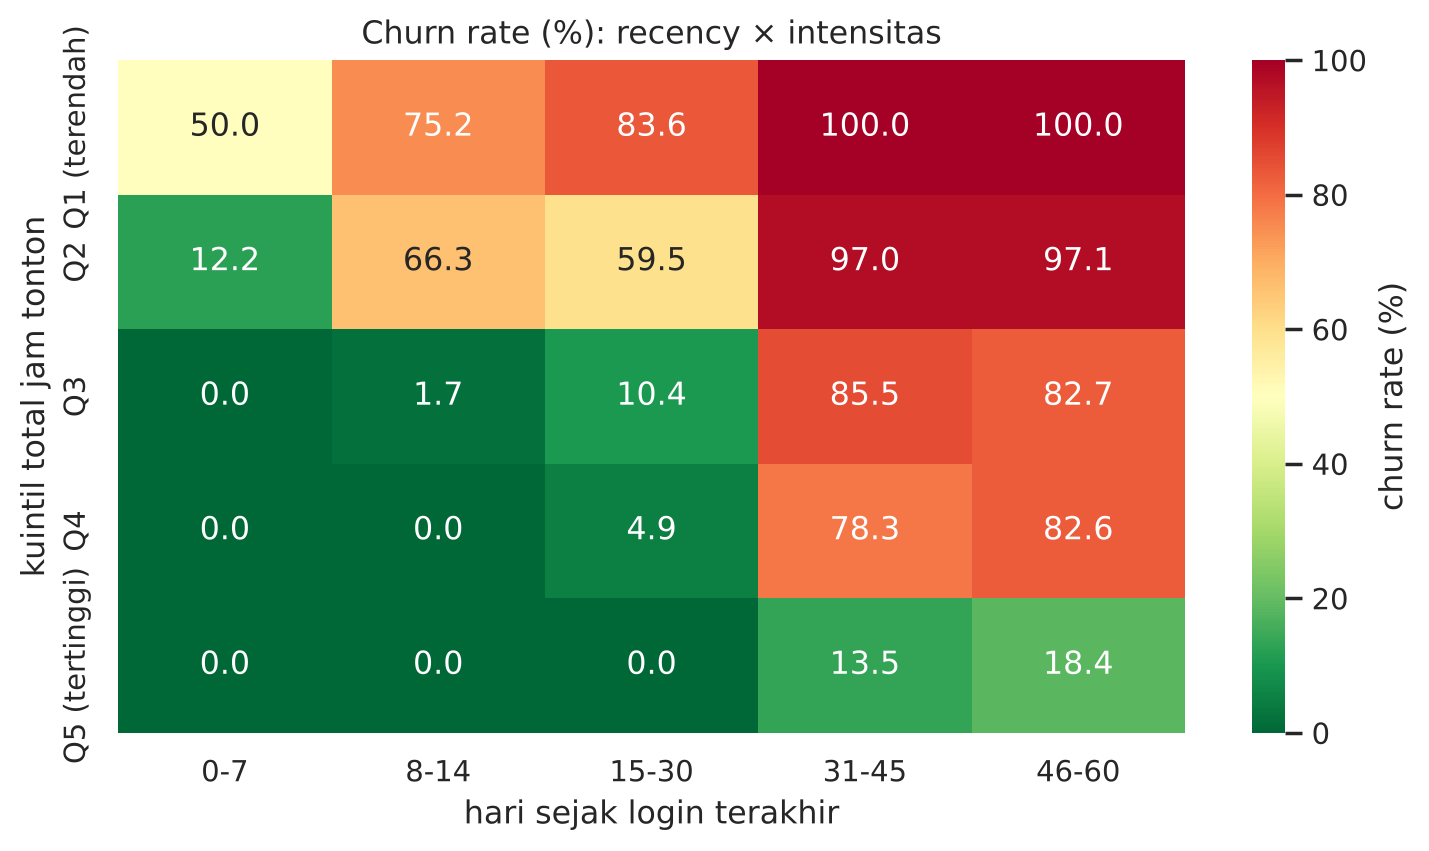

Jumlah pelanggan minimal per sel heatmap: **101** (maksimum 274).

In [9]:
corr = raw[NUM + ["churned"]].corr(method="spearman")
plt.figure(figsize=(8, 6.2)); sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1)
plt.title("Matriks korelasi Spearman"); savefig("fig07_korelasi_spearman.png")
print("Korelasi dengan churned:", corr["churned"].drop("churned").round(2).to_dict())

q = raw.assign(jam=pd.qcut(raw.watch_hours, 5, labels=["Q1 (terendah)", "Q2", "Q3", "Q4", "Q5 (tertinggi)"]),
               login=pd.cut(raw.last_login_days, bins, labels=labels))
hm = q.pivot_table(index="jam", columns="login", values="churned", aggfunc="mean", observed=True) * 100
cnt = q.pivot_table(index="jam", columns="login", values="churned", aggfunc="size", observed=True)
plt.figure(figsize=(7.5, 4.4)); sns.heatmap(hm, annot=True, fmt=".1f", cmap="RdYlGn_r", vmin=0, vmax=100, cbar_kws={"label": "churn rate (%)"})
plt.xlabel("hari sejak login terakhir"); plt.ylabel("kuintil total jam tonton"); plt.title("Churn rate (%): recency × intensitas")
savefig("fig08_interaksi_login_jam.png")
tampil(f"Jumlah pelanggan minimal per sel heatmap: **{int(cnt.min().min())}** (maksimum {int(cnt.max().max())}).")

**Temuan korelasi.** Korelasi Spearman dengan churn: `avg_watch_time_per_day` −0,73, `watch_hours` −0,54, `last_login_days` +0,47, `number_of_profiles` −0,16, `monthly_fee` −0,15, `age` 0,00. Kolom `avg_watch_time_per_day` paling kuat **karena ia turunan** dari `watch_hours` dan `last_login_days`, bukan karena informasi baru, sehingga kuat korelasinya menyesatkan dan kolom ini akan dibuang (bagian 4.5). Di antara fitur prediktor asli (di luar kolom turunan), korelasi Spearman terbesar hanya 0,02, jadi multikolinearitas rendah dan tidak ada fitur yang perlu dibuang karena kolinearitas, selain `monthly_fee` yang redundan terhadap paket.

**Temuan interaksi.** Dua variabel perilaku saling memodifikasi pengaruhnya. Pada kuintil jam tonton terendah (Q1) dengan jeda login > 30 hari, churn mencapai **100 %**, sedangkan pada kuintil menengah (Q3–Q4) lompatan akibat jeda login sangat besar (dari 0–10 % pada login ≤ 30 hari menjadi 78–86 % setelah 30 hari). Pada kuintil tertinggi (Q5) lompatan itu jauh lebih kecil (0 % menjadi 13–18 %), dan pada Q1 churn sudah tinggi (50–84 %) bahkan ketika baru login. Artinya efek jeda login **bergantung pada seberapa banyak pelanggan menonton**, suatu interaksi yang tidak bisa ditangkap model linear sederhana. Ini alasan membandingkan model non-linear (Random Forest, Gradient Boosting) pada bagian 5.

## 3.8 Insight yang dipakai untuk keputusan berikutnya

| # | Insight dari EDA | Dipakai untuk |
|---|---|---|
| 1 | `watch_hours` sangat miring, outlier-nya pelanggan sangat aktif yang sah (churn hanya 0,8 %) | outlier dipertahankan (winsorizing) + transformasi log, bukan dihapus |
| 2 | `avg_watch_time_per_day` adalah turunan dengan nilai mustahil (> 24 jam/hari) dan kuat karena rumus | dibuang dari fitur (kebocoran) |
| 3 | Churn melonjak setelah 30 hari tanpa login | fitur biner `inactive_30d` |
| 4 | `subscription_type` identik dengan `monthly_fee` | pakai satu saja (`subscription_type`, ordinal) |
| 5 | Churn turun tajam pada ≥ 4 profil (terutama Standard/Premium) | fitur `multi_profile` |
| 6 | Crypto dan Gift Card churn lebih tinggi | fitur `risky_payment` |
| 7 | `gender`, `region`, `device`, `favorite_genre`, `age` tidak berasosiasi | dibuang dari model; tidak dipakai segmentasi |
| 8 | Interaksi recency × intensitas kuat | uji model non-linear |
| 9 | Kelas seimbang (50,3 : 49,7) | uji apakah penyeimbangan perlu |

## 3.9 Representativitas dan indikasi data sintetis

In [10]:
for c in ["gender", "region", "device", "payment_method"]:
    print(c, (raw[c].value_counts(normalize=True) * 100).round(1).to_dict())
print("age: skewness", round(raw.age.skew(), 3), "| rentang", raw.age.min(), "-", raw.age.max())

gender {'Female': 34.2, 'Male': 33.1, 'Other': 32.7}
region {'South America': 17.5, 'Europe': 17.3, 'North America': 17.0, 'Asia': 16.8, 'Africa': 16.1, 'Oceania': 15.3}
device {'Tablet': 21.0, 'Laptop': 20.1, 'Mobile': 20.1, 'TV': 19.9, 'Desktop': 19.0}
payment_method {'Debit Card': 20.6, 'PayPal': 20.5, 'Crypto': 19.9, 'Gift Card': 19.5, 'Credit Card': 19.5}
age: skewness 0.006 | rentang 18 - 70


**Temuan.** Tiap kategori hampir sama besar (gender 32,7–34,2 %, wilayah 15,3–17,5 %, perangkat 19–21 %), usia dan jumlah profil mendekati seragam, dan churn rate 50,3 % jauh di atas layanan streaming nyata. Kombinasi ini mengindikasikan data **sintetis atau sengaja diseimbangkan**. Indikasi lain: churn melonjak tajam tepat di batas 30 hari sejak login terakhir (sekitar 17–35 % pada ≤ 30 hari, sekitar 72–78 % di atas 30 hari), pola yang lazim pada label yang dibangkitkan dengan aturan. Ini indikasi dari data, bukan bukti: halaman dataset tidak menyatakan data sintetis, tetapi juga tidak menyebut asal data primer. Konsekuensinya: temuan boleh dipakai untuk latihan metodologi dan menggambarkan pola dalam dataset ini, tetapi **tidak boleh diklaim sebagai estimasi churn Netflix yang sebenarnya**. Sampai batas tertentu, performa model nanti juga mencerminkan cara data dibangkitkan.

---
# 4. Cleaning dan Preprocessing
Urutan kerja: audit kualitas data (4.1), cleaning (4.2), kondisi sebelum vs sesudah (4.3), pembagian data dan preprocessing (4.4), lalu feature selection dengan alasan buang, buat, dan pakai (4.5). Aturan anti-*leakage*: **setelah split, semua parameter transformasi (encoder, scaler) dan semua uji seleksi fitur hanya dihitung dari data latih.**

## 4.1 Audit kualitas data per kolom

,kolom,tipe,missing,nilai_unik,outlier_IQR,outlier_%,abs_z>3
0,customer_id,str,0,5000,NaN,NaN,NaN
1,age,int64,0,53,0.0,0.0,0.0
2,gender,str,0,3,NaN,NaN,NaN
3,subscription_type,str,0,3,NaN,NaN,NaN
4,watch_hours,float64,0,2343,238.0,4.8,102.0
5,last_login_days,int64,0,61,0.0,0.0,0.0
6,region,str,0,6,NaN,NaN,NaN
7,device,str,0,5,NaN,NaN,NaN
8,monthly_fee,float64,0,3,0.0,0.0,0.0
9,churned,int64,0,2,NaN,NaN,NaN


Total sel hilang: 0 | duplikat penuh: 0 | duplikat selain customer_id: 0
Rentang: age 18 - 70 | login 0 - 60 | profil 1 - 5 | watch_hours min 0.01
Label kategori berspasi/tidak konsisten: 0
Selisih maksimum rumus avg_watch_time_per_day: 0.01
avg_watch_time_per_day > 24 jam/hari: 10 baris, last_login_days mereka: [0, 1]
Churn rate pada outlier watch_hours (> 35.07): 0.8 %


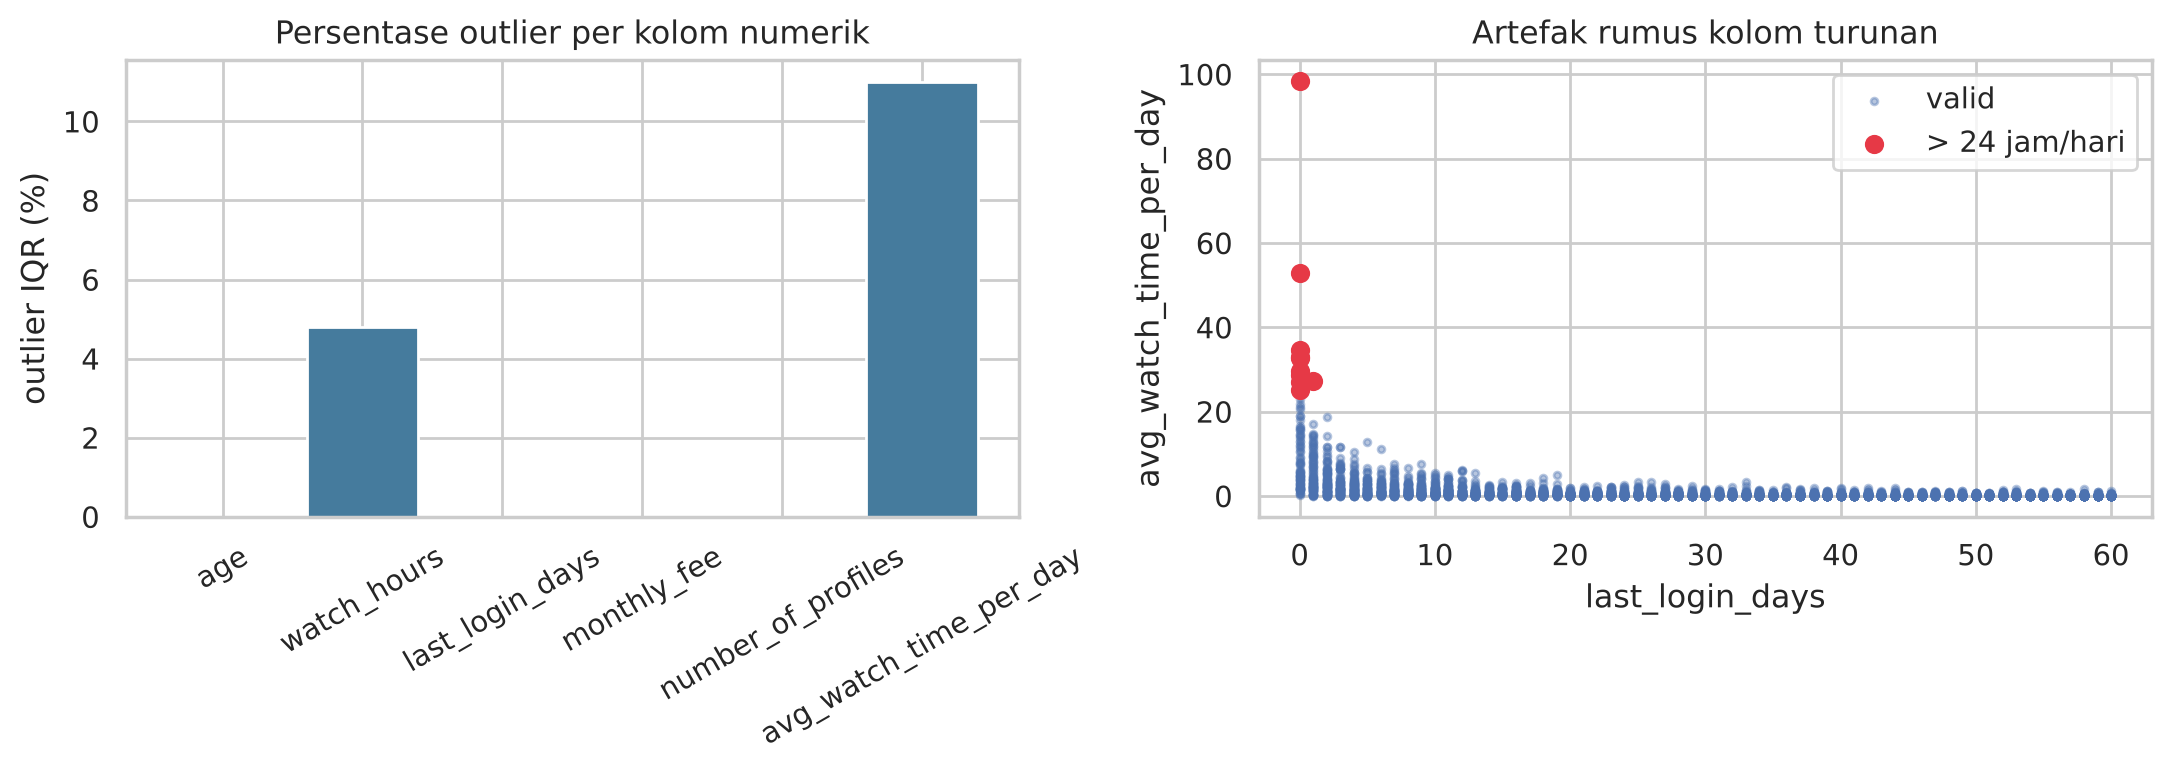

In [11]:
rows = []
for c in raw.columns:
    r = {"kolom": c, "tipe": str(raw[c].dtype), "missing": int(raw[c].isna().sum()), "nilai_unik": int(raw[c].nunique())}
    if c in NUM:
        q1, q3 = raw[c].quantile([.25, .75]); i = q3 - q1
        r["outlier_IQR"] = int(((raw[c] < q1 - 1.5*i) | (raw[c] > q3 + 1.5*i)).sum()); r["outlier_%"] = round(100 * r["outlier_IQR"] / len(raw), 1)
        r["abs_z>3"] = int((np.abs(stats.zscore(raw[c])) > 3).sum())
    rows.append(r)
audit = pd.DataFrame(rows); audit.to_csv("outputs/audit_kualitas_kolom.csv", index=False); display(audit)

print("Total sel hilang:", int(raw.isna().sum().sum()), "| duplikat penuh:", int(raw.duplicated().sum()),
      "| duplikat selain customer_id:", int(raw.drop(columns="customer_id").duplicated().sum()))
print("Rentang: age", raw.age.min(), "-", raw.age.max(), "| login", raw.last_login_days.min(), "-", raw.last_login_days.max(),
      "| profil", raw.number_of_profiles.min(), "-", raw.number_of_profiles.max(), "| watch_hours min", raw.watch_hours.min())
print("Label kategori berspasi/tidak konsisten:", sum(int(raw[c].str.strip().ne(raw[c]).sum()) for c in CAT))
formula = (raw.watch_hours / (raw.last_login_days + 1)).round(2)
imp = raw[raw.avg_watch_time_per_day > 24]
print("Selisih maksimum rumus avg_watch_time_per_day:", round(float((raw.avg_watch_time_per_day - formula).abs().max()), 3))
print("avg_watch_time_per_day > 24 jam/hari:", len(imp), "baris, last_login_days mereka:", sorted(imp.last_login_days.unique().tolist()))
for c, lim in [("watch_hours", 35.07)]:
    print(f"Churn rate pada outlier {c} (> {lim}):", round(100 * raw[raw[c] > lim].churned.mean(), 1), "%")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
a = audit[audit["outlier_IQR"].notna()]
ax[0].bar(a.kolom, a["outlier_%"], color=BLUE); ax[0].set_ylabel("outlier IQR (%)"); ax[0].tick_params(axis="x", rotation=30); ax[0].set_title("Persentase outlier per kolom numerik")
ok = raw.avg_watch_time_per_day <= 24
ax[1].scatter(raw.last_login_days[ok], raw.avg_watch_time_per_day[ok], s=6, alpha=.4, label="valid")
ax[1].scatter(raw.last_login_days[~ok], raw.avg_watch_time_per_day[~ok], s=35, color=RED, label="> 24 jam/hari")
ax[1].set_xlabel("last_login_days"); ax[1].set_ylabel("avg_watch_time_per_day"); ax[1].legend(); ax[1].set_title("Artefak rumus kolom turunan")
savefig("fig09_audit_outlier_dan_artefak.png")

**Temuan audit.** (1) **Missing value 0** dan **duplikat 0** pada seluruh 14 kolom, tidak ada label kategori yang tidak konsisten, dan semua nilai berada dalam rentang yang masuk akal. Karena itu tidak ada imputasi atau penghapusan baris duplikat. (2) Outlier hanya muncul pada dua kolom: `watch_hours` (238 baris, 4,8 %) dan `avg_watch_time_per_day` (549 baris, 11 %). Outlier `watch_hours` adalah pelanggan yang benar-benar menonton sangat banyak dan hampir semuanya bertahan (churn 0,8 %), jadi **sah dan informatif**, bukan kesalahan input. (3) `avg_watch_time_per_day` mengikuti rumus `round(watch_hours / (last_login_days + 1), 2)`; sebanyak 10 baris bernilai > 24 jam per hari (hingga 98 jam), mustahil secara fisik, dan seluruhnya muncul ketika `last_login_days` 0 atau 1 yang membuat pembagi sangat kecil. Itu artefak rumus, bukan perilaku nyata.

## 4.2 Cleaning: strategi dan alasan

| Masalah | Jumlah | Strategi | Alasan |
|---|---|---|---|
| Missing value | 0 | tidak ada tindakan | tidak ada yang perlu diisi |
| Duplikat | 0 | tidak ada tindakan | tidak ada yang perlu dihapus |
| Outlier `watch_hours` | 238 baris | **winsorizing** ke batas atas IQR (Q3 + 1,5·IQR = 35,07), lalu transformasi `log1p` saat preprocessing | nilainya sah dan informatif, sehingga menghapus baris membuang informasi dan menurunkan ukuran data; winsorizing menahan pengaruh ekstrem pada model linear |
| Nilai mustahil `avg_watch_time_per_day` > 24 | 10 baris | dibatasi ke 24 jam/hari | artefak rumus; kolom ini nantinya dibuang dari fitur, pembatasan dilakukan agar data bersih |
| Tipe data kategorikal | 6 kolom | diubah ke `category`; `subscription_type` dibuat ordinal Basic < Standard < Premium | memberi urutan yang benar |
| Kolom `customer_id` | 5.000 unik | tidak dipakai sebagai fitur (dipertahankan hanya sebagai kunci) | identifier tidak punya makna prediktif |

Strategi outlier diuji empiris pada data latih (tabel di bawah) sebelum dipilih.

In [12]:
q1, q3 = raw.watch_hours.quantile([.25, .75]); WH_CAP = q3 + 1.5 * (q3 - q1)
clean = raw.copy()
clean["watch_hours"] = clean.watch_hours.clip(upper=WH_CAP)
clean["avg_watch_time_per_day"] = clean.avg_watch_time_per_day.clip(upper=24)
for c in CAT: clean[c] = clean[c].astype("category")
clean["subscription_type"] = pd.Categorical(clean.subscription_type.astype(str), ORDER_SUB, ordered=True)
print("Tipe kolom kategorikal setelah cleaning:", {c: str(clean[c].dtype) for c in CAT})
print("Batas winsorizing watch_hours (Q3 + 1,5 IQR):", round(WH_CAP, 2))

# Pembagian data: stratified 80:20, dilakukan SEBELUM membandingkan strategi supaya perbandingan memakai data latih saja
y_all = raw.churned
idx_tr, idx_te = train_test_split(raw.index, test_size=.2, stratify=y_all, random_state=SEED)
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)

def make_X(df_, strat):
    X = df_[["watch_hours", "last_login_days", "number_of_profiles", "payment_method"]].copy()
    X["sub_ord"] = df_.subscription_type.astype(str).map({"Basic": 0, "Standard": 1, "Premium": 2})
    w = df_.watch_hours
    if strat in ("winsor", "winsor+log"): w = w.clip(upper=WH_CAP)
    if strat in ("log", "winsor+log"): w = np.log1p(w)
    X["watch_hours"] = w; return X
def pipe_small(model):
    ct = ColumnTransformer([("n", StandardScaler(), ["watch_hours", "last_login_days", "number_of_profiles", "sub_ord"]),
                            ("c", OneHotEncoder(handle_unknown="ignore"), ["payment_method"])])
    return Pipeline([("c", ct), ("m", model)])

raw_tr = raw.loc[idx_tr]; res = []
for nama, strat in [("Asli (dibiarkan)", "asli"), ("Transformasi log1p", "log"), ("Winsorizing (batas IQR)", "winsor"),
                    ("Winsorizing + log1p", "winsor+log"), ("Hapus baris outlier", "hapus")]:
    row = {"Strategi": nama}
    for mn, mk in [("LR", lambda: LogisticRegression(max_iter=1000)),
                   ("RF", lambda: RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=SEED, n_jobs=-1))]:
        a_, r_ = [], []
        for a, b in cv.split(raw_tr, raw_tr.churned):
            tr_, te_ = raw_tr.iloc[a], raw_tr.iloc[b]
            if strat == "hapus": tr_ = tr_[tr_.watch_hours <= WH_CAP]
            s_ = "asli" if strat == "hapus" else strat
            p = pipe_small(mk()).fit(make_X(tr_, s_), tr_.churned); Xb = make_X(te_, s_)
            a_.append(roc_auc_score(te_.churned, p.predict_proba(Xb)[:, 1])); r_.append(recall_score(te_.churned, p.predict(Xb)))
        row[f"{mn} ROC-AUC"] = round(np.mean(a_), 4); row[f"{mn} recall"] = round(np.mean(r_), 3)
    res.append(row)
t_strat = pd.DataFrame(res); t_strat.to_csv("outputs/perbandingan_strategi_outlier.csv", index=False); display(t_strat)

Tipe kolom kategorikal setelah cleaning: {'gender': 'category', 'subscription_type': 'category', 'region': 'category', 'device': 'category', 'payment_method': 'category', 'favorite_genre': 'category'}
Batas winsorizing watch_hours (Q3 + 1,5 IQR): 35.07


,Strategi,LR ROC-AUC,LR recall,RF ROC-AUC,RF recall
0,Asli (dibiarkan),0.9612,0.887,0.9980,0.972
1,Transformasi log1p,0.9619,0.885,0.9980,0.972
2,Winsorizing (batas IQR),0.9613,0.886,0.9980,0.972
3,Winsorizing + log1p,0.9613,0.883,0.9980,0.972
4,Hapus baris outlier,0.9612,0.886,0.9982,0.970


**Temuan.** Kelima strategi menghasilkan ROC-AUC yang hampir identik (Logistic Regression 0,961–0,962; Random Forest 0,998), sehingga model tidak sensitif terhadap cara outlier ditangani. Bila hasilnya sama, dipilih strategi yang **tidak membuang data** dan paling aman bagi model linear: **winsorizing + `log1p`**. Menghapus baris tidak memberi keuntungan sama sekali dan mengurangi data latih.

## 4.3 Kondisi data sebelum vs sesudah cleaning

,Sebelum,Sesudah
baris,5000.000,5000.000
kolom,14.000,14.000
missing,0.000,0.000
duplikat,0.000,0.000
"watch_hours > 35,07",238.000,0.000
watch_hours maks,110.400,35.069
watch_hours rerata,11.649,10.976
watch_hours skewness,2.259,1.061
avg_watch > 24 jam,10.000,0.000
avg_watch maks,98.420,24.000


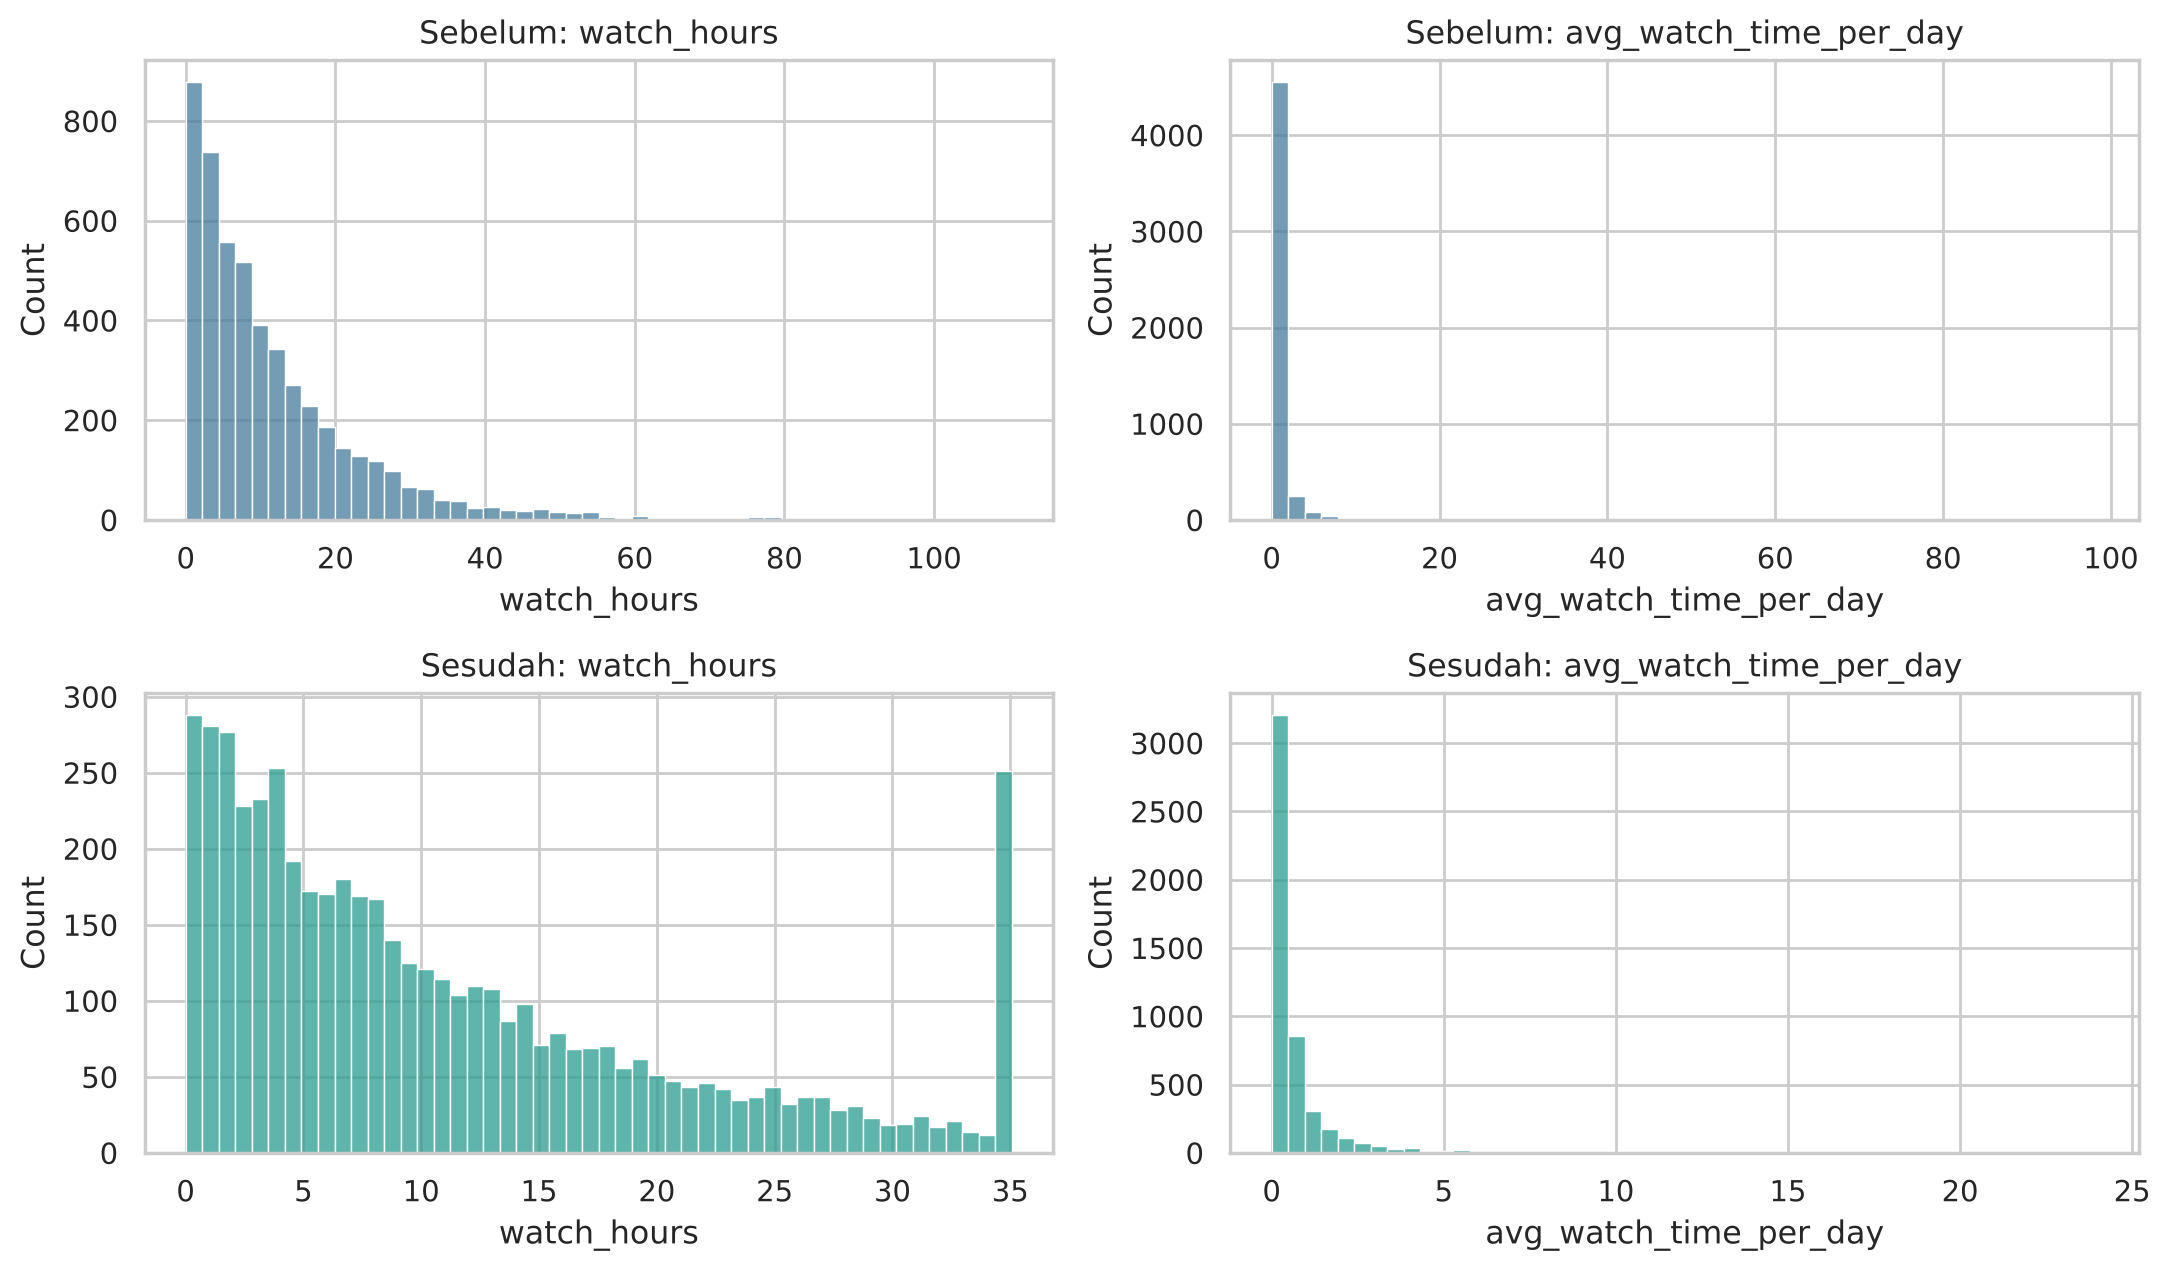

In [13]:
def profil(df_):
    return {"baris": len(df_), "kolom": df_.shape[1], "missing": int(df_.isna().sum().sum()), "duplikat": int(df_.duplicated().sum()),
            "watch_hours > 35,07": int((df_.watch_hours > WH_CAP + 1e-9).sum()), "watch_hours maks": df_.watch_hours.max(),
            "watch_hours rerata": df_.watch_hours.mean(), "watch_hours skewness": df_.watch_hours.skew(),
            "avg_watch > 24 jam": int((df_.avg_watch_time_per_day > 24).sum()), "avg_watch maks": df_.avg_watch_time_per_day.max(),
            "avg_watch skewness": df_.avg_watch_time_per_day.skew(), "churn rate (%)": df_.churned.mean() * 100,
            "Spearman watch_hours vs churn": stats.spearmanr(df_.watch_hours, df_.churned)[0]}
ba = pd.DataFrame({"Sebelum": profil(raw), "Sesudah": profil(clean)}).round(3); ba.to_csv("outputs/sebelum_sesudah_cleaning.csv"); display(ba)
fig, ax = plt.subplots(2, 2, figsize=(11, 6.5))
for j, c in enumerate(["watch_hours", "avg_watch_time_per_day"]):
    sns.histplot(raw[c], bins=50, ax=ax[0, j], color=BLUE); ax[0, j].set_title(f"Sebelum: {c}")
    sns.histplot(clean[c], bins=50, ax=ax[1, j], color=TEAL); ax[1, j].set_title(f"Sesudah: {c}")
savefig("fig10_sebelum_sesudah_cleaning.png")

**Temuan.** Jumlah baris dan kolom tidak berubah (5.000 × 14), missing dan duplikat tetap 0, dan churn rate tetap 50,3 %. Yang berubah hanya ekor distribusi: nilai maksimum `watch_hours` turun dari 110,4 menjadi 35,07, skewness turun dari 2,26 menjadi 1,06, dan 10 nilai mustahil pada `avg_watch_time_per_day` hilang (maksimum 98,4 → 24). Korelasi `watch_hours` dengan churn tidak berubah (−0,54) sehingga **informasi prediktifnya terjaga**. Skewness yang masih 1,06 ditangani lagi oleh `log1p` pada preprocessing berikut.

## 4.4 Pembagian data dan preprocessing

### Pembagian data latih dan uji

In [14]:
train, test = clean.loc[idx_tr].copy(), clean.loc[idx_te].copy()
ytr, yte = train.churned, test.churned
split = pd.DataFrame({"Baris": [len(clean), len(train), len(test)], "Churn (1)": [int(clean.churned.sum()), int(ytr.sum()), int(yte.sum())],
                      "Churn rate (%)": [round(clean.churned.mean()*100, 1), round(ytr.mean()*100, 1), round(yte.mean()*100, 1)]},
                     index=["Seluruh data", "Data latih (80%)", "Data uji (20%)"])
split.to_csv("outputs/pembagian_data.csv"); display(split)

,Baris,Churn (1),Churn rate (%)
Seluruh data,5000,2515,50.3
Data latih (80%),4000,2012,50.3
Data uji (20%),1000,503,50.3


**Alasan.** Rasio 80:20 memberi 4.000 baris latih (cukup untuk validasi silang 5-lipatan) dan 1.000 baris uji (cukup untuk estimasi metrik yang stabil). Pembagian **stratified** menjaga churn rate tetap 50,3 % di kedua bagian, `random_state = 42` membuatnya dapat diulang. **Data uji tidak disentuh** sampai evaluasi akhir (bagian 6).

### Encoding, scaling, dan transformasi (hanya di-*fit* pada data latih)

Ukuran matriks latih/uji: (4000, 33) (1000, 33) (1 ordinal + 26 one-hot + 6 numerik)
Data latih: |rerata| maks = 3.3e-16 | std = 1.0 - 1.0
Data uji: rerata kolom terskala -0.019 sampai 0.052


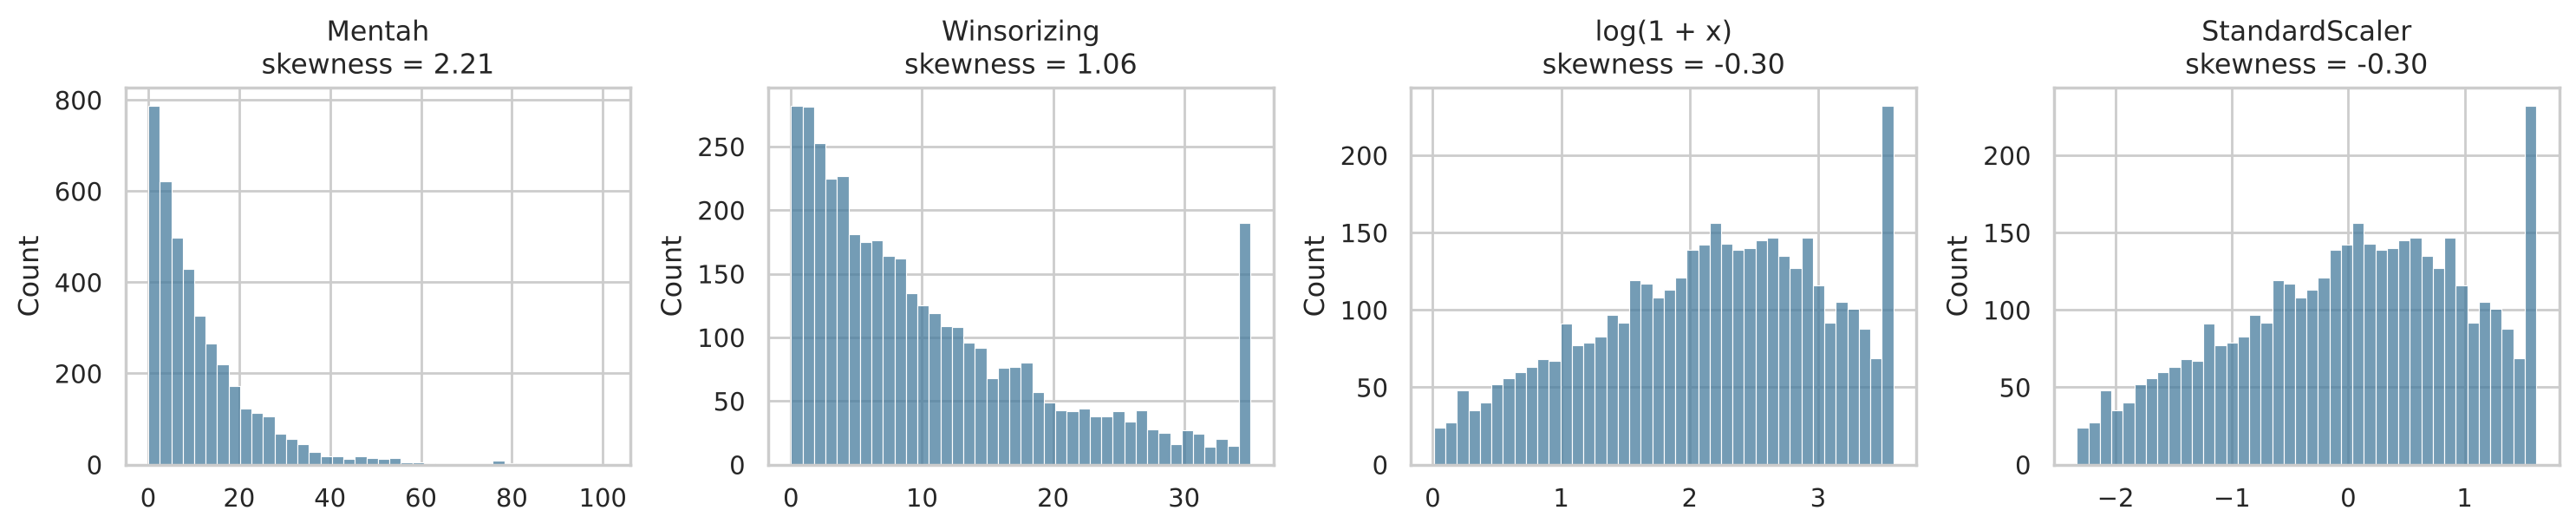

In [15]:
NOM = ["gender", "region", "device", "payment_method", "favorite_genre"]
log1p = FunctionTransformer(np.log1p, feature_names_out="one-to-one")
def build_pre():
    return ColumnTransformer([
        ("sub", Pipeline([("o", OrdinalEncoder(categories=[ORDER_SUB])), ("s", StandardScaler())]), ["subscription_type"]),
        ("nom", OneHotEncoder(handle_unknown="ignore", sparse_output=False), NOM),
        ("log", Pipeline([("l", log1p), ("s", StandardScaler())]), ["watch_hours", "avg_watch_time_per_day"]),
        ("num", StandardScaler(), ["age", "last_login_days", "number_of_profiles", "monthly_fee"]),
    ])
CAND = ["subscription_type"] + NOM + ["watch_hours", "avg_watch_time_per_day", "age", "last_login_days", "number_of_profiles", "monthly_fee"]
pre_demo = build_pre()
for d_ in (train, test): d_["subscription_type"] = d_.subscription_type.astype(str)
Atr = pre_demo.fit_transform(train[CAND]); Ate = pre_demo.transform(test[CAND]); names = list(pre_demo.get_feature_names_out())
sc = [i for i, n in enumerate(names) if not n.startswith("nom__")]
print("Ukuran matriks latih/uji:", Atr.shape, Ate.shape, "(1 ordinal + 26 one-hot + 6 numerik)")
print("Data latih: |rerata| maks =", f"{np.abs(Atr[:, sc].mean(0)).max():.1e}", "| std =", np.round(Atr[:, sc].std(0), 2).min(), "-", np.round(Atr[:, sc].std(0), 2).max())
print("Data uji: rerata kolom terskala", round(Ate[:, sc].mean(0).min(), 3), "sampai", round(Ate[:, sc].mean(0).max(), 3))
fig, ax = plt.subplots(1, 4, figsize=(15, 3.2))
w0 = raw.loc[idx_tr, "watch_hours"]; w1 = train.watch_hours; w2 = np.log1p(w1); w3 = StandardScaler().fit_transform(w2.values.reshape(-1, 1)).ravel()
for a, v, t in zip(ax, [w0, w1, w2, w3], ["Mentah", "Winsorizing", "log(1 + x)", "StandardScaler"]):
    sns.histplot(v, bins=40, ax=a, color=BLUE); a.set_title(f"{t}\nskewness = {stats.skew(v):.2f}"); a.set_xlabel("")
savefig("fig11_transformasi_watch_hours.png")

**Alasan dan temuan.**
- **Encoding.** `subscription_type` di-*ordinal encode* (Basic = 0, Standard = 1, Premium = 2) karena memang berurutan dan perlu hemat kolom. Variabel nominal (`payment_method`, dll.) di-*one-hot encode* karena tidak punya urutan; `handle_unknown="ignore"` mencegah galat bila kategori baru muncul di data uji.
- **Scaling.** Seluruh fitur numerik dibakukan dengan `StandardScaler` karena Logistic Regression sensitif terhadap skala (Random Forest dan Gradient Boosting tidak, tetapi tetap tidak dirugikan). Parameter rerata dan simpangan baku dipelajari **dari data latih saja**: terlihat rerata data latih ≈ 0 dan std = 1, sedangkan data uji hanya mendekati (−0,02 sampai 0,05), tanda bahwa tidak ada informasi uji yang bocor ke scaler.
- **Transformasi.** `log1p` pada `watch_hours` menurunkan skewness dari 2,26 (mentah) dan 1,06 (winsorizing) menjadi sekitar −0,3, yaitu hampir simetris, sesuai asumsi model linear.
- Matriks akhir 4.000 × 33 (latih) dan 1.000 × 33 (uji) hanyalah titik awal; 33 kolom ini dikurangi lewat seleksi fitur di 4.5.

### Penanganan data imbalance

In [16]:
print(f"Rasio kelas: {(clean.churned==1).sum()} churn : {(clean.churned==0).sum()} aktif = {(clean.churned==1).sum()/(clean.churned==0).sum():.2f} : 1")
rows = []
for cw in (None, "balanced"):
    for mn, mk in [("LR", lambda cw=cw: LogisticRegression(max_iter=1000, class_weight=cw)),
                   ("RF", lambda cw=cw: RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight=cw, random_state=SEED, n_jobs=-1))]:
        r = cross_validate(Pipeline([("c", build_pre()), ("m", mk())]), train[CAND], ytr, cv=cv, scoring=["roc_auc", "recall"])
        rows.append({"class_weight": str(cw), "model": mn, "ROC-AUC": round(r["test_roc_auc"].mean(), 4), "recall churn": round(r["test_recall"].mean(), 3)})
t_imb = pd.DataFrame(rows); t_imb.to_csv("outputs/uji_imbalance.csv", index=False); display(t_imb)

Rasio kelas: 2515 churn : 2485 aktif = 1.01 : 1


,class_weight,model,ROC-AUC,recall churn
0,None,LR,0.9658,0.895
1,None,RF,0.9964,0.965
2,balanced,LR,0.9658,0.894
3,balanced,RF,0.9963,0.964


**Keputusan dan alasan.** Rasio kelas 1,01 : 1 (hampir sempurna seimbang), sehingga **tidak dilakukan resampling (SMOTE/undersampling) dan tidak memakai `class_weight`**. Keputusan ini diuji: memberi `class_weight="balanced"` tidak mengubah ROC-AUC maupun recall secara berarti (selisih di desimal ke-4). Resampling pada data seimbang hanya menambah kompleksitas dan risiko data sintetis yang menipu. Stratified split dan stratified CV sudah cukup menjaga proporsi kelas.

## 4.5 Feature selection: membuang, membuat, dan memakai fitur
Seluruh perhitungan di bagian ini memakai **data latih saja**. Keputusan memakai tiga lapis bukti: (a) uji statistik terhadap target, (b) *mutual information* dan *permutation importance* dari model (yang menangkap hubungan non-linear), dan (c) eksperimen ablasi (apakah menghapus atau menambah fitur mengubah performa).

### 4.5.1 Bukti per fitur

In [17]:
tr = train.copy(); tr["sub_ord"] = tr.subscription_type.map({"Basic": 0, "Standard": 1, "Premium": 2})
rows = []
for f in ["subscription_type", "payment_method", "favorite_genre", "region", "device", "gender"]:
    t = pd.crosstab(tr[f], ytr); chi2, p, _, _ = stats.chi2_contingency(t, correction=False)
    rows.append({"fitur": f, "uji": "Chi-square", "p": p, "ukuran_efek": f"V = {np.sqrt(chi2/(len(tr)*(min(t.shape)-1))):.3f}"})
for f in ["watch_hours", "last_login_days", "number_of_profiles", "monthly_fee", "avg_watch_time_per_day", "age"]:
    u, p = stats.mannwhitneyu(tr.loc[ytr == 1, f], tr.loc[ytr == 0, f]); auc = max(u / (ytr.sum() * (1 - ytr).sum()), 1 - u / (ytr.sum() * (1 - ytr).sum()))
    ef = f"AUC univariat = {auc:.3f}"
    if f == "number_of_profiles":
        t = pd.crosstab(tr[f], ytr); chi2 = stats.chi2_contingency(t, correction=False)[0]; ef += f"; V = {np.sqrt(chi2/(len(tr)*(min(t.shape)-1))):.3f}"
    rows.append({"fitur": f, "uji": "Mann-Whitney U", "p": p, "ukuran_efek": ef})
sel = pd.DataFrame(rows).set_index("fitur")

Xmi = tr[CAND].copy()
for c in ["subscription_type"] + NOM: Xmi[c] = Xmi[c].astype("category").cat.codes
disc = [c in ["subscription_type"] + NOM + ["last_login_days", "number_of_profiles", "monthly_fee", "age"] for c in Xmi.columns]
sel["MI"] = pd.Series(mutual_info_classif(Xmi, ytr, discrete_features=disc, random_state=SEED), index=Xmi.columns).round(4)

rng = np.random.RandomState(SEED); imp = {f: [] for f in CAND}
for a, b in cv.split(train[CAND], ytr):
    p_ = Pipeline([("c", build_pre()), ("m", RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=SEED, n_jobs=-1))]).fit(train[CAND].iloc[a], ytr.iloc[a])
    Xb, yb = train[CAND].iloc[b], ytr.iloc[b]; base = roc_auc_score(yb, p_.predict_proba(Xb)[:, 1])
    for f in CAND:
        for _ in range(5):
            Xp = Xb.copy(); Xp[f] = rng.permutation(Xp[f].values); imp[f].append(base - roc_auc_score(yb, p_.predict_proba(Xp)[:, 1]))
pi = pd.DataFrame({"mean": {f: np.mean(v) for f, v in imp.items()}, "sd": {f: np.std(v) for f, v in imp.items()}})
sel["permutation_importance"] = pi.apply(lambda r: f"{r['mean']:.4f} ± {r['sd']:.4f}", axis=1)
keputusan = {"watch_hours": "PAKAI", "last_login_days": "PAKAI (diuji leakage)", "number_of_profiles": "PAKAI", "subscription_type": "PAKAI", "payment_method": "PAKAI",
             "monthly_fee": "BUANG (redundan)", "avg_watch_time_per_day": "BUANG (turunan/leakage)",
             "favorite_genre": "BUANG", "region": "BUANG", "device": "BUANG", "age": "BUANG", "gender": "BUANG"}
sel["keputusan"] = pd.Series(keputusan); sel["p"] = sel.p.map(lambda v: "< 0,001" if v < .001 else f"{v:.3f}")
sel = sel.loc[list(keputusan)]; sel.to_csv("outputs/bukti_seleksi_fitur.csv"); display(sel)

,uji,p,ukuran_efek,MI,permutation_importance,keputusan
fitur,,,,,,
watch_hours,Mann-Whitney U,"< 0,001",AUC univariat = 0.808,0.1924,0.0402 ± 0.0055,PAKAI
last_login_days,Mann-Whitney U,"< 0,001",AUC univariat = 0.775,0.1448,0.0554 ± 0.0058,PAKAI (diuji leakage)
number_of_profiles,Mann-Whitney U,"< 0,001",AUC univariat = 0.594; V = 0.197,0.0195,0.0314 ± 0.0033,PAKAI
subscription_type,Chi-square,"< 0,001",V = 0.147,0.0109,0.0048 ± 0.0023,PAKAI
payment_method,Chi-square,"< 0,001",V = 0.139,0.0097,0.0153 ± 0.0025,PAKAI
monthly_fee,Mann-Whitney U,"< 0,001",AUC univariat = 0.569,0.0109,0.0054 ± 0.0016,BUANG (redundan)
avg_watch_time_per_day,Mann-Whitney U,"< 0,001",AUC univariat = 0.922,0.3676,0.1404 ± 0.0124,BUANG (turunan/leakage)
favorite_genre,Chi-square,0.103,V = 0.051,0.0013,-0.0001 ± 0.0001,BUANG
region,Chi-square,0.731,V = 0.026,0.0003,-0.0001 ± 0.0002,BUANG


**Alasan membuang (7 fitur).**
- `avg_watch_time_per_day`: kolom **turunan** dari `watch_hours` dan `last_login_days` (rumus terbukti di 4.1). Terlihat paling kuat (AUC univariat 0,92, permutation importance tertinggi) justru **karena rumusnya memuat dua fitur lain**, bukan karena informasi baru. Memakainya menggandakan informasi yang sama dan memperbesar risiko kebocoran, jadi dibuang.
- `monthly_fee`: berpadanan 1:1 dengan `subscription_type`, sehingga informasinya sama. Dipertahankan `subscription_type` karena lebih mudah ditafsirkan.
- `favorite_genre`, `region`, `device`, `age`, `gender`: tidak signifikan (p 0,10–0,96), ukuran efek mendekati nol (V ≤ 0,051; AUC univariat `age` 0,504), MI sangat kecil (≤ 0,007), dan permutation importance sama dengan nol (mengacak kolom ini tidak mengubah ROC-AUC). Menambahkannya hanya menambah *noise* dan 18 kolom one-hot. Secara etika, `age`, `gender`, `region` juga sensitif dan tidak layak dipakai untuk memperlakukan pelanggan berbeda.

**Alasan memakai (5 fitur).** `watch_hours`, `last_login_days`, `number_of_profiles`, `subscription_type`, dan `payment_method` signifikan secara statistik (p < 0,001), punya ukuran efek yang berarti, dan permutation importance-nya positif melebihi simpangan baku (kecuali `subscription_type` yang kecil tetapi tetap positif di atas simpangan bakunya). `last_login_days` dipakai tetapi **diuji secara khusus terhadap risiko leakage** (bagian 5).

### 4.5.2 Pembuatan fitur baru

In [18]:
def add_new(d):
    d = d.copy()
    d["inactive_30d"] = (d.last_login_days > 30).astype(int)
    d["multi_profile"] = (d.number_of_profiles >= 4).astype(int)
    d["risky_payment"] = d.payment_method.isin(["Crypto", "Gift Card"]).astype(int)
    d["sub_ord"] = d.subscription_type.map({"Basic": 0, "Standard": 1, "Premium": 2})
    d["wh_log"] = np.log1p(d.watch_hours); d["avg_log"] = np.log1p(d.avg_watch_time_per_day)
    return d
tr2, te2 = add_new(train), add_new(test)
rows = []
for f, definisi in [("inactive_30d", "1 bila last_login_days > 30"), ("multi_profile", "1 bila number_of_profiles >= 4"), ("risky_payment", "1 bila Crypto atau Gift Card")]:
    r = tr2.groupby(f).churned.mean() * 100; t = pd.crosstab(tr2[f], ytr); chi2, p, _, _ = stats.chi2_contingency(t, correction=False)
    rows.append({"fitur_baru": f, "definisi": definisi, "churn_rate_0_%": round(r[0], 1), "churn_rate_1_%": round(r[1], 1),
                 "Cramers_V": round(np.sqrt(chi2 / len(tr2)), 3), "p": p})
t_new = pd.DataFrame(rows); t_new.to_csv("outputs/fitur_baru.csv", index=False); display(t_new)

,fitur_baru,definisi,churn_rate_0_%,churn_rate_1_%,Cramers_V,p
0,inactive_30d,1 bila last_login_days > 30,25.8,75.1,0.494,6.709893e-214
1,multi_profile,1 bila number_of_profiles >= 4,58.4,38.5,0.196,3.082223e-35
2,risky_payment,1 bila Crypto atau Gift Card,44.8,58.7,0.136,8.579769e-18


**Alasan membuat fitur baru.** Ketiganya diturunkan dari pola yang **sudah terlihat pada EDA**, bukan dicoba acak. `inactive_30d` memisahkan pelanggan dengan churn sekitar 26 % dari sekitar 75 %, asosiasi terkuat di antara fitur biner (V ≈ 0,49); alasannya lonjakan churn setelah 30 hari (EDA 3.3). `multi_profile` menandai akun 4–5 profil yang churn-nya turun tajam (EDA 3.4), dan `risky_payment` menandai Crypto/Gift Card yang churn-nya jauh lebih tinggi (EDA 3.4). Fitur ini membantu terutama model linear; model berbasis pohon sebenarnya bisa menemukan ambangnya sendiri, namun fitur biner tetap membuat interpretasi lebih mudah. Nilai bersihnya diuji pada ablasi berikut.

### 4.5.3 Ablasi: apakah keputusan seleksi memperbaiki performa?

,n_fitur,LR ROC-AUC,LR recall,RF ROC-AUC,RF recall
Skenario,,,,,
S1 Semua fitur (12 kolom),12,0.9658 ± 0.0026,0.895,0.9964 ± 0.0021,0.966
S2 Semua tanpa avg_watch_time_per_day,11,0.9622 ± 0.0043,0.883,0.9963 ± 0.0012,0.967
S3 Terpilih (5 kolom),5,0.9613 ± 0.0047,0.883,0.9982 ± 0.0006,0.971
S4 Terpilih + 3 fitur baru,8,0.9728 ± 0.0017,0.907,0.9979 ± 0.0006,0.971
S5 Terpilih tanpa last_login_days,4,0.8420 ± 0.0083,0.750,0.8668 ± 0.0091,0.743
S6 Terpilih + age/gender/region/device/genre,10,0.9605 ± 0.0041,0.881,0.9952 ± 0.0016,0.962


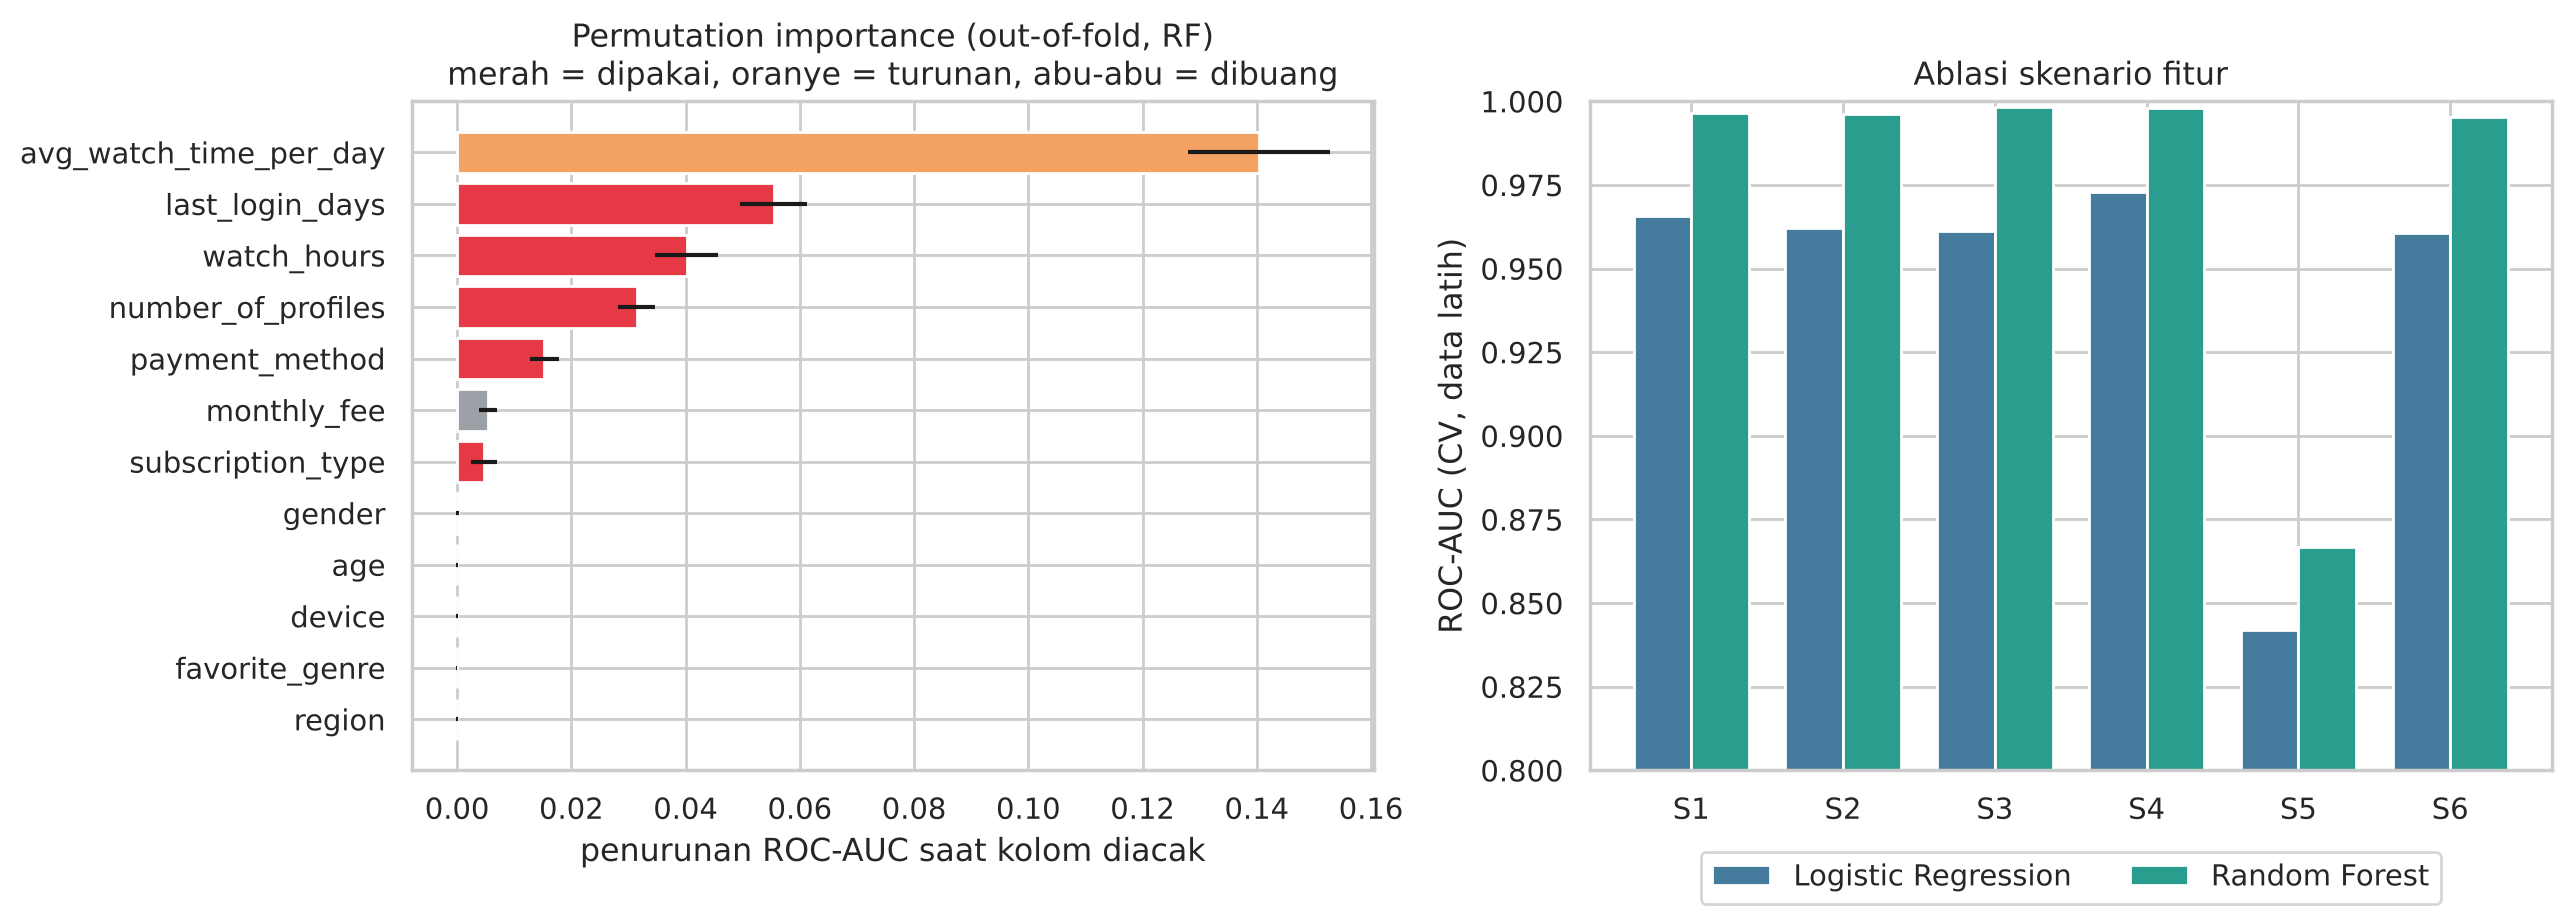

In [19]:
core = ["wh_log", "last_login_days", "sub_ord", "number_of_profiles"]
SCEN_ABL = {
 "S1 Semua fitur (12 kolom)": (core + ["age", "monthly_fee", "avg_log"], NOM),
 "S2 Semua tanpa avg_watch_time_per_day": (core + ["age", "monthly_fee"], NOM),
 "S3 Terpilih (5 kolom)": (core, ["payment_method"]),
 "S4 Terpilih + 3 fitur baru": (core + ["inactive_30d", "multi_profile", "risky_payment"], ["payment_method"]),
 "S5 Terpilih tanpa last_login_days": (["wh_log", "sub_ord", "number_of_profiles"], ["payment_method"]),
 "S6 Terpilih + age/gender/region/device/genre": (core + ["age"], ["gender", "region", "device", "favorite_genre", "payment_method"]),
}
rows = []
for nama, (nu, ca) in SCEN_ABL.items():
    row = {"Skenario": nama, "n_fitur": len(nu) + len(ca)}
    for mn, mk in [("LR", lambda: LogisticRegression(max_iter=1000)),
                   ("RF", lambda: RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=SEED, n_jobs=-1))]:
        ct = ColumnTransformer([("n", StandardScaler(), nu), ("c", OneHotEncoder(handle_unknown="ignore"), ca)])
        r = cross_validate(Pipeline([("c", ct), ("m", mk())]), tr2, ytr, cv=cv, scoring=["roc_auc", "recall"])
        row[f"{mn} ROC-AUC"] = f"{r['test_roc_auc'].mean():.4f} ± {r['test_roc_auc'].std():.4f}"; row[f"{mn} recall"] = round(r["test_recall"].mean(), 3)
    rows.append(row)
t_abl = pd.DataFrame(rows).set_index("Skenario"); t_abl.to_csv("outputs/ablasi_fitur.csv"); display(t_abl)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))
p_ = pi["mean"].sort_values(); colr = [RED if f in ["watch_hours", "last_login_days", "number_of_profiles", "subscription_type", "payment_method"] else ORANGE if f == "avg_watch_time_per_day" else GREY for f in p_.index]
ax[0].barh(p_.index, p_.values, xerr=pi.loc[p_.index, "sd"], color=colr); ax[0].set_xlabel("penurunan ROC-AUC saat kolom diacak"); ax[0].set_title("Permutation importance (out-of-fold, RF)\nmerah = dipakai, oranye = turunan, abu-abu = dibuang")
x = np.arange(len(t_abl)); w = .38
ax[1].bar(x - w/2, t_abl["LR ROC-AUC"].str.split(" ").str[0].astype(float), w, label="Logistic Regression", color=BLUE)
ax[1].bar(x + w/2, t_abl["RF ROC-AUC"].str.split(" ").str[0].astype(float), w, label="Random Forest", color=TEAL)
ax[1].set_xticks(x); ax[1].set_xticklabels([s.split()[0] for s in t_abl.index]); ax[1].set_ylim(.8, 1.0); ax[1].set_ylabel("ROC-AUC (CV, data latih)")
ax[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2); ax[1].set_title("Ablasi skenario fitur")
savefig("fig12_permutation_dan_ablasi.png")

**Temuan ablasi.**
- **S3 vs S1/S2:** membuang `age`, `monthly_fee`, `avg_watch_time_per_day`, dan empat kolom kategorikal **tidak menurunkan performa**: ROC-AUC Logistic Regression S3 (0,9613) hampir sama dengan S1 (0,9658), dan Random Forest justru naik (0,998 vs 0,996). Jadi 7 fitur yang dibuang memang tidak berguna.
- **S4 vs S3:** tiga fitur baru menaikkan ROC-AUC Logistic Regression dari 0,961 menjadi 0,973 dan recall dari 0,883 menjadi 0,907, sedangkan Random Forest tetap (sudah menemukan ambangnya sendiri). Fitur baru berguna untuk model linear.
- **S6 vs S3:** menambahkan demografi/genre/perangkat tidak membantu sama sekali (bahkan sedikit menurun), memperkuat keputusan membuangnya.
- **S5 (tanpa `last_login_days`):** ROC-AUC **anjlok** ke 0,84–0,87 dan recall ke 0,74–0,75. Fitur ini sangat menentukan, dan karena itu juga paling perlu diwaspadai sebagai sumber kebocoran. Hal ini menjadi dasar dua skenario model di bagian 5.

### 4.5.4 Himpunan fitur akhir

| Skenario | Fitur | Kolom setelah encoding |
|---|---|---|
| **A: lengkap** | `wh_log`, `last_login_days`, `sub_ord`, `number_of_profiles`, `payment_method`, `inactive_30d`, `multi_profile`, `risky_payment` | 12 |
| **B: konservatif** (tanpa fitur recency) | `wh_log`, `sub_ord`, `number_of_profiles`, `payment_method`, `multi_profile`, `risky_payment` | 10 |

Dua skenario dibuat karena `last_login_days` (dan turunannya `inactive_30d`) berpotensi **kebocoran temporal**: dataset tidak mencatat kapan nilai itu diukur, sehingga mungkin saja nilainya terbentuk *setelah* pelanggan berhenti. Skenario A menunjukkan batas atas performa; skenario B adalah versi yang klaimnya bisa dipertahankan tanpa asumsi tentang waktu pengukuran.

In [20]:
FEATS = {
 "A": dict(num=["wh_log", "last_login_days", "sub_ord", "number_of_profiles"], cat=["payment_method"], bin=["inactive_30d", "multi_profile", "risky_payment"]),
 "B": dict(num=["wh_log", "sub_ord", "number_of_profiles"], cat=["payment_method"], bin=["multi_profile", "risky_payment"]),
}
def make_pre(f):
    return ColumnTransformer([("n", StandardScaler(), f["num"]), ("c", OneHotEncoder(handle_unknown="ignore", sparse_output=False), f["cat"]), ("b", "passthrough", f["bin"])])
for k, f in FEATS.items():
    pp = make_pre(f).fit(tr2); nm_ = [n.split("__")[1] for n in pp.get_feature_names_out()]
    print(k, "->", len(nm_), "kolom:", nm_)
    pd.DataFrame(pp.transform(tr2), columns=nm_).assign(churned=ytr.values).to_csv(f"outputs/train_processed_{k}.csv", index=False)
    pd.DataFrame(pp.transform(te2), columns=nm_).assign(churned=yte.values).to_csv(f"outputs/test_processed_{k}.csv", index=False)
HASIL["n_train"], HASIL["n_test"] = len(tr2), len(te2)

A -> 12 kolom: ['wh_log', 'last_login_days', 'sub_ord', 'number_of_profiles', 'payment_method_Credit Card', 'payment_method_Crypto', 'payment_method_Debit Card', 'payment_method_Gift Card', 'payment_method_PayPal', 'inactive_30d', 'multi_profile', 'risky_payment']
B -> 10 kolom: ['wh_log', 'sub_ord', 'number_of_profiles', 'payment_method_Credit Card', 'payment_method_Crypto', 'payment_method_Debit Card', 'payment_method_Gift Card', 'payment_method_PayPal', 'multi_profile', 'risky_payment']


---
# 5. Modelling

## 5.1 Pemilihan model dan alasannya
| Model | Peran | Alasan dipilih |
|---|---|---|
| **Dummy (majority/prior)** | *baseline* | batas bawah: model apa pun harus mengalahkan tebakan tanpa fitur (akurasi ≈ 50,3 %, ROC-AUC 0,5) |
| **Logistic Regression** | model linear yang dapat ditafsirkan | koefisiennya bisa dibaca sebagai arah dan kekuatan pengaruh; cocok untuk menjelaskan ke tim bisnis; cepat dan stabil pada 4.000 baris |
| **Random Forest** | model non-linear berbasis pohon | EDA menunjukkan interaksi recency × intensitas dan ambang (30 hari, 4 profil) yang sulit ditangkap model linear; kuat terhadap skala dan outlier; sulit overfit dibanding satu pohon |
| **Histogram Gradient Boosting** | boosting berbasis pohon | umumnya kuat pada data tabular; membangun pohon berurutan yang memperbaiki kesalahan sebelumnya, sehingga bisa menangkap interaksi halus |

Model lain (KNN, SVM, *deep learning*) tidak dipakai: data tabular kecil dengan hanya 6–9 fitur tidak memerlukan kerumitan itu, dan menambah kandidat berarti menambah risiko *overfitting* pada seleksi model tanpa alasan yang jelas.

## 5.2 Test design (rancangan pengujian)
Rancangan pengujian ditetapkan **sebelum** model dilatih, supaya perbandingan antar model adil dan data uji tidak ikut memengaruhi keputusan.

| Komponen | Rancangan | Alasan |
|---|---|---|
| Tujuan pengujian | mengukur seberapa baik model memisahkan pelanggan churn dari aktif pada data baru | sesuai P3 di Business Understanding |
| Pembagian data | hold-out stratified **80 % latih (4.000) : 20 % uji (1.000)**, `random_state = 42` (bagian 4.4) | stratifikasi menjaga proporsi churn 50,3 % di kedua bagian |
| Validasi selama pengembangan | validasi silang 5-lipatan stratified **hanya pada data latih** | memilih model dan hyperparameter tanpa menyentuh data uji |
| Metrik utama | **recall kelas churn** (≥ 0,75) dan **ROC-AUC** (≥ 0,80) | lihat 1.4: melewatkan churn lebih mahal; ROC-AUC tidak bergantung ambang |
| Metrik pendukung | precision, F1, akurasi, matriks konfusi, kurva ROC dan PR | precision menjaga biaya kampanye; akurasi aman karena kelas seimbang |
| Pembanding | *baseline* majority-class | batas bawah yang harus dikalahkan |
| Aturan memilih model | satu standard error pada ROC-AUC CV, lalu recall CV, lalu kesederhanaan (5.3) | mencegah memilih berdasarkan selisih yang hanya noise |
| Kontrol kebocoran | encoder dan scaler di-*fit* hanya pada data latih; seleksi fitur hanya pada data latih; `last_login_days` diuji lewat dua skenario (A dan B) | data uji tidak boleh memengaruhi keputusan; risiko *temporal leakage* |
| Penentuan ambang | dari prediksi *out-of-fold* data latih, bukan data uji (6.4) | menghindari mengintip data uji |
| Penggunaan data uji | satu kali, pada tahap Evaluasi (bagian 6) | estimasi performa yang jujur |
| Ketidakpastian | interval kepercayaan bootstrap 95 % (6.5) | data uji hanya 1.000 baris |

## 5.3 Strategi tuning dan seleksi
- **Tuning:** `GridSearchCV` 5-lipatan stratified **pada data latih**, dengan ROC-AUC sebagai kriteria utama (tidak bergantung ambang) dan recall dicatat sebagai metrik bisnis.
- **Aturan memilih model (ditetapkan sebelum melihat data uji):** ambil model dengan ROC-AUC CV tertinggi; bila ada model lain yang selisihnya dalam **satu standard error**, pilih yang **recall CV-nya lebih tinggi** (metrik utama bisnis); bila masih sama, pilih yang lebih sederhana. Ini mencegah memilih model hanya karena selisih desimal yang sebenarnya noise.
- **Data uji hanya dipakai sekali**, di bagian 6.

,skenario,model,params,CV ROC-AUC,SD,CV recall,CV akurasi
0,A,Baseline (majority),-,0.5000,0.0000,1.000,0.503
1,A,Logistic Regression,{'C': 1},0.9728,0.0018,0.906,0.906
2,A,Random Forest,"{'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 300}",0.9989,0.0006,0.981,0.984
3,A,Gradient Boosting,"{'learning_rate': 0.1, 'max_depth': None, 'max_iter': 100, 'min_samples_leaf': 20}",0.9995,0.0003,0.987,0.989
4,B,Baseline (majority),-,0.5000,0.0000,1.000,0.503
5,B,Logistic Regression,{'C': 1},0.8450,0.0095,0.742,0.752
6,B,Random Forest,"{'max_depth': 8, 'min_samples_leaf': 10, 'n_estimators': 300}",0.8706,0.0087,0.721,0.761
7,B,Gradient Boosting,"{'learning_rate': 0.03, 'max_depth': 3, 'max_iter': 300, 'min_samples_leaf': 50}",0.8738,0.0085,0.732,0.763


Skenario A: AUC CV tertinggi = Gradient Boosting (0.9995, SE 0.0001); kandidat dalam 1 SE = ['Gradient Boosting'] -> terpilih: Gradient Boosting
Skenario B: AUC CV tertinggi = Gradient Boosting (0.8738, SE 0.0038); kandidat dalam 1 SE = ['Random Forest', 'Gradient Boosting'] -> terpilih: Gradient Boosting


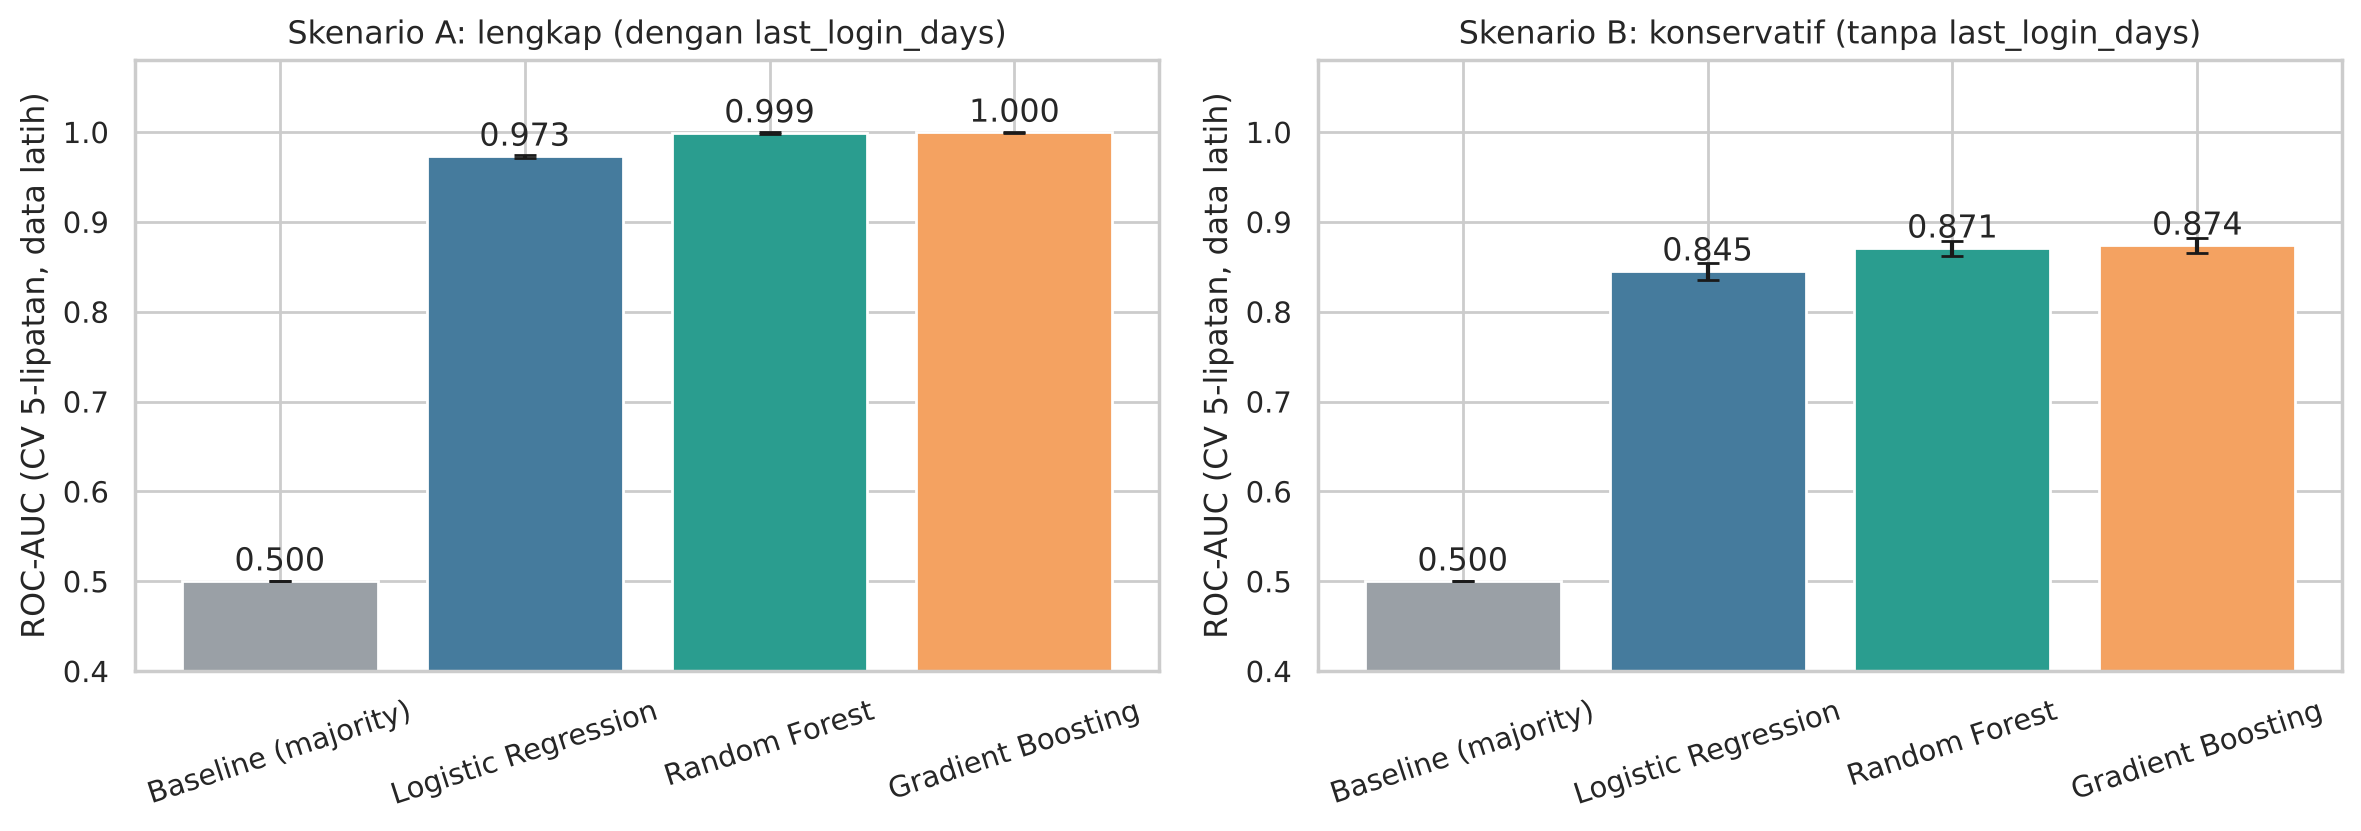

In [21]:
GRIDS = {
 "Logistic Regression": (LogisticRegression(max_iter=2000), {"m__C": [0.01, 0.1, 1, 10]}),
 "Random Forest": (RandomForestClassifier(random_state=SEED, n_jobs=-1),
                   {"m__n_estimators": [300], "m__max_depth": [None, 8, 12], "m__min_samples_leaf": [1, 5, 10]}),
 "Gradient Boosting": (HistGradientBoostingClassifier(random_state=SEED),
                       {"m__learning_rate": [0.03, 0.1], "m__max_depth": [3, None], "m__max_iter": [100, 300], "m__min_samples_leaf": [20, 50]}),
}
SIMPLE = {"Logistic Regression": 0, "Random Forest": 1, "Gradient Boosting": 2}
tuned, cvrows = {}, []
for sk in ["A", "B"]:
    d = Pipeline([("p", make_pre(FEATS[sk])), ("m", DummyClassifier(strategy="prior"))]).fit(tr2, ytr)
    r = cross_validate(d, tr2, ytr, cv=cv, scoring=["roc_auc", "recall", "accuracy"])
    cvrows.append({"skenario": sk, "model": "Baseline (majority)", "params": "-", "CV ROC-AUC": r["test_roc_auc"].mean(), "SD": r["test_roc_auc"].std(),
                   "CV recall": r["test_recall"].mean(), "CV akurasi": r["test_accuracy"].mean()})
    tuned[(sk, "Baseline (majority)")] = d
    for nama, (est, grid) in GRIDS.items():
        gs = GridSearchCV(Pipeline([("p", make_pre(FEATS[sk])), ("m", clone(est))]), grid, cv=cv,
                          scoring={"auc": "roc_auc", "recall": "recall", "acc": "accuracy"}, refit="auc", n_jobs=-1).fit(tr2, ytr)
        i = gs.best_index_; rr = gs.cv_results_
        tuned[(sk, nama)] = gs.best_estimator_
        cvrows.append({"skenario": sk, "model": nama, "params": {k.replace("m__", ""): v for k, v in gs.best_params_.items()},
                       "CV ROC-AUC": rr["mean_test_auc"][i], "SD": rr["std_test_auc"][i], "CV recall": rr["mean_test_recall"][i], "CV akurasi": rr["mean_test_acc"][i]})
cvdf = pd.DataFrame(cvrows); cvdf.to_csv("outputs/cv_perbandingan_model.csv", index=False)
display(cvdf.style.format({"CV ROC-AUC": "{:.4f}", "SD": "{:.4f}", "CV recall": "{:.3f}", "CV akurasi": "{:.3f}"}))

# aturan pemilihan: satu standard error, lalu recall CV, lalu kesederhanaan
terpilih = {}
for sk in ["A", "B"]:
    sub = cvdf[(cvdf.skenario == sk) & (cvdf.model != "Baseline (majority)")].copy()
    best = sub.loc[sub["CV ROC-AUC"].idxmax()]; se = best["SD"] / np.sqrt(5)
    kandidat = sub[sub["CV ROC-AUC"] >= best["CV ROC-AUC"] - se].copy()
    kandidat["simple"] = kandidat.model.map(SIMPLE)
    pilih = kandidat.sort_values(["CV recall", "simple"], ascending=[False, True]).iloc[0]
    terpilih[sk] = pilih.model
    print(f"Skenario {sk}: AUC CV tertinggi = {best.model} ({best['CV ROC-AUC']:.4f}, SE {se:.4f}); kandidat dalam 1 SE = {list(kandidat.model)} -> terpilih: {pilih.model}")
HASIL["terpilih"] = terpilih

fig, ax = plt.subplots(1, 2, figsize=(12, 4.3), sharey=False)
for a, sk in zip(ax, ["A", "B"]):
    s = cvdf[cvdf.skenario == sk]
    a.bar(s.model, s["CV ROC-AUC"], yerr=s["SD"], capsize=4, color=[GREY, BLUE, TEAL, ORANGE])
    for i, v in enumerate(s["CV ROC-AUC"]): a.text(i, v + 0.012, f"{v:.3f}", ha="center")
    a.set_ylim(0.4, 1.08); a.set_ylabel("ROC-AUC (CV 5-lipatan, data latih)"); a.tick_params(axis="x", rotation=18)
    a.set_title(f"Skenario {sk}: " + ("lengkap (dengan last_login_days)" if sk == "A" else "konservatif (tanpa last_login_days)"))
savefig("fig13_perbandingan_model_cv.png")

In [22]:
a_, b_ = cvdf[cvdf.skenario == "A"].set_index("model"), cvdf[cvdf.skenario == "B"].set_index("model")
tampil(f"""
**Perbandingan antar model (validasi silang pada data latih).**

- **Semua model jauh mengalahkan baseline.** Baseline berada pada ROC-AUC {idn(a_.loc['Baseline (majority)','CV ROC-AUC'],2)} dan akurasi {idn(a_.loc['Baseline (majority)','CV akurasi'],3)}, setara menebak.
- **Skenario A (dengan `last_login_days`)**: Logistic Regression {idn(a_.loc['Logistic Regression','CV ROC-AUC'],4)}, Random Forest {idn(a_.loc['Random Forest','CV ROC-AUC'],4)}, Gradient Boosting {idn(a_.loc['Gradient Boosting','CV ROC-AUC'],4)}. Model non-linear hampir sempurna, **jauh lebih tinggi daripada model linear**. Ini membuktikan adanya interaksi dan ambang yang tidak bisa ditangkap garis lurus. Skor setinggi ini pada data perilaku manusia adalah **tanda bahaya**, bukan prestasi (dibahas di bagian 6.8).
- **Skenario B (tanpa `last_login_days`)**: Logistic Regression {idn(b_.loc['Logistic Regression','CV ROC-AUC'],4)}, Random Forest {idn(b_.loc['Random Forest','CV ROC-AUC'],4)}, Gradient Boosting {idn(b_.loc['Gradient Boosting','CV ROC-AUC'],4)}. Performa turun sekitar {idn(100*(a_.loc['Random Forest','CV ROC-AUC']-b_.loc['Random Forest','CV ROC-AUC']),0)} poin ROC-AUC dibanding A, tetapi tetap di atas target 0,80. Selisih antar model kini kecil (di bawah satu simpangan baku antara Random Forest dan Gradient Boosting), sehingga **pemilihan tidak boleh didasarkan pada desimal ketiga**.
- **Model terpilih menurut aturan di 5.3:** skenario A = **{terpilih['A']}**, skenario B = **{terpilih['B']}**.
""")


**Perbandingan antar model (validasi silang pada data latih).**

- **Semua model jauh mengalahkan baseline.** Baseline berada pada ROC-AUC 0,50 dan akurasi 0,503, setara menebak.
- **Skenario A (dengan `last_login_days`)**: Logistic Regression 0,9728, Random Forest 0,9989, Gradient Boosting 0,9995. Model non-linear hampir sempurna, **jauh lebih tinggi daripada model linear**. Ini membuktikan adanya interaksi dan ambang yang tidak bisa ditangkap garis lurus. Skor setinggi ini pada data perilaku manusia adalah **tanda bahaya**, bukan prestasi (dibahas di bagian 6.8).
- **Skenario B (tanpa `last_login_days`)**: Logistic Regression 0,8450, Random Forest 0,8706, Gradient Boosting 0,8738. Performa turun sekitar 13 poin ROC-AUC dibanding A, tetapi tetap di atas target 0,80. Selisih antar model kini kecil (di bawah satu simpangan baku antara Random Forest dan Gradient Boosting), sehingga **pemilihan tidak boleh didasarkan pada desimal ketiga**.
- **Model terpilih menurut aturan di 5.3:** skenario A = **Gradient Boosting**, skenario B = **Gradient Boosting**.


## 5.4 Log iterasi pemodelan

In [23]:
def ab(nama, kol): return t_abl.loc[nama, kol].split(" ")[0]
S1, S3, S4, S5 = "S1 Semua fitur (12 kolom)", "S3 Terpilih (5 kolom)", "S4 Terpilih + 3 fitur baru", "S5 Terpilih tanpa last_login_days"
iterasi = pd.DataFrame([
 {"Iterasi": 1, "Yang dilakukan": "Model awal dengan semua fitur (S1)", "Hasil (ROC-AUC CV, LR / RF)": f"{ab(S1,'LR ROC-AUC')} / {ab(S1,'RF ROC-AUC')}",
  "Temuan dan keputusan": "`avg_watch_time_per_day` paling dominan padahal turunan dari dua fitur lain (kebocoran); banyak fitur tidak berasosiasi. Lanjut: buang fitur turunan dan fitur tidak berguna."},
 {"Iterasi": 2, "Yang dilakukan": "Buang 7 fitur (S3)", "Hasil (ROC-AUC CV, LR / RF)": f"{ab(S3,'LR ROC-AUC')} / {ab(S3,'RF ROC-AUC')}",
  "Temuan dan keputusan": "Performa tidak turun (RF justru naik) dengan 5 fitur saja. Keputusan seleksi dipertahankan."},
 {"Iterasi": 3, "Yang dilakukan": "Tambah 3 fitur rekayasa dari pola EDA (S4)", "Hasil (ROC-AUC CV, LR / RF)": f"{ab(S4,'LR ROC-AUC')} / {ab(S4,'RF ROC-AUC')}",
  "Temuan dan keputusan": "Model linear membaik (ambang 30 hari dan 4 profil tertangkap), pohon tetap. Fitur baru dipakai."},
 {"Iterasi": 4, "Yang dilakukan": "Uji kebocoran: buang `last_login_days` (S5, lalu skenario B)", "Hasil (ROC-AUC CV, LR / RF)": f"{ab(S5,'LR ROC-AUC')} / {ab(S5,'RF ROC-AUC')}",
  "Temuan dan keputusan": "Skor turun tajam: sebagian besar performa bersumber dari satu fitur yang mungkin akibat churn. Keputusan: dua skenario, B (tanpa fitur recency) dijadikan model utama."},
 {"Iterasi": 5, "Yang dilakukan": "Tuning 3 model dengan GridSearchCV (5.3)", "Hasil (ROC-AUC CV, LR / RF)": f"B: {b_.loc['Logistic Regression','CV ROC-AUC']:.4f} / {b_.loc['Random Forest','CV ROC-AUC']:.4f} (GB {b_.loc['Gradient Boosting','CV ROC-AUC']:.4f})",
  "Temuan dan keputusan": "Selisih antar model pada skenario B kecil; dipilih lewat aturan satu standard error, bukan skor tertinggi."},
 {"Iterasi": 6, "Yang dilakukan": "Evaluasi pada data uji, recall pada ambang 0,5 di bawah target", "Hasil (ROC-AUC CV, LR / RF)": "lihat 6.4",
  "Temuan dan keputusan": "Ambang diturunkan berdasarkan prediksi out-of-fold data latih (bukan data uji) sampai recall CV ≥ 0,80, lalu dievaluasi sekali pada data uji."},
])
iterasi.to_csv("outputs/log_iterasi.csv", index=False)
display(iterasi.style.hide(axis="index"))

Iterasi,Yang dilakukan,"Hasil (ROC-AUC CV, LR / RF)",Temuan dan keputusan
1,Model awal dengan semua fitur (S1),0.9658 / 0.9964,`avg_watch_time_per_day` paling dominan padahal turunan dari dua fitur lain (kebocoran); banyak fitur tidak berasosiasi. Lanjut: buang fitur turunan dan fitur tidak berguna.
2,Buang 7 fitur (S3),0.9613 / 0.9982,Performa tidak turun (RF justru naik) dengan 5 fitur saja. Keputusan seleksi dipertahankan.
3,Tambah 3 fitur rekayasa dari pola EDA (S4),0.9728 / 0.9979,"Model linear membaik (ambang 30 hari dan 4 profil tertangkap), pohon tetap. Fitur baru dipakai."
4,"Uji kebocoran: buang `last_login_days` (S5, lalu skenario B)",0.8420 / 0.8668,"Skor turun tajam: sebagian besar performa bersumber dari satu fitur yang mungkin akibat churn. Keputusan: dua skenario, B (tanpa fitur recency) dijadikan model utama."
5,Tuning 3 model dengan GridSearchCV (5.3),B: 0.8450 / 0.8706 (GB 0.8738),"Selisih antar model pada skenario B kecil; dipilih lewat aturan satu standard error, bukan skor tertinggi."
6,"Evaluasi pada data uji, recall pada ambang 0,5 di bawah target",lihat 6.4,"Ambang diturunkan berdasarkan prediksi out-of-fold data latih (bukan data uji) sampai recall CV ≥ 0,80, lalu dievaluasi sekali pada data uji."


**Yang dipelajari dari rangkaian iterasi.** Perbaikan terbesar tidak datang dari memperumit model, tetapi dari **memeriksa isi fitur** (iterasi 1 dan 4). Skor yang tinggi pada iterasi awal justru alasan untuk curiga, bukan untuk berhenti.

---
# 6. Evaluasi
Evaluasi akhir pada **data uji hold-out 20 % (1.000 pelanggan)** yang belum pernah dipakai untuk keputusan apa pun. Ambang klasifikasi awal 0,5.

## 6.1 Metrik semua model pada data uji

In [24]:
def skor(model, X, y, thr=0.5):
    p = model.predict_proba(X)[:, 1]; yh = (p >= thr).astype(int)
    return p, {"ROC-AUC": roc_auc_score(y, p), "Recall (churn)": recall_score(y, yh), "Precision": precision_score(y, yh, zero_division=0),
               "F1": f1_score(y, yh), "Akurasi": accuracy_score(y, yh)}
pred, rows = {}, []
for (sk, nama), m in tuned.items():
    p, s = skor(m, te2, yte); pred[(sk, nama)] = p
    rows.append({"skenario": sk, "model": nama, "dipilih": "✔" if terpilih.get(sk) == nama else "", **s})
ev = pd.DataFrame(rows); ev.to_csv("outputs/evaluasi_data_uji.csv", index=False)
display(ev.style.format({c: "{:.4f}" for c in ["ROC-AUC", "Recall (churn)", "Precision", "F1", "Akurasi"]}))
MA, MB = tuned[("A", terpilih["A"])], tuned[("B", terpilih["B"])]
sA = ev[(ev.skenario == "A") & (ev.dipilih == "✔")].iloc[0]; sB = ev[(ev.skenario == "B") & (ev.dipilih == "✔")].iloc[0]
HASIL["uji"] = {"A": {k: float(sA[k]) for k in ["ROC-AUC", "Recall (churn)", "Precision", "F1", "Akurasi"]},
                "B": {k: float(sB[k]) for k in ["ROC-AUC", "Recall (churn)", "Precision", "F1", "Akurasi"]}}

,skenario,model,dipilih,ROC-AUC,Recall (churn),Precision,F1,Akurasi
0,A,Baseline (majority),,0.5000,1.0000,0.5030,0.6693,0.5030
1,A,Logistic Regression,,0.9756,0.9125,0.9162,0.9143,0.9140
2,A,Random Forest,,0.9996,0.9861,0.9940,0.9900,0.9900
3,A,Gradient Boosting,✔,0.9999,0.9960,0.9960,0.9960,0.9960
4,B,Baseline (majority),,0.5000,1.0000,0.5030,0.6693,0.5030
5,B,Logistic Regression,,0.8646,0.7833,0.7650,0.7741,0.7700
6,B,Random Forest,,0.8779,0.7555,0.7966,0.7755,0.7800
7,B,Gradient Boosting,✔,0.8747,0.7416,0.7836,0.7620,0.7670


## 6.2 Matriks konfusi model terpilih (ambang 0,5)

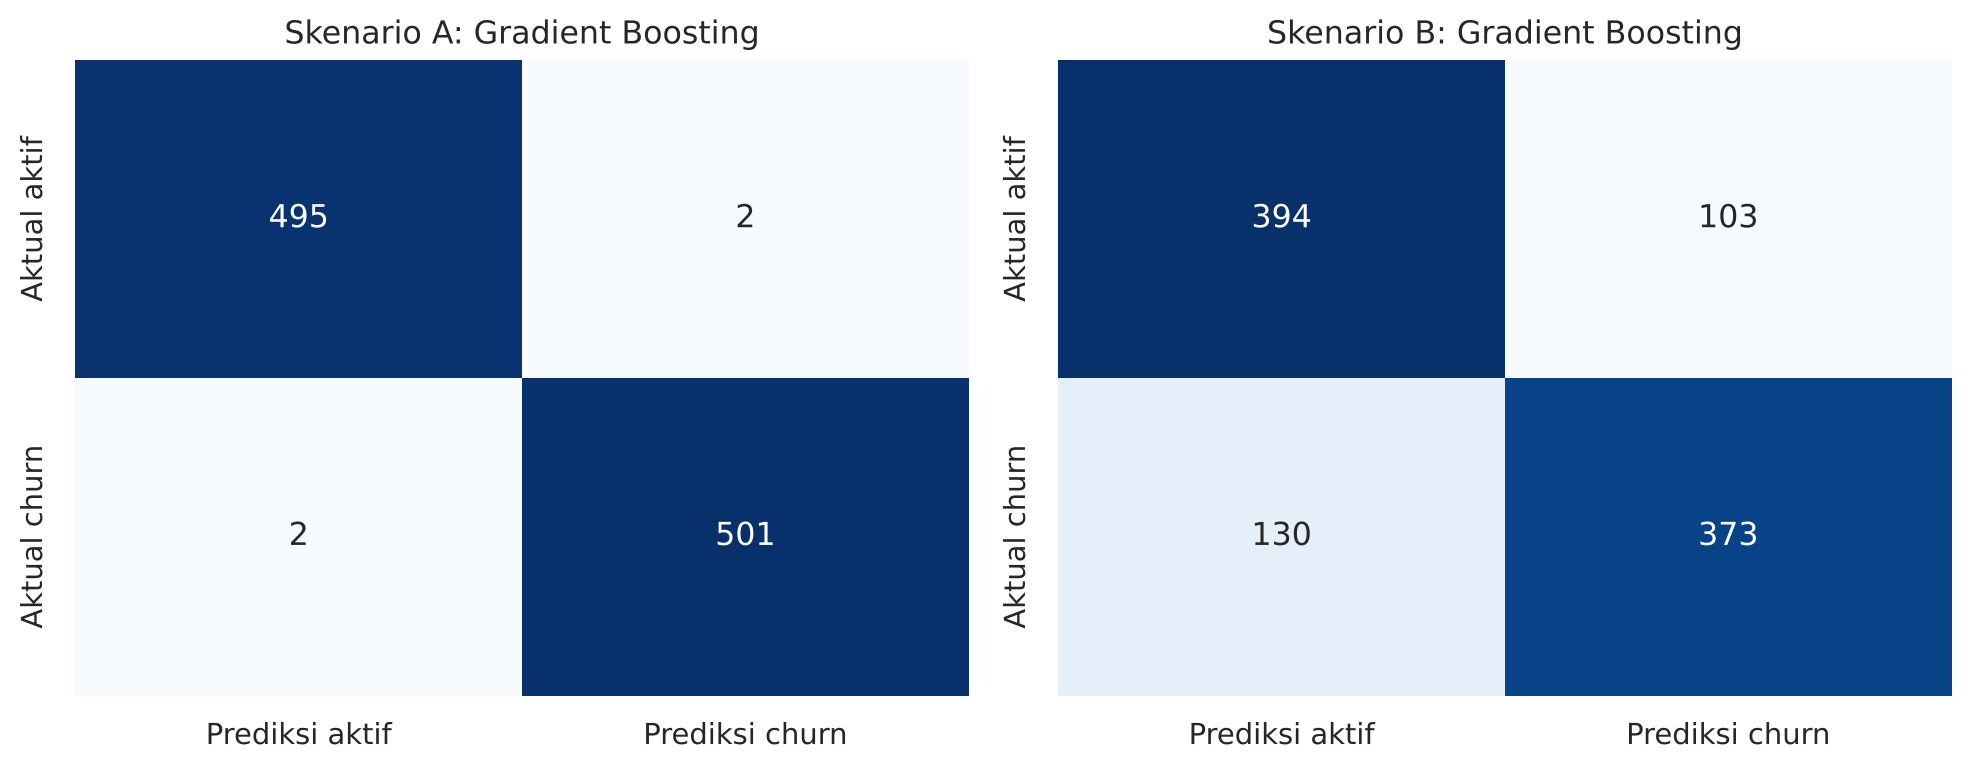


**Cara membaca (skenario B, Gradient Boosting).** Dari **503 pelanggan yang benar-benar churn**, model menangkap **373** (*true positive*) dan melewatkan **130** (*false negative*). Dari **497 pelanggan yang sebenarnya aktif**, model salah menandai **103** sebagai churn (*false positive*) dan benar menandai 394. Kesalahan jenis *false negative* (130) lebih mahal bagi bisnis karena itu pelanggan yang hilang tanpa sempat dihubungi, sedangkan *false positive* (103) hanya biaya kampanye yang sebenarnya tidak diperlukan.


In [25]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, (sk, m) in zip(ax, [("A", MA), ("B", MB)]):
    cm = confusion_matrix(yte, (m.predict_proba(te2)[:, 1] >= .5).astype(int))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=a, xticklabels=["Prediksi aktif", "Prediksi churn"], yticklabels=["Aktual aktif", "Aktual churn"])
    a.set_title(f"Skenario {sk}: {terpilih[sk]}")
    HASIL.setdefault("cm", {})[sk] = cm.tolist()
savefig("fig14_matriks_konfusi.png")
cmB = np.array(HASIL["cm"]["B"]); tn, fp, fn, tp = cmB.ravel()
tampil(f"""
**Cara membaca (skenario B, {terpilih['B']}).** Dari **{tp+fn} pelanggan yang benar-benar churn**, model menangkap **{tp}** (*true positive*) dan melewatkan **{fn}** (*false negative*). Dari **{tn+fp} pelanggan yang sebenarnya aktif**, model salah menandai **{fp}** sebagai churn (*false positive*) dan benar menandai {tn}. Kesalahan jenis *false negative* ({fn}) lebih mahal bagi bisnis karena itu pelanggan yang hilang tanpa sempat dihubungi, sedangkan *false positive* ({fp}) hanya biaya kampanye yang sebenarnya tidak diperlukan.
""")

## 6.3 Kurva ROC dan Precision-Recall

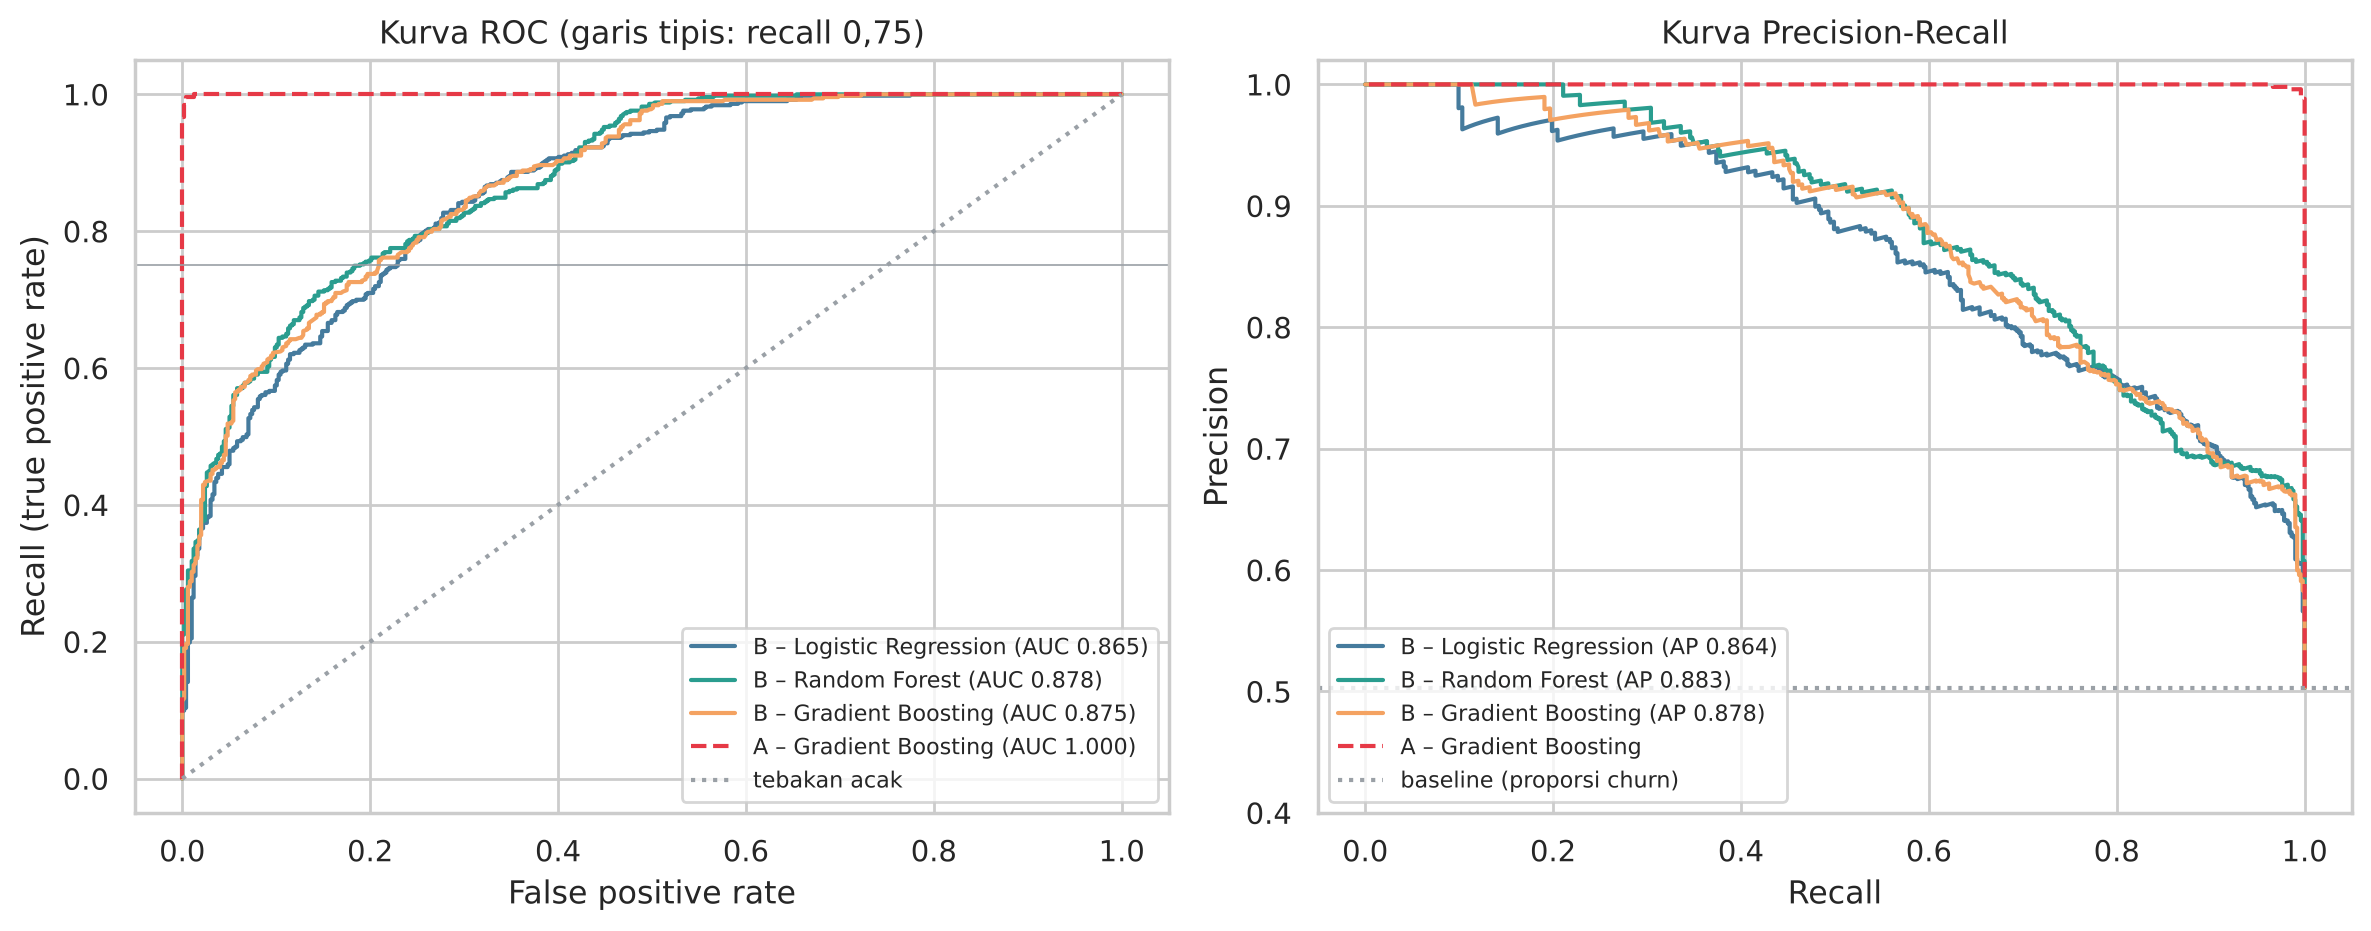


**Cara membaca.** Semakin kurva ROC mendekati sudut kiri atas (dan kurva PR mendekati kanan atas), semakin baik modelnya. Kurva skenario A (garis putus-putus merah) menempel pada sudut kiri atas, hampir sempurna. Ketiga model skenario B berimpit satu sama lain (AUC 0,865–0,878), jadi **tidak ada model yang jelas unggul di skenario B**. Hal ini konsisten dengan validasi silang bahwa selisih antar model kecil.


In [26]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.8))
warna = {"Logistic Regression": BLUE, "Random Forest": TEAL, "Gradient Boosting": ORANGE}
for nama, c in warna.items():
    fpr, tpr, _ = roc_curve(yte, pred[("B", nama)]); ax[0].plot(fpr, tpr, color=c, label=f"B – {nama} (AUC {roc_auc_score(yte, pred[('B', nama)]):.3f})")
    pr, rc, _ = precision_recall_curve(yte, pred[("B", nama)]); ax[1].plot(rc, pr, color=c, label=f"B – {nama} (AP {average_precision_score(yte, pred[('B', nama)]):.3f})")
fpr, tpr, _ = roc_curve(yte, pred[("A", terpilih["A"])]); ax[0].plot(fpr, tpr, color=RED, ls="--", label=f"A – {terpilih['A']} (AUC {roc_auc_score(yte, pred[('A', terpilih['A'])]):.3f})")
pr, rc, _ = precision_recall_curve(yte, pred[("A", terpilih["A"])]); ax[1].plot(rc, pr, color=RED, ls="--", label=f"A – {terpilih['A']}")
ax[0].plot([0, 1], [0, 1], color=GREY, ls=":", label="tebakan acak"); ax[0].axhline(0.75, color=GREY, lw=.6); ax[0].set_xlabel("False positive rate"); ax[0].set_ylabel("Recall (true positive rate)"); ax[0].set_title("Kurva ROC (garis tipis: recall 0,75)"); ax[0].legend(fontsize=8, loc="lower right")
ax[1].axhline(yte.mean(), color=GREY, ls=":", label="baseline (proporsi churn)"); ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision"); ax[1].set_title("Kurva Precision-Recall"); ax[1].legend(fontsize=8, loc="lower left"); ax[1].set_ylim(0.4, 1.02)
savefig("fig15_kurva_roc_pr.png")
aucs = {n: roc_auc_score(yte, pred[("B", n)]) for n in warna}
tampil(f"""
**Cara membaca.** Semakin kurva ROC mendekati sudut kiri atas (dan kurva PR mendekati kanan atas), semakin baik modelnya. Kurva skenario A (garis putus-putus merah) menempel pada sudut kiri atas, hampir sempurna. Ketiga model skenario B berimpit satu sama lain (AUC {idn(min(aucs.values()),3)}–{idn(max(aucs.values()),3)}), jadi **tidak ada model yang jelas unggul di skenario B**. Hal ini konsisten dengan validasi silang bahwa selisih antar model kecil.
""")

## 6.4 Ambang keputusan: kompromi recall dan precision (skenario B)

Pada ambang baku 0,5, recall model B bisa berada di bawah target bisnis 0,75. Ambang adalah parameter keputusan, bukan sesuatu yang harus tetap 0,5, tetapi **memilih ambang dari data uji berarti mengintip jawabannya**. Karena itu ambang dipilih dari **prediksi out-of-fold pada data latih**: diambil ambang **tertinggi** (precision paling terjaga) yang masih memberi recall ≥ 0,80, yaitu target 0,75 ditambah margin 0,05 untuk ketidakpastian. Baru setelah itu ambang tersebut dievaluasi pada data uji.

,ambang,Recall,Precision,F1,ditandai churn,keterangan
0,0.300000,0.962,0.667,0.788,726,
1,0.350000,0.940,0.672,0.784,704,
2,0.400000,0.897,0.705,0.789,640,
8,0.425000,0.845,0.738,0.788,576,terpilih dari data latih
3,0.450000,0.811,0.749,0.779,545,
4,0.500000,0.742,0.784,0.762,476,
5,0.550000,0.716,0.805,0.758,447,
6,0.600000,0.668,0.832,0.741,404,
7,0.700000,0.569,0.902,0.698,317,


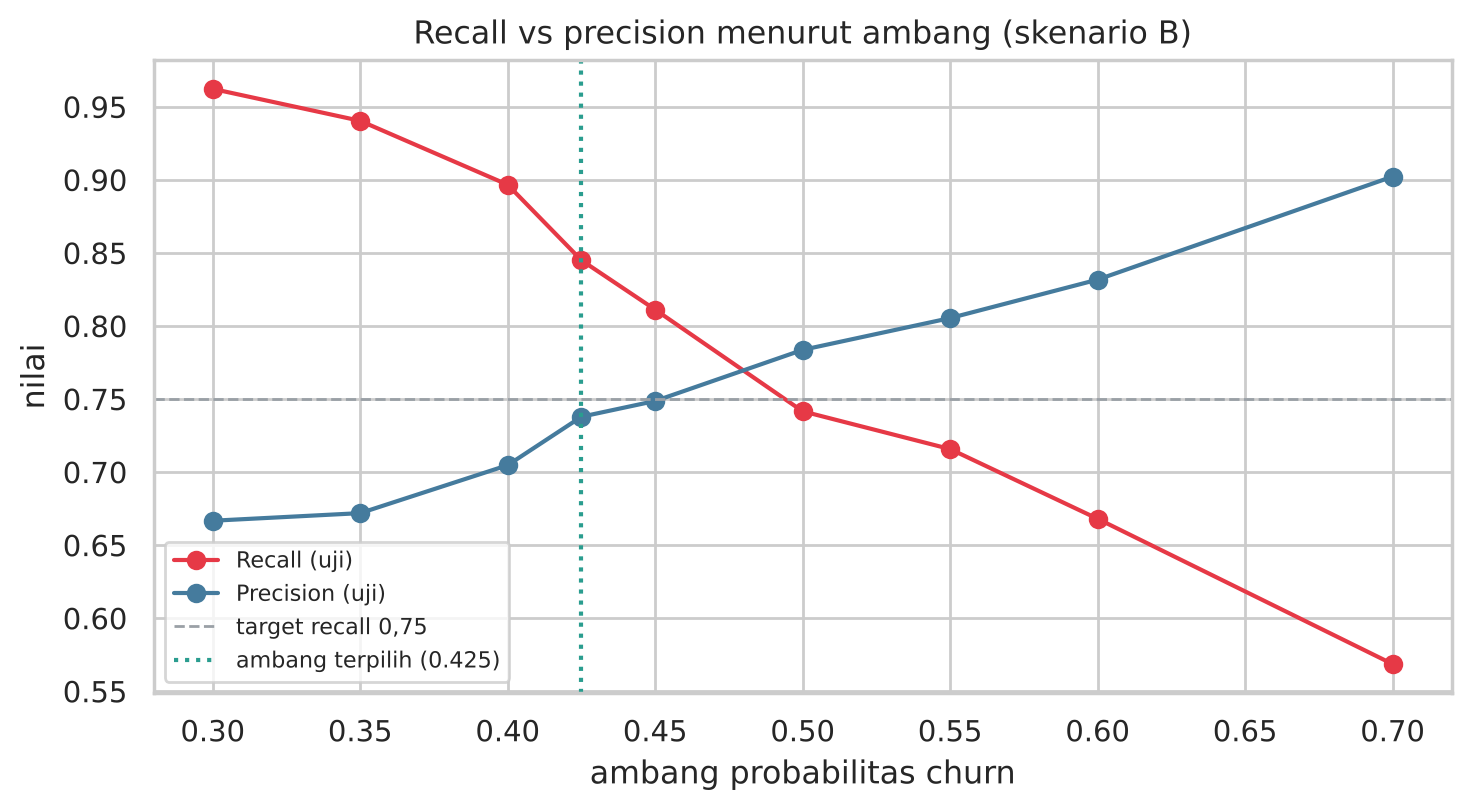


**Hasil.** Ambang yang dipilih dari data latih adalah **0,425**. Pada data uji, ambang 0,5 memberi recall **0,742** dan precision 0,784, sedangkan ambang 0,425 memberi **recall 0,845**, precision 0,738, F1 0,788, akurasi 0,771 (ROC-AUC tetap 0,875 karena tidak bergantung ambang). Model menandai 576 dari 1.000 pelanggan sebagai berisiko: 425 benar churn, 151 salah tandai, 78 churn terlewat.

Menurunkan ambang membuat lebih banyak pelanggan ditandai: recall naik, precision turun, dan sebaliknya. **Ambang akhir sebenarnya keputusan bisnis** (biaya satu kontak retensi vs nilai satu pelanggan yang diselamatkan). Tabel di atas menunjukkan harganya, sehingga tim retensi dapat memilih sendiri titik kompromi yang sesuai anggaran mereka.


In [27]:
fB = FEATS["B"]["num"] + FEATS["B"]["cat"] + FEATS["B"]["bin"]
oofB = cross_val_predict(clone(MB), tr2[fB], ytr, cv=cv, method="predict_proba")[:, 1]
grid_thr = np.round(np.arange(0.20, 0.801, 0.025), 3)
oof_tab = pd.DataFrame({"ambang": grid_thr,
                        "Recall (OOF latih)": [recall_score(ytr, (oofB >= t).astype(int)) for t in grid_thr],
                        "Precision (OOF latih)": [precision_score(ytr, (oofB >= t).astype(int)) for t in grid_thr]})
ok_thr = oof_tab[oof_tab["Recall (OOF latih)"] >= 0.80]
THR = float(ok_thr.ambang.max()) if len(ok_thr) else 0.5
oof_tab.to_csv("outputs/pemilihan_ambang_oof_latih.csv", index=False)

pB = pred[("B", terpilih["B"])]; rows = []
for thr in [0.3, 0.35, 0.4, 0.45, 0.5, 0.55, 0.6, 0.7, THR]:
    yh = (pB >= thr).astype(int)
    rows.append({"ambang": thr, "Recall": recall_score(yte, yh), "Precision": precision_score(yte, yh), "F1": f1_score(yte, yh), "ditandai churn": int(yh.sum()),
                 "keterangan": "terpilih dari data latih" if thr == THR else ""})
thr_df = pd.DataFrame(rows).drop_duplicates("ambang", keep="last").sort_values("ambang"); thr_df.to_csv("outputs/analisis_ambang_B_uji.csv", index=False)
display(thr_df.style.format({"Recall": "{:.3f}", "Precision": "{:.3f}", "F1": "{:.3f}"}))
fig, a = plt.subplots(figsize=(7.5, 4.2))
a.plot(thr_df["ambang"], thr_df["Recall"], marker="o", color=RED, label="Recall (uji)"); a.plot(thr_df["ambang"], thr_df["Precision"], marker="o", color=BLUE, label="Precision (uji)")
a.axhline(0.75, color=GREY, ls="--", lw=1, label="target recall 0,75"); a.axvline(THR, color=TEAL, ls=":", lw=1.5, label=f"ambang terpilih ({THR})")
a.set_xlabel("ambang probabilitas churn"); a.set_ylabel("nilai"); a.legend(fontsize=8); a.set_title("Recall vs precision menurut ambang (skenario B)")
savefig("fig16_analisis_ambang.png")

yhF = (pB >= THR).astype(int)
uF = {"ROC-AUC": roc_auc_score(yte, pB), "Recall (churn)": recall_score(yte, yhF), "Precision": precision_score(yte, yhF), "F1": f1_score(yte, yhF), "Akurasi": accuracy_score(yte, yhF)}
cmF = confusion_matrix(yte, yhF); tnF, fpF, fnF, tpF = cmF.ravel()
u05 = HASIL["uji"]["B"]
HASIL["thr"] = THR; HASIL["uji"]["B_final"] = {k: float(v) for k, v in uF.items()}; HASIL["cm_final"] = cmF.tolist()
tampil(f"""
**Hasil.** Ambang yang dipilih dari data latih adalah **{idn(THR,3)}**. Pada data uji, ambang 0,5 memberi recall **{idn(u05['Recall (churn)'],3)}** dan precision {idn(u05['Precision'],3)}, sedangkan ambang {idn(THR,3)} memberi **recall {idn(uF['Recall (churn)'],3)}**, precision {idn(uF['Precision'],3)}, F1 {idn(uF['F1'],3)}, akurasi {idn(uF['Akurasi'],3)} (ROC-AUC tetap {idn(uF['ROC-AUC'],3)} karena tidak bergantung ambang). Model menandai {int(yhF.sum())} dari 1.000 pelanggan sebagai berisiko: {tpF} benar churn, {fpF} salah tandai, {fnF} churn terlewat.

Menurunkan ambang membuat lebih banyak pelanggan ditandai: recall naik, precision turun, dan sebaliknya. **Ambang akhir sebenarnya keputusan bisnis** (biaya satu kontak retensi vs nilai satu pelanggan yang diselamatkan). Tabel di atas menunjukkan harganya, sehingga tim retensi dapat memilih sendiri titik kompromi yang sesuai anggaran mereka.
""")

## 6.5 Ketidakpastian estimasi (interval kepercayaan bootstrap)

In [28]:
rng = np.random.RandomState(SEED); n = len(yte); y_arr = yte.values
def boot(p, thr=.5, B=1000):
    a, r, pr = [], [], []
    for _ in range(B):
        i = rng.randint(0, n, n)
        if len(np.unique(y_arr[i])) < 2: continue
        a.append(roc_auc_score(y_arr[i], p[i])); yh_ = (p[i] >= thr).astype(int); r.append(recall_score(y_arr[i], yh_)); pr.append(precision_score(y_arr[i], yh_, zero_division=0))
    return np.percentile(a, [2.5, 97.5]), np.percentile(r, [2.5, 97.5]), np.percentile(pr, [2.5, 97.5])
aA, rA, _ = boot(pred[("A", terpilih["A"])])
aB, rB05, _ = boot(pB, 0.5)
_, rBF, pBF = boot(pB, THR)
HASIL["ci"] = {"A": {"auc": aA.tolist(), "recall": rA.tolist()}, "B": {"auc": aB.tolist(), "recall_0.5": rB05.tolist(), "recall_thr": rBF.tolist(), "precision_thr": pBF.tolist()}}
tampil(f"""
Interval kepercayaan 95 % (bootstrap 1.000 kali pada data uji):
- **Skenario B**, ROC-AUC **{idn(aB[0],3)}–{idn(aB[1],3)}**. Recall pada ambang 0,5: {idn(rB05[0],3)}–{idn(rB05[1],3)}; pada ambang {idn(THR,3)}: **{idn(rBF[0],3)}–{idn(rBF[1],3)}**, precision {idn(pBF[0],3)}–{idn(pBF[1],3)}.
- **Skenario A**, ROC-AUC {idn(aA[0],4)}–{idn(aA[1],4)}, recall {idn(rA[0],3)}–{idn(rA[1],3)}.

Dengan hanya 1.000 baris uji, estimasi recall skenario B memiliki ketidakpastian sekitar ±{idn(50*(rBF[1]-rBF[0]),0)} poin. Pada ambang 0,5, interval recall ({idn(rB05[0],3)}–{idn(rB05[1],3)}) **mencakup target 0,75**, jadi tidak bisa dikatakan pasti gagal maupun pasti lulus. Karena itu klaim "memenuhi target" harus disampaikan dengan hati-hati, dan margin ambang pada 6.4 memang dimaksudkan untuk mengantisipasi hal ini.
""")


Interval kepercayaan 95 % (bootstrap 1.000 kali pada data uji):
- **Skenario B**, ROC-AUC **0,855–0,895**. Recall pada ambang 0,5: 0,705–0,779; pada ambang 0,425: **0,813–0,877**, precision 0,703–0,772.
- **Skenario A**, ROC-AUC 0,9996–1,0000, recall 0,990–1,000.

Dengan hanya 1.000 baris uji, estimasi recall skenario B memiliki ketidakpastian sekitar ±3 poin. Pada ambang 0,5, interval recall (0,705–0,779) **mencakup target 0,75**, jadi tidak bisa dikatakan pasti gagal maupun pasti lulus. Karena itu klaim "memenuhi target" harus disampaikan dengan hati-hati, dan margin ambang pada 6.4 memang dimaksudkan untuk mengantisipasi hal ini.


## 6.6 Apa yang dipelajari model: pentingnya fitur (skenario B)

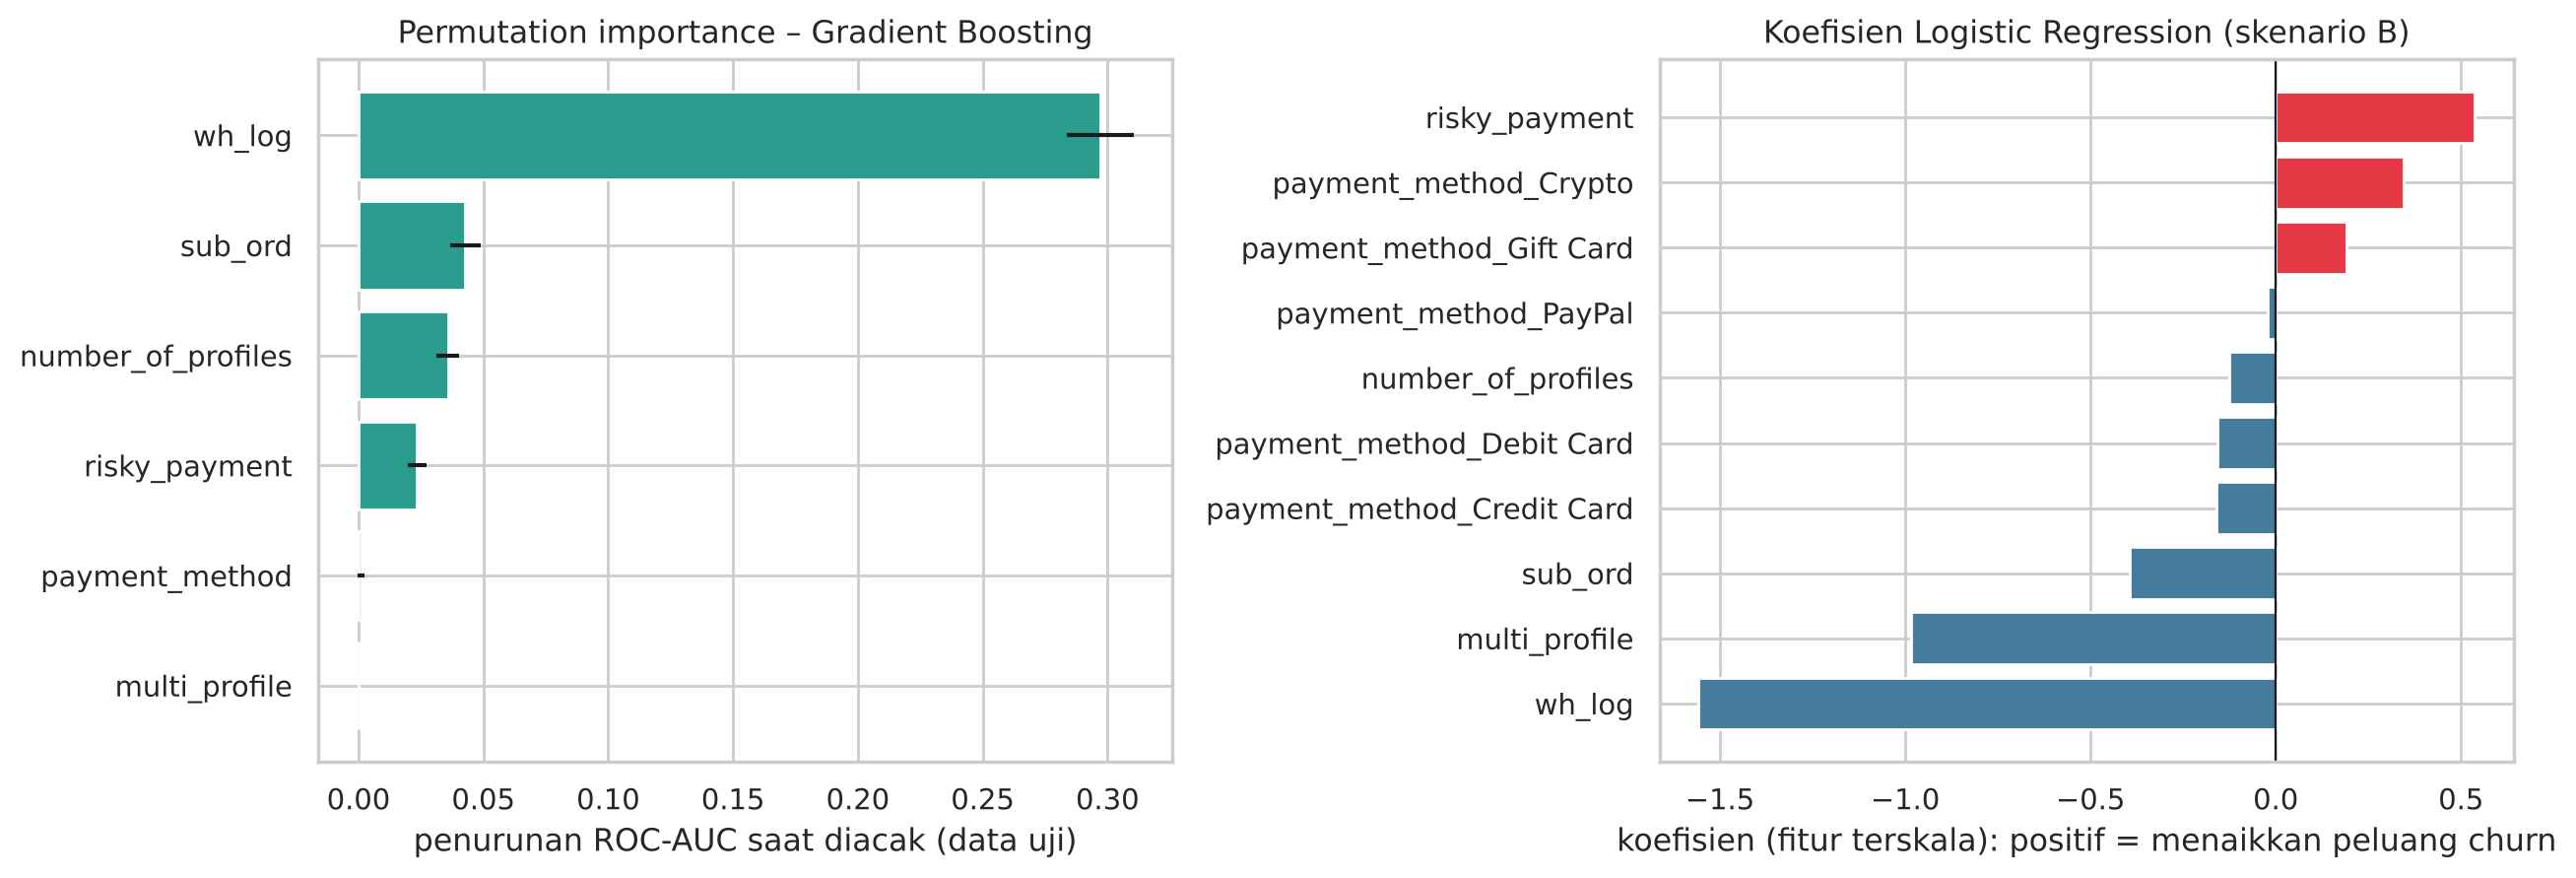

,wh_log,multi_profile,sub_ord,payment_method_Credit Card,payment_method_Debit Card,number_of_profiles,payment_method_PayPal,payment_method_Gift Card,payment_method_Crypto,risky_payment
koefisien,-1.558,-0.985,-0.394,-0.161,-0.159,-0.127,-0.021,0.192,0.345,0.537



**Temuan.** Pada skenario B, `wh_log` (jumlah jam tonton, di-log) adalah fitur yang paling menentukan: mengacaknya menurunkan ROC-AUC sebesar **0,297**, jauh di atas `sub_ord` (0,043) dan `number_of_profiles` (0,036). Fitur lain berkontribusi kecil; fitur biner turunan (`multi_profile`, `risky_payment`) dan `payment_method` nilainya terpecah karena membawa informasi yang tumpang tindih dengan kolom aslinya. Koefisien Logistic Regression konsisten dengan EDA: jam tonton tinggi, paket lebih tinggi, dan akun multi-profil **menurunkan** peluang churn, sedangkan pembayaran berisiko (Crypto/Gift Card) **menaikkan**-nya. Tanda koefisien yang cocok dengan temuan EDA menambah keyakinan bahwa model belajar pola yang sama dengan yang terlihat di data, bukan artefak.


In [29]:
from sklearn.inspection import permutation_importance
Xte_feat = te2[FEATS["B"]["num"] + FEATS["B"]["cat"] + FEATS["B"]["bin"]]
pim = permutation_importance(MB, Xte_feat, yte, scoring="roc_auc", n_repeats=20, random_state=SEED)
imp_df = pd.Series(pim.importances_mean, index=Xte_feat.columns).sort_values(); err = pd.Series(pim.importances_std, index=Xte_feat.columns)[imp_df.index]
lr_B = tuned[("B", "Logistic Regression")]; nm = [n.split("__")[1] for n in lr_B.named_steps["p"].get_feature_names_out()]
coef = pd.Series(lr_B.named_steps["m"].coef_[0], index=nm).sort_values()
fig, ax = plt.subplots(1, 2, figsize=(13, 4.6))
ax[0].barh(imp_df.index, imp_df.values, xerr=err.values, color=TEAL); ax[0].set_xlabel("penurunan ROC-AUC saat diacak (data uji)"); ax[0].set_title(f"Permutation importance – {terpilih['B']}")
ax[1].barh(coef.index, coef.values, color=[RED if v > 0 else BLUE for v in coef.values]); ax[1].axvline(0, color="k", lw=.8)
ax[1].set_xlabel("koefisien (fitur terskala): positif = menaikkan peluang churn"); ax[1].set_title("Koefisien Logistic Regression (skenario B)")
savefig("fig17_pentingnya_fitur.png")
display(coef.round(3).to_frame("koefisien").T)
HASIL["imp_B"] = imp_df.round(4).to_dict()
top = imp_df.sort_values(ascending=False)
tampil(f"""
**Temuan.** Pada skenario B, `{top.index[0]}` (jumlah jam tonton, di-log) adalah fitur yang paling menentukan: mengacaknya menurunkan ROC-AUC sebesar **{idn(top.iloc[0],3)}**, jauh di atas `{top.index[1]}` ({idn(top.iloc[1],3)}) dan `{top.index[2]}` ({idn(top.iloc[2],3)}). Fitur lain berkontribusi kecil; fitur biner turunan (`multi_profile`, `risky_payment`) dan `payment_method` nilainya terpecah karena membawa informasi yang tumpang tindih dengan kolom aslinya. Koefisien Logistic Regression konsisten dengan EDA: jam tonton tinggi, paket lebih tinggi, dan akun multi-profil **menurunkan** peluang churn, sedangkan pembayaran berisiko (Crypto/Gift Card) **menaikkan**-nya. Tanda koefisien yang cocok dengan temuan EDA menambah keyakinan bahwa model belajar pola yang sama dengan yang terlihat di data, bukan artefak.
""")

## 6.7 Analisis kesalahan (skenario B, ambang 0,5)

In [30]:
dfp = te2.copy(); dfp["p"] = pB; dfp["yh"] = (pB >= .5).astype(int)
grp = {"True positive": (dfp.churned == 1) & (dfp.yh == 1), "False negative (churn terlewat)": (dfp.churned == 1) & (dfp.yh == 0),
       "False positive": (dfp.churned == 0) & (dfp.yh == 1), "True negative": (dfp.churned == 0) & (dfp.yh == 0)}
err_tab = pd.DataFrame({k: {"n": int(v.sum()), "median watch_hours": dfp.loc[v, "watch_hours"].median(), "median last_login_days": dfp.loc[v, "last_login_days"].median(),
                            "rerata profil": dfp.loc[v, "number_of_profiles"].mean(), "% paket Basic": 100 * (dfp.loc[v, "subscription_type"] == "Basic").mean()} for k, v in grp.items()}).T.round(2)
err_tab.to_csv("outputs/analisis_kesalahan_B.csv"); display(err_tab)
e = err_tab
tampil(f"""
**Temuan.** *False negative* (churn yang terlewat) adalah pelanggan churn yang **secara jam tonton terlihat seperti pelanggan aktif**: median {idn(e.loc['False negative (churn terlewat)','median watch_hours'],1)} jam, jauh di atas churn yang tertangkap ({idn(e.loc['True positive','median watch_hours'],1)} jam) dan mendekati yang aktif. Sebaliknya *false positive* adalah pelanggan aktif dengan jam tonton rendah ({idn(e.loc['False positive','median watch_hours'],1)} jam vs {idn(e.loc['True negative','median watch_hours'],1)} jam pada aktif yang benar). Model tanpa informasi recency tidak punya cara membedakan keduanya. Menariknya, churn yang terlewat justru punya jeda login terpanjang (median {idn(e.loc['False negative (churn terlewat)','median last_login_days'],0)} hari vs {idn(e.loc['True negative','median last_login_days'],0)} hari pada aktif yang benar), yaitu persis informasi yang dibuang pada skenario B. Inilah alasan `last_login_days` begitu berharga secara prediktif (skenario A), tetapi juga begitu perlu diwaspadai.
""")

,n,median watch_hours,median last_login_days,rerata profil,% paket Basic
True positive,373.0,2.95,37.0,2.71,50.40
False negative (churn terlewat),130.0,8.84,46.0,3.18,25.38
False positive,103.0,8.02,10.0,2.30,47.57
True negative,394.0,18.64,23.0,3.42,16.24



**Temuan.** *False negative* (churn yang terlewat) adalah pelanggan churn yang **secara jam tonton terlihat seperti pelanggan aktif**: median 8,8 jam, jauh di atas churn yang tertangkap (3,0 jam) dan mendekati yang aktif. Sebaliknya *false positive* adalah pelanggan aktif dengan jam tonton rendah (8,0 jam vs 18,6 jam pada aktif yang benar). Model tanpa informasi recency tidak punya cara membedakan keduanya. Menariknya, churn yang terlewat justru punya jeda login terpanjang (median 46 hari vs 23 hari pada aktif yang benar), yaitu persis informasi yang dibuang pada skenario B. Inilah alasan `last_login_days` begitu berharga secara prediktif (skenario A), tetapi juga begitu perlu diwaspadai.


## 6.8 Pemilihan model terbaik dan arti skor skenario A

In [31]:
uA, uF, u05 = HASIL["uji"]["A"], HASIL["uji"]["B_final"], HASIL["uji"]["B"]
lulus = "memenuhi" if uF["Recall (churn)"] >= 0.75 else "belum memenuhi"
tampil(f"""
**Model terbaik yang dipilih: skenario B, {terpilih['B']}, dengan ambang {idn(THR,3)}.** Alasannya, berurutan:

1. **Memenuhi kriteria bisnis tanpa asumsi berbahaya.** ROC-AUC uji {idn(uF['ROC-AUC'],3)} (target ≥ 0,80). Pada ambang baku 0,5, recall churn {idn(u05['Recall (churn)'],3)}, sedikit di bawah target 0,75 (interval kepercayaannya mencakup 0,75). Dengan ambang {idn(THR,3)} yang dipilih dari prediksi out-of-fold data latih (bukan dari data uji), recall menjadi **{idn(uF['Recall (churn)'],3)}** ({lulus} target), precision {idn(uF['Precision'],3)}, F1 {idn(uF['F1'],3)}, akurasi {idn(uF['Akurasi'],3)} (baseline 0,503). Model ini tidak memakai `last_login_days`, sehingga klaimnya tidak bergantung pada kapan nilai itu diukur.
2. **Dipilih lewat aturan yang ditetapkan sebelum melihat data uji** (satu standard error pada CV, lalu recall, lalu kesederhanaan). Pada skenario B ketiga model nyaris berimpit; perbedaannya berada di dalam ketidakpastian estimasi (6.5), sehingga model yang dipilih tidak boleh dipandang jauh lebih baik daripada Random Forest. Bila tim ingin model yang lebih sederhana dan mudah dijelaskan, Logistic Regression (ROC-AUC uji {idn(roc_auc_score(yte, pred[('B', 'Logistic Regression')]),3)}) adalah alternatif yang wajar dengan harga sekitar {idn(100*(uF['ROC-AUC']-roc_auc_score(yte, pred[('B', 'Logistic Regression')])),0)} poin ROC-AUC.
3. **Dapat dijelaskan.** Pentingnya fitur dan tanda koefisien model linear pembanding konsisten dengan EDA (6.6).

**Mengapa skenario A tidak dijadikan model utama meski skornya jauh lebih tinggi.** Model A ({terpilih['A']}) mencapai ROC-AUC {idn(uA['ROC-AUC'],4)}, recall {idn(uA['Recall (churn)'],3)}, dan akurasi {idn(uA['Akurasi'],3)}. Skor setinggi itu pada data perilaku manusia tidak masuk akal, dan ada tiga alasan untuk tidak memercayainya:
- `last_login_days` mungkin sebagian **akibat** churn (pelanggan yang sudah pergi tidak login), jadi model "melihat jawabannya" (*temporal leakage*).
- Ablasi (4.5.3) menunjukkan lonjakan performa hampir seluruhnya berasal dari fitur ini; tanpanya ROC-AUC turun ke sekitar 0,87.
- Label churn pada dataset yang diindikasikan **sintetis** kemungkinan dibangkitkan dari aturan atas jam tonton dan recency, sehingga pohon keputusan sederhana dengan dua fitur itu saja sudah mencapai akurasi sekitar 90 % (diperiksa di bawah).

Skenario A tetap dilaporkan sebagai **batas atas** apa yang mungkin dicapai bila `last_login_days` ternyata sah dipakai (diukur sebelum titik pengamatan).
""")
from sklearn.tree import DecisionTreeClassifier
dt_X = tr2[["watch_hours", "last_login_days"]]
for depth in [2, 3, 4]:
    sc_ = cross_validate(DecisionTreeClassifier(max_depth=depth, random_state=SEED), dt_X, ytr, cv=cv, scoring="accuracy")["test_score"].mean()
    print(f"Pohon keputusan kedalaman {depth}, hanya watch_hours + last_login_days: akurasi CV = {sc_:.3f}")
    if depth == 3: HASIL["pohon_d3_acc"] = float(sc_)


**Model terbaik yang dipilih: skenario B, Gradient Boosting, dengan ambang 0,425.** Alasannya, berurutan:

1. **Memenuhi kriteria bisnis tanpa asumsi berbahaya.** ROC-AUC uji 0,875 (target ≥ 0,80). Pada ambang baku 0,5, recall churn 0,742, sedikit di bawah target 0,75 (interval kepercayaannya mencakup 0,75). Dengan ambang 0,425 yang dipilih dari prediksi out-of-fold data latih (bukan dari data uji), recall menjadi **0,845** (memenuhi target), precision 0,738, F1 0,788, akurasi 0,771 (baseline 0,503). Model ini tidak memakai `last_login_days`, sehingga klaimnya tidak bergantung pada kapan nilai itu diukur.
2. **Dipilih lewat aturan yang ditetapkan sebelum melihat data uji** (satu standard error pada CV, lalu recall, lalu kesederhanaan). Pada skenario B ketiga model nyaris berimpit; perbedaannya berada di dalam ketidakpastian estimasi (6.5), sehingga model yang dipilih tidak boleh dipandang jauh lebih baik daripada Random Forest. Bila tim ingin model yang lebih sederhana dan mudah dijelaskan, Logistic Regression (ROC-AUC uji 0,865) adalah alternatif yang wajar dengan harga sekitar 1 poin ROC-AUC.
3. **Dapat dijelaskan.** Pentingnya fitur dan tanda koefisien model linear pembanding konsisten dengan EDA (6.6).

**Mengapa skenario A tidak dijadikan model utama meski skornya jauh lebih tinggi.** Model A (Gradient Boosting) mencapai ROC-AUC 0,9999, recall 0,996, dan akurasi 0,996. Skor setinggi itu pada data perilaku manusia tidak masuk akal, dan ada tiga alasan untuk tidak memercayainya:
- `last_login_days` mungkin sebagian **akibat** churn (pelanggan yang sudah pergi tidak login), jadi model "melihat jawabannya" (*temporal leakage*).
- Ablasi (4.5.3) menunjukkan lonjakan performa hampir seluruhnya berasal dari fitur ini; tanpanya ROC-AUC turun ke sekitar 0,87.
- Label churn pada dataset yang diindikasikan **sintetis** kemungkinan dibangkitkan dari aturan atas jam tonton dan recency, sehingga pohon keputusan sederhana dengan dua fitur itu saja sudah mencapai akurasi sekitar 90 % (diperiksa di bawah).

Skenario A tetap dilaporkan sebagai **batas atas** apa yang mungkin dicapai bila `last_login_days` ternyata sah dipakai (diukur sebelum titik pengamatan).


Pohon keputusan kedalaman 2, hanya watch_hours + last_login_days: akurasi CV = 0.847
Pohon keputusan kedalaman 3, hanya watch_hours + last_login_days: akurasi CV = 0.898
Pohon keputusan kedalaman 4, hanya watch_hours + last_login_days: akurasi CV = 0.901


## 6.9 Ringkasan evaluasi terhadap kriteria berhasil

In [32]:
uF, u05 = HASIL["uji"]["B_final"], HASIL["uji"]["B"]
def status(nilai, target, lo, hi):
    if lo >= target: return "✔ tercapai"
    if hi < target: return "✘ belum tercapai"
    return "≈ belum pasti (interval kepercayaan mencakup target)"
rows = [
 ["ROC-AUC ≥ 0,80", f"{idn(uF['ROC-AUC'],3)} (CI 95 %: {idn(aB[0],3)}–{idn(aB[1],3)})", status(uF['ROC-AUC'], .80, aB[0], aB[1])],
 ["Recall churn ≥ 0,75 pada ambang baku 0,5", f"{idn(u05['Recall (churn)'],3)} (CI 95 %: {idn(rB05[0],3)}–{idn(rB05[1],3)})", status(u05['Recall (churn)'], .75, rB05[0], rB05[1])],
 [f"Recall churn ≥ 0,75 pada ambang terpilih {idn(THR,3)}", f"{idn(uF['Recall (churn)'],3)} (CI 95 %: {idn(rBF[0],3)}–{idn(rBF[1],3)})", status(uF['Recall (churn)'], .75, rBF[0], rBF[1])],
 ["Akurasi di atas baseline 0,503", f"{idn(uF['Akurasi'],3)} (baseline 0,503)", "✔ tercapai" if uF['Akurasi'] > 0.503 else "✘ belum tercapai"],
 ["Precision dan F1 dilaporkan", f"precision {idn(uF['Precision'],3)}, F1 {idn(uF['F1'],3)}", "✔ dilaporkan"],
 ["Segmen berisiko dan revenue-at-risk dapat dihitung", "dihitung pada 7.1 (P4)", "✔ tercapai"],
 ["Reprodusibilitas", "seed tetap, `requirements.txt`, README; eksekusi ulang dari awal menghasilkan angka identik", "✔ tercapai"],
]
t_krit = pd.DataFrame(rows, columns=["Kriteria (dari 1.4)", "Hasil pada data uji", "Status"]); t_krit.to_csv("outputs/ringkasan_kriteria_berhasil.csv", index=False)
display(t_krit.style.hide(axis="index"))

Kriteria (dari 1.4),Hasil pada data uji,Status
"ROC-AUC ≥ 0,80","0,875 (CI 95 %: 0,855–0,895)",✔ tercapai
"Recall churn ≥ 0,75 pada ambang baku 0,5","0,742 (CI 95 %: 0,705–0,779)",≈ belum pasti (interval kepercayaan mencakup target)
"Recall churn ≥ 0,75 pada ambang terpilih 0,425","0,845 (CI 95 %: 0,813–0,877)",✔ tercapai
"Akurasi di atas baseline 0,503","0,771 (baseline 0,503)",✔ tercapai
Precision dan F1 dilaporkan,"precision 0,738, F1 0,788",✔ dilaporkan
Segmen berisiko dan revenue-at-risk dapat dihitung,dihitung pada 7.1 (P4),✔ tercapai
Reprodusibilitas,"seed tetap, `requirements.txt`, README; eksekusi ulang dari awal menghasilkan angka identik",✔ tercapai


**Kesimpulan evaluasi.** Semua kriteria terpenuhi **dengan satu catatan jujur**: recall hanya memenuhi target setelah ambang diturunkan dari 0,5. Pada ambang 0,5 hasilnya berada di sekitar target dan interval kepercayaannya mencakup 0,75, jadi tidak bisa dikatakan lulus atau gagal secara meyakinkan. Karena itu klaim "model memenuhi target recall" selalu disebut bersama ambang yang dipakai.

---
# 7. Konklusi
## 7.1 Jawaban atas pertanyaan Business Understanding

In [33]:
full = add_new(clean.assign(subscription_type=clean.subscription_type.astype(str)))
fcols = FEATS["B"]["num"] + FEATS["B"]["cat"] + FEATS["B"]["bin"]
oof = cross_val_predict(clone(MB), full[fcols], y_all, cv=cv, method="predict_proba")[:, 1]   # peluang out-of-fold: tiap baris diprediksi oleh model yang tidak melihatnya
aktif = full.churned == 0
berisiko = aktif & (oof >= THR)
rar = full.loc[berisiko, "monthly_fee"].sum(); rar_total_aktif = full.loc[aktif, "monthly_fee"].sum()
per_paket = full[berisiko].groupby("subscription_type").agg(pelanggan=("monthly_fee", "size"), revenue_bulanan_USD=("monthly_fee", "sum")).reindex(ORDER_SUB).round(2)
per_paket.to_csv("outputs/revenue_at_risk_per_paket.csv")
# pembanding: aturan sederhana dari EDA (tidak login > 30 hari)
rule = aktif & (full.last_login_days > 30)
rule_rev = full.loc[rule, "monthly_fee"].sum()
overlap = int((rule & berisiko).sum())
rule_recall = ((full.last_login_days > 30) & (full.churned == 1)).sum() / (full.churned == 1).sum()
HASIL["bisnis"] = {"aktif": int(aktif.sum()), "berisiko_model": int(berisiko.sum()), "rev_model": float(rar), "rev_aktif": float(rar_total_aktif),
                   "berisiko_rule": int(rule.sum()), "rev_rule": float(rule_rev), "overlap": overlap, "rule_recall": float(rule_recall),
                   "churn_fee": float(churn_fee), "total_fee": float(total_fee), "rule_watch_median": float(full.loc[rule, "watch_hours"].median())}
display(per_paket)

,pelanggan,revenue_bulanan_USD
subscription_type,,
Basic,290,2607.10
Standard,237,3315.63
Premium,220,3957.80


In [34]:
b = HASIL["bisnis"]; uB = HASIL["uji"]["B_final"]; u05 = HASIL["uji"]["B"]; tn, fp, fn, tp = tnF, fpF, fnF, tpF
top3 = list(imp_df.sort_values(ascending=False).index[:3])
tampil(f"""
**P1. Pola apa yang berasosiasi dengan churn?** Churn berasosiasi dengan **perilaku**, bukan dengan identitas pelanggan. Pelanggan yang sedikit menonton (kuintil terbawah churn 85,7 % vs 8,1 % di kuintil teratas), yang lama tidak login (churn melonjak dari sekitar 32 % menjadi sekitar 75 % setelah 30 hari), berlangganan paket **Basic** (61,8 % vs 43,7–45,4 %), membayar dengan **Crypto atau Gift Card** (57,8–59,7 % vs sekitar 44 % untuk kartu), dan memiliki **1–3 profil** (57–59 % vs 37,5–40,6 % pada 4–5 profil) lebih sering churn.

**P2. Variabel terkuat dan yang tidak berasosiasi.** Terkuat: jam tonton dan recency login (korelasi Spearman −0,54 dan +0,47; AUC univariat 0,81 dan 0,78), lalu jumlah profil, paket, dan metode pembayaran (Cramér's V 0,14–0,19, asosiasi lemah sampai sedang). **Tidak berasosiasi (p > 0,05):** `age`, `gender`, `region`, `device`, `favorite_genre`. Variabel ini tidak layak dijadikan dasar segmentasi dan tidak dipakai model. Pada model skenario B, tiga fitur terpenting adalah **{top3[0]}, {top3[1]}, dan {top3[2]}**.

**P3. Seberapa baik churn dapat diprediksi?** Cukup baik, dengan syarat. Model terpilih (skenario B, {terpilih['B']}, tanpa `last_login_days`, ambang {idn(THR,3)}) mencapai **ROC-AUC {idn(uB['ROC-AUC'],3)}, recall {idn(uB['Recall (churn)'],3)}, precision {idn(uB['Precision'],3)}, akurasi {idn(uB['Akurasi'],3)}** pada data uji. ROC-AUC memenuhi target ≥ 0,80 dan jauh di atas baseline (akurasi 0,503). Recall memenuhi target 0,75 hanya setelah ambang diturunkan dari 0,5 ke {idn(THR,3)}; pada ambang 0,5 recall {idn(u05['Recall (churn)'],3)}, sedikit di bawah target. Selisih ini masih dalam ketidakpastian estimasi (bagian 6.5). Bila `last_login_days` dipakai (skenario A) skornya mendekati sempurna (ROC-AUC {idn(HASIL['uji']['A']['ROC-AUC'],4)}), tetapi skor itu **tidak dipercaya** karena risiko kebocoran dan indikasi data sintetis.

**P4. Pelanggan aktif berisiko dan revenue-at-risk.** Dari {idn(b['aktif'],0,True)} pelanggan aktif, model skenario B menandai **{idn(b['berisiko_model'],0,True)} pelanggan** ({idn(100*b['berisiko_model']/b['aktif'],1)} %) yang polanya menyerupai pelanggan churn, dengan pendapatan bulanan **USD {idn(b['rev_model'],2,True)}** ({idn(100*b['rev_model']/b['rev_aktif'],1)} % dari pendapatan akun aktif). Sebagai pembanding, aturan sederhana "tidak login > 30 hari" menyaring **{idn(b['berisiko_rule'],0,True)} pelanggan aktif** senilai USD {idn(b['rev_rule'],2,True)} per bulan, dan menangkap {idn(100*b['rule_recall'],0)} % pelanggan yang churn. Irisan kedua daftar hanya {idn(b['overlap'],0,True)} pelanggan. Penyebabnya, pelanggan aktif yang lama tidak login ternyata penonton berat (median {idn(b['rule_watch_median'],1)} jam) yang dianggap aman oleh model skenario B, sedangkan pelanggan yang ditandai model adalah penonton ringan yang masih sering login. Keduanya adalah tipe risiko yang berbeda, jadi layak digabung untuk menentukan prioritas kampanye retensi.
""")


**P1. Pola apa yang berasosiasi dengan churn?** Churn berasosiasi dengan **perilaku**, bukan dengan identitas pelanggan. Pelanggan yang sedikit menonton (kuintil terbawah churn 85,7 % vs 8,1 % di kuintil teratas), yang lama tidak login (churn melonjak dari sekitar 32 % menjadi sekitar 75 % setelah 30 hari), berlangganan paket **Basic** (61,8 % vs 43,7–45,4 %), membayar dengan **Crypto atau Gift Card** (57,8–59,7 % vs sekitar 44 % untuk kartu), dan memiliki **1–3 profil** (57–59 % vs 37,5–40,6 % pada 4–5 profil) lebih sering churn.

**P2. Variabel terkuat dan yang tidak berasosiasi.** Terkuat: jam tonton dan recency login (korelasi Spearman −0,54 dan +0,47; AUC univariat 0,81 dan 0,78), lalu jumlah profil, paket, dan metode pembayaran (Cramér's V 0,14–0,19, asosiasi lemah sampai sedang). **Tidak berasosiasi (p > 0,05):** `age`, `gender`, `region`, `device`, `favorite_genre`. Variabel ini tidak layak dijadikan dasar segmentasi dan tidak dipakai model. Pada model skenario B, tiga fitur terpenting adalah **wh_log, sub_ord, dan number_of_profiles**.

**P3. Seberapa baik churn dapat diprediksi?** Cukup baik, dengan syarat. Model terpilih (skenario B, Gradient Boosting, tanpa `last_login_days`, ambang 0,425) mencapai **ROC-AUC 0,875, recall 0,845, precision 0,738, akurasi 0,771** pada data uji. ROC-AUC memenuhi target ≥ 0,80 dan jauh di atas baseline (akurasi 0,503). Recall memenuhi target 0,75 hanya setelah ambang diturunkan dari 0,5 ke 0,425; pada ambang 0,5 recall 0,742, sedikit di bawah target. Selisih ini masih dalam ketidakpastian estimasi (bagian 6.5). Bila `last_login_days` dipakai (skenario A) skornya mendekati sempurna (ROC-AUC 0,9999), tetapi skor itu **tidak dipercaya** karena risiko kebocoran dan indikasi data sintetis.

**P4. Pelanggan aktif berisiko dan revenue-at-risk.** Dari 2.485 pelanggan aktif, model skenario B menandai **747 pelanggan** (30,1 %) yang polanya menyerupai pelanggan churn, dengan pendapatan bulanan **USD 9.880,53** (27,9 % dari pendapatan akun aktif). Sebagai pembanding, aturan sederhana "tidak login > 30 hari" menyaring **615 pelanggan aktif** senilai USD 9.088,85 per bulan, dan menangkap 74 % pelanggan yang churn. Irisan kedua daftar hanya 4 pelanggan. Penyebabnya, pelanggan aktif yang lama tidak login ternyata penonton berat (median 23,8 jam) yang dianggap aman oleh model skenario B, sedangkan pelanggan yang ditandai model adalah penonton ringan yang masih sering login. Keduanya adalah tipe risiko yang berbeda, jadi layak digabung untuk menentukan prioritas kampanye retensi.


## 7.2 Arti metrik dalam bahasa bisnis

In [35]:
tampil(f"""
- **ROC-AUC {idn(uB['ROC-AUC'],2)}** berarti bila diambil satu pelanggan churn dan satu pelanggan aktif secara acak, model memberi skor risiko yang lebih tinggi pada pelanggan churn dalam sekitar **{idn(100*uB['ROC-AUC'],0)} dari 100 pasangan**.
- **Recall {idn(uB['Recall (churn)'],2)}** berarti dari setiap 100 pelanggan yang akan churn, model berhasil menandai sekitar **{idn(100*uB['Recall (churn)'],0)}** dan melewatkan sekitar {idn(100-100*uB['Recall (churn)'],0)}. Pada data uji: {tp} tertangkap dan {fn} terlewat dari {tp+fn} pelanggan churn.
- **Precision {idn(uB['Precision'],2)}** berarti dari setiap 100 pelanggan yang ditandai berisiko, sekitar **{idn(100*uB['Precision'],0)}** benar-benar churn dan sekitar {idn(100-100*uB['Precision'],0)} sebenarnya akan bertahan (kampanye retensi pada mereka terbuang, walau tidak merugikan pelanggan). Pada data uji: {fp} dari {tp+fp} yang ditandai.
- **Akurasi {idn(uB['Akurasi'],2)}** berarti sekitar {idn(100*uB['Akurasi'],0)} dari 100 prediksi tepat, dibanding 50 dari 100 bila menebak. Metrik ini aman dipakai di sini karena kelas seimbang.
- **Interval kepercayaan** (6.5) mengingatkan bahwa angka ini adalah estimasi dari 1.000 pelanggan uji; angka sebenarnya bisa bergeser beberapa poin (recall sekitar ±3–4 poin).
""")


- **ROC-AUC 0,87** berarti bila diambil satu pelanggan churn dan satu pelanggan aktif secara acak, model memberi skor risiko yang lebih tinggi pada pelanggan churn dalam sekitar **87 dari 100 pasangan**.
- **Recall 0,84** berarti dari setiap 100 pelanggan yang akan churn, model berhasil menandai sekitar **84** dan melewatkan sekitar 16. Pada data uji: 425 tertangkap dan 78 terlewat dari 503 pelanggan churn.
- **Precision 0,74** berarti dari setiap 100 pelanggan yang ditandai berisiko, sekitar **74** benar-benar churn dan sekitar 26 sebenarnya akan bertahan (kampanye retensi pada mereka terbuang, walau tidak merugikan pelanggan). Pada data uji: 151 dari 576 yang ditandai.
- **Akurasi 0,77** berarti sekitar 77 dari 100 prediksi tepat, dibanding 50 dari 100 bila menebak. Metrik ini aman dipakai di sini karena kelas seimbang.
- **Interval kepercayaan** (6.5) mengingatkan bahwa angka ini adalah estimasi dari 1.000 pelanggan uji; angka sebenarnya bisa bergeser beberapa poin (recall sekitar ±3–4 poin).


## 7.3 Keputusan yang diambil dan alasannya
| Keputusan | Alasan |
|---|---|
| Outlier `watch_hours` dipertahankan (winsorizing + `log1p`), tidak dihapus | nilainya sah dan informatif (churn 0,8 %); uji empiris menunjukkan semua strategi setara |
| Tidak melakukan resampling / `class_weight` | kelas seimbang (1,01 : 1) dan pengujian tidak menunjukkan manfaat |
| Membuang `avg_watch_time_per_day` | kolom turunan, memuat informasi yang sama dengan dua fitur lain dan berisiko bocor |
| Memilih `subscription_type`, membuang `monthly_fee` | informasinya identik; paket lebih mudah ditafsirkan |
| Membuang `age`, `gender`, `region`, `device`, `favorite_genre` | tidak berasosiasi (p > 0,05), importance nol, dan sebagian bersifat sensitif |
| Membuat `inactive_30d`, `multi_profile`, `risky_payment` | berasal dari pola EDA; menaikkan ROC-AUC dan recall model linear |
| Memisahkan skenario A dan B, memilih **B** sebagai model utama | `last_login_days` berisiko *temporal leakage*; B tetap memenuhi target ROC-AUC dan, dengan ambang yang disetel, target recall |
| Memilih model lewat aturan satu standard error, bukan skor uji tertinggi | menghindari memilih berdasarkan selisih yang hanya noise dan menjaga data uji tetap murni |
| Ambang 0,5 untuk perbandingan antar model; ambang akhir dipilih dari prediksi out-of-fold data latih (recall ≥ 0,80) | pada 0,5 recall sedikit di bawah target; mengatur ambang dari data latih menghindari mengintip data uji, dan pilihan akhir tetap keputusan bisnis |

## 7.4 Keterbatasan
1. **Data diindikasikan sintetis.** Distribusi hampir seragam, kategori hampir sama besar, dan churn rate 50,3 % jauh di atas layanan nyata. Temuan tidak boleh digeneralisasi ke pelanggan Netflix yang sebenarnya, dan performa model mungkin mencerminkan cara data dibangkitkan.
2. **Hanya asosiasi, bukan sebab-akibat.** Misalnya, jam tonton rendah bisa menjadi penyebab churn, tetapi juga bisa menjadi gejala sebelum churn.
3. **Tidak ada dimensi waktu.** Tidak ada tenure, tanggal churn, atau periode pengukuran `watch_hours`, sehingga tidak bisa dipastikan apakah fitur diukur sebelum churn. Akibatnya `last_login_days` tidak dapat dipakai tanpa risiko kebocoran, dan model tidak bisa memprediksi *kapan* pelanggan akan churn.
4. **Fitur terbatas.** Tidak ada data kepuasan, keluhan, harga pesaing, atau katalog konten, sehingga alasan churn tidak dapat dijelaskan.
5. **Satu split uji berukuran 1.000.** Estimasi recall memiliki ketidakpastian sekitar ±3–4 poin (6.5). Batas winsorizing (35,07) dihitung dari seluruh data pada tahap EDA, sedangkan seluruh parameter model (encoder, scaler) dan uji seleksi fitur dihitung dari data latih.
6. **Revenue-at-risk adalah estimasi.** Dihitung dari peluang *out-of-fold* pada pelanggan berstatus aktif dan mengasumsikan semua pelanggan berisiko benar-benar akan churn tanpa intervensi; kenyataannya sebagian akan bertahan.
7. **Isu etika.** Skor churn tidak boleh dipakai untuk menaikkan harga secara selektif atau membatasi layanan kelompok tertentu; atribut sensitif (`age`, `gender`, `region`) sengaja tidak masuk model.

## 7.5 Saran tindak lanjut
- **Bisnis:** jalankan kampanye *re-engagement* untuk pelanggan aktif yang tidak login > 30 hari atau jam tontonnya rendah; dorong penggunaan multi-profil (keluarga/pasangan) karena berasosiasi dengan churn rendah; tinjau pengalaman pembayaran Crypto dan Gift Card; jangan membuat segmentasi berdasarkan usia, gender, wilayah, perangkat, atau genre.
- **Data:** catat tanggal pengukuran tiap fitur dan tanggal churn agar kebocoran temporal bisa dipastikan dan analisis *survival* dimungkinkan; uji model pada data pelanggan nyata sebelum dipakai.
- **Model:** bila `last_login_days` terbukti diukur sebelum titik pengamatan, evaluasi ulang skenario A dengan validasi berbasis waktu (*time-based split*).

## 7.6 Rencana deployment (di atas kertas)
Proyek ini tidak membangun aplikasi, API, atau dashboard (sesuai panduan). Berikut rencana bila hasil analisis ini hendak dipakai oleh tim retensi layanan streaming.

| Aspek | Rencana |
|---|---|
| **Tujuan dan keputusan yang didukung** | memprioritaskan pelanggan aktif yang dihubungi tim retensi (penawaran, pengingat konten, bantuan pembayaran); bukan untuk mengubah harga atau membatasi layanan |
| **Pengguna** | tim retensi/CRM (menerima daftar prioritas), analis data (memantau model), manajer produk (menilai hasil kampanye) |
| **Data masukan** | hanya fitur skenario B: `watch_hours`, `subscription_type`, `number_of_profiles`, `payment_method`. Semua biasanya tersedia di sistem billing dan log penggunaan. **Prasyarat:** periode pengukuran `watch_hours` harus jelas dan konsisten |
| **Frekuensi skoring** | batch, misalnya mingguan atau bulanan untuk seluruh pelanggan aktif; keluaran berupa peluang churn per pelanggan dan daftar teratas |
| **Aturan keputusan** | tandai pelanggan dengan peluang ≥ ambang terpilih, dibatasi kapasitas tim (ambang bisa dinaikkan bila kapasitas kecil). Digabung dengan aturan sederhana "tidak login > 30 hari" yang menangkap tipe risiko berbeda (7.1, P4) |
| **Uji sebelum dipakai penuh** | pilot dengan **kelompok kontrol** (sebagian pelanggan berisiko tidak dihubungi). Model hanya memprediksi *risiko*, bukan seberapa efektif kampanyenya; efek intervensi harus diukur terpisah |
| **Pemantauan** | (a) pergeseran distribusi fitur dan proporsi pelanggan yang ditandai; (b) recall dan precision bulanan setelah status churn bulan itu diketahui; (c) tingkat respons kampanye |
| **Pelatihan ulang** | berkala (misalnya tiap kuartal) atau lebih cepat bila recall bulanan turun di bawah 0,75 atau distribusi fitur bergeser jauh |
| **Cadangan (*fallback*)** | bila model dinonaktifkan, pakai aturan sederhana "tidak login > 30 hari" atau jam tonton rendah |
| **Risiko dan mitigasi** | *Data sintetis/tidak representatif:* wajib dilatih ulang pada data nyata sebelum dipakai. *Kebocoran temporal:* gunakan skenario B, dan skenario A hanya bila waktu pengukuran terbukti sebelum churn. *Etika dan privasi:* tidak memakai usia, gender, wilayah; tidak dipakai untuk menaikkan harga selektif; skor diperlakukan sebagai data pelanggan yang dilindungi. *Salah tandai:* kampanye retensi dibuat ringan supaya biaya salah tandai kecil |
| **Kriteria layak dipakai (go/no-go)** | model dilatih ulang pada data nyata dengan validasi berbasis waktu; recall ≥ 0,75 dan ROC-AUC ≥ 0,80 pada data waktu setelah periode latih; pilot menunjukkan kampanye menekan churn pada kelompok yang dihubungi dibanding kontrol |

In [36]:
bk = HASIL["bisnis"]; uF = HASIL["uji"]["B_final"]
tampil(f"""
**Estimasi beban dan titik impas.** Pada ambang {idn(THR,3)}, model menandai {idn(bk['berisiko_model'],0,True)} dari {idn(bk['aktif'],0,True)} pelanggan aktif ({idn(100*bk['berisiko_model']/bk['aktif'],1)} %) untuk dihubungi dalam satu putaran skoring. Karena precision sekitar {idn(uF['Precision'],2)}, sekitar {idn(100*uF['Precision'],0)} % dari mereka memang akan churn. Kampanye layak dilakukan bila: **biaya satu kontak < (precision × peluang pelanggan berhasil dipertahankan × biaya langganan bulanan × lama bertahan tambahan)**. Peluang berhasil dipertahankan dan biaya kontak belum diketahui dari data ini, sehingga harus diisi oleh tim bisnis dari hasil pilot.
""")


**Estimasi beban dan titik impas.** Pada ambang 0,425, model menandai 747 dari 2.485 pelanggan aktif (30,1 %) untuk dihubungi dalam satu putaran skoring. Karena precision sekitar 0,74, sekitar 74 % dari mereka memang akan churn. Kampanye layak dilakukan bila: **biaya satu kontak < (precision × peluang pelanggan berhasil dipertahankan × biaya langganan bulanan × lama bertahan tambahan)**. Peluang berhasil dipertahankan dan biaya kontak belum diketahui dari data ini, sehingga harus diisi oleh tim bisnis dari hasil pilot.


## 7.7 Review proses
**Yang berjalan baik.**
- *Audit sebelum modelling* menemukan kolom turunan (`avg_watch_time_per_day`) dan nilai mustahil (> 24 jam per hari), sehingga tidak masuk model.
- *Aturan anti-kebocoran* dijaga sejak split: encoder, scaler, dan seleksi fitur hanya dari data latih; data uji dipakai sekali.
- *Dua skenario fitur* mencegah klaim berlebihan dari skor hampir sempurna.
- *Aturan pemilihan model ditetapkan di awal* (satu standard error), sehingga tidak memilih berdasarkan data uji.
- *Verifikasi:* seluruh angka pada narasi dihitung langsung dari kode, dan notebook dieksekusi ulang dari awal untuk memastikan hasil identik.

**Yang kurang atau perlu diperbaiki.**
- Skor hampir sempurna pada skenario A baru dicurigai setelah ablasi; seharusnya pengujian kebocoran sudah masuk rencana sejak Business Understanding.
- Pada ambang 0,5, recall sedikit di bawah target; penanganannya (menyetel ambang dari data latih) baru muncul setelah evaluasi pertama, bukan dirancang di awal.
- EDA dan batas winsorizing (35,07) memakai seluruh data, sehingga ada sedikit informasi data uji pada tahap itu walau tidak memengaruhi parameter model.
- Evaluasi memakai satu split acak, bukan split berdasarkan waktu, karena data tidak punya dimensi waktu.
- Indikasi data sintetis baru terlihat dari EDA, jadi sebagian pekerjaan modelling dilakukan pada data yang sifatnya terbatas.

**Pelajaran.** (1) Periksa isi dan asal setiap fitur sebelum memperumit model. (2) Skor yang terlalu bagus adalah alasan untuk curiga. (3) Rancang uji kebocoran dan penentuan ambang sejak awal. (4) Laporkan ketidakpastian (interval kepercayaan), bukan hanya satu angka.

**Bila diulang, yang akan dilakukan berbeda.** Menuliskan kriteria berhasil beserta cara penentuan ambang di Business Understanding, menyiapkan uji kebocoran sebagai langkah baku sebelum modelling, dan meminta data berdimensi waktu agar bisa memakai validasi berbasis waktu.

## 7.8 Review proyek
| Pertanyaan / tujuan | Tercapai? | Catatan |
|---|---|---|
| **P1.** Pola yang berasosiasi dengan churn | ✔ | perilaku (jam tonton, recency login), paket Basic, Crypto/Gift Card, 1–3 profil |
| **P2.** Variabel terkuat dan yang tidak berasosiasi | ✔ | `age`, `gender`, `region`, `device`, `favorite_genre` tidak berasosiasi |
| **P3.** Seberapa baik churn dapat diprediksi | ✔ dengan syarat | memenuhi target pada skenario B dengan ambang yang disetel; skenario A tidak dipercaya |
| **P4.** Pelanggan aktif berisiko dan revenue-at-risk | ✔ | dihitung pada 7.1; berupa estimasi |
| Reprodusibilitas | ✔ | seed, README, requirements, dua eksekusi identik |

**Kekuatan proyek:** alur CRISP-DM lengkap dengan alasan di setiap keputusan; pengujian kebocoran dan penetapan ambang yang jujur; ketidakpastian dilaporkan; keterbatasan dinyatakan terbuka.

**Kelemahan utama:** data diindikasikan sintetis dan tanpa dimensi waktu, sehingga hasil tidak dapat digeneralisasi dan tidak bisa menjawab sebab-akibat.

**Kesimpulan akhir.** Hasil proyek **layak dipakai sebagai dasar menyusun prioritas kampanye retensi setelah diuji pilot dan dilatih ulang pada data nyata**, tetapi **tidak layak diklaim sebagai gambaran churn pelanggan Netflix yang sebenarnya**.

In [37]:
with open("outputs/hasil_ringkas.json", "w") as f: json.dump(HASIL, f, indent=1, default=str)
print("Selesai. Gambar di figures/, tabel di outputs/, ringkasan angka di outputs/hasil_ringkas.json")

Selesai. Gambar di figures/, tabel di outputs/, ringkasan angka di outputs/hasil_ringkas.json
